# Lean 3D U-Net for multi-class glioma segmentation (necrosis · edema · enhancing tumor), BraTS

This notebook replaces the BUC-Net model of your old notebook with a much lighter **3D U-Net** and produces the same kind of output: the 3-view segmentation figures (axial / coronal / sagittal, colours **black = background, red = necrosis, lime = edema, cyan = enhancing**), the per-class metric tables (DSC, HD95, ASD, precision, recall) and the five graphs at the end.

| | Old notebook (BUC-Net, TensorFlow) | This notebook (Lean 3D U-Net, PyTorch) |
|---|---|---|
| Model | two cascaded 3D Bottle U-Nets | one lean 3D U-Net, InstanceNorm, deep supervision (~1.4 M parameters at `base=16`) |
| Classes | background / necrosis / edema / enhancing | the same 4 classes (label 4 is mapped to 3 internally and written back as 4) |
| Loss | stage 1 Dice+CE, stage 2 Dice+focal | Dice + cross-entropy at three scales (optional class weights) |
| Training data | whole volume re-loaded for every patch | preprocessed once, read patch-by-patch from disk; **class-balanced** sampling so rare necrosis / enhancing voxels are seen often |
| Inference | Gaussian sliding window, per-class largest component | Gaussian sliding window, empty-window skipping, post-processing on the tumor |
| Output figure | T1ce · ground truth · stage 1 · stage 2 + LCC | T1ce · ground truth · raw prediction · post-processed prediction |
| Graphs | training history + 4 comparison figures | the same 5 graphs (Step 10) |

**Memory depends on the patch, never on the whole scan**: scans are normalised and cropped once, stored as float16 `.npy`, and read with memory-mapping; training uses random 3D patches; inference slides a window over the scan and blends the overlaps.

**Data.** BraTS 2020 as in your old notebook (one folder per patient with `flair`, `t1`, `t1ce`, `t2`, `seg`; `.nii` or `.nii.gz`). BraTS 2018–2023 file names are recognised.

**No data at hand?** Set `USE_SYNTHETIC = True` in Step 0 to run every cell on tiny fake BraTS-like volumes (a few minutes on CPU). That only checks that the pipeline works; the numbers say nothing about real accuracy.

## Step 0: Setup and configuration

Install PyTorch for your machine first (https://pytorch.org), then `pip install nibabel scipy pandas matplotlib tqdm`.

On Windows the paths default to the ones from your old notebook (`E:\Research\...`); change `DATA_ROOT` / `WORK_DIR` if yours differ. Everything the notebook writes (cache, checkpoints, predicted `.nii.gz` masks, figures, CSV tables) goes into `WORK_DIR`.

The config picks a **preset** from your hardware (override with `PRESET = "cpu"`, `"gpu_low"` or `"gpu_mid"`):

| Preset | Patch | Base channels | Batch | Precision | Typical hardware |
|---|---|---|---|---|---|
| `cpu` | 64³ | 8 | 2 | fp32 | laptop / no GPU: slow, treat as a demo |
| `gpu_low` | 96³ | 16 | 2 | fp16 | 4–6 GB GPU |
| `gpu_mid` | 128³ | 24 | 2 | fp16 | ≥ 8 GB GPU |

Step 5 benchmarks one training step on your machine and prints time and peak memory. If it runs out of memory: lower `cfg.patch` or `cfg.base`, set `cfg.ckpt = True` (gradient checkpointing), or use `cfg.accum > 1`.

In [1]:
# Uncomment once if needed (install the right PyTorch build for your machine first, see https://pytorch.org):
# %pip install -q nibabel scipy numpy pandas matplotlib tqdm

import os, sys, re, json, math, time, random
from pathlib import Path
from dataclasses import dataclass, asdict
from functools import lru_cache
from contextlib import nullcontext
from typing import Optional

import numpy as np
import pandas as pd
import nibabel as nib
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint

SEED = 61


def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True        # fixed patch size, so cuDNN can autotune its kernels
print(f"torch {torch.__version__} | numpy {np.__version__} | nibabel {nib.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else f"{os.cpu_count()} CPU threads")


def amp_ctx(device, enabled):
    """fp16 autocast on CUDA, otherwise a no-op context."""
    return torch.autocast(device_type="cuda", dtype=torch.float16) if (enabled and device.type == "cuda") else nullcontext()


def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):                    # older torch
        return torch.cuda.amp.GradScaler(enabled=enabled)


def load_ckpt(path):
    try:
        return torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:                                      # very old torch without weights_only
        return torch.load(path, map_location=DEVICE)

e:\Research\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.5.1+cu121 | numpy 2.4.4 | nibabel 5.4.2
device: cuda | NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
# ------------------------------------------------------------------ paths
USE_SYNTHETIC = False   # True -> generate tiny fake BraTS-like data and run everything on it (smoke test, no download)
DATA_ROOT = Path("../Dataset/BraTS2024-BraTS-GLI-TrainingData")                    # searched recursively; needs one folder per patient
# Kaggle example:
# DATA_ROOT = Path("/kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData")
WORK_DIR = Path("./brats_work")               # cache, checkpoints and predictions are written here
if USE_SYNTHETIC:
    DATA_ROOT, WORK_DIR = Path("./synthetic_brats"), Path("./brats_work_synthetic")
CACHE_DIR, CKPT_DIR, PRED_DIR, FIG_DIR = WORK_DIR / "cache", WORK_DIR / "ckpt", WORK_DIR / "predictions", WORK_DIR / "figures"
for d in (CACHE_DIR, CKPT_DIR, PRED_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------------ data / classes
MODALITIES = ["flair", "t1", "t1ce", "t2"]     # channel order of the network input
REORIENT_TO_RAS = True                          # reorient every scan to RAS on load (False keeps each file's voxel order)
CLASS_NAMES = ["Background", "Necrosis", "Edema", "Enhancing"]   # BraTS labels 0, 1, 2, 4 -> classes 0, 1, 2, 3
NUM_CLASSES = len(CLASS_NAMES)
FORE_CLASSES = CLASS_NAMES[1:]
SAVE_LABELS = {0: 0, 1: 1, 2: 2, 3: 4}          # class index -> BraTS label value used when writing .nii.gz masks
CE_WEIGHTS = None                               # optional class weights for the cross-entropy, e.g. [0.1, 3.5, 2.0, 3.5] (your old focal weights)
SEG_CMAP = mcolors.ListedColormap(["black", "red", "lime", "cyan"])   # background, necrosis, edema, enhancing
SEG_NORM = mcolors.BoundaryNorm([0, 1, 2, 3, 4], SEG_CMAP.N)
CLASS_COLORS = ["#e05252", "#52b0e0", "#52e07a"]   # bar / point colours of the graphs (same as your old notebook)
LEGEND = "Black=bg  Red=Necrosis  Lime=Edema  Cyan=Enhancing"


# ------------------------------------------------------------------ hardware presets
@dataclass
class Cfg:
    preset: str = "cpu"
    patch: int = 64              # cubic patch edge; must be divisible by 2**(levels-1)
    base: int = 8                # channels at full resolution (C0)
    levels: int = 4
    batch_size: int = 2
    accum: int = 1               # gradient accumulation: effective batch = batch_size * accum
    total_steps: int = 2000      # optimizer steps
    steps_per_epoch: int = 100   # only controls how often the DataLoader restarts
    val_every: int = 250
    val_patches: int = 16
    log_every: int = 25
    lr: float = 1e-3
    weight_decay: float = 1e-5
    amp: bool = False            # fp16 autocast (CUDA only)
    ckpt: bool = False           # gradient checkpointing: ~2-3x less activation memory for ~+33% time
    fg_prob: float = 0.33        # probability that a training patch is centred on a tumor voxel (nnU-Net uses 1/3)
    num_workers: int = 0
    overlap: float = 0.25        # sliding-window overlap at inference
    sw_batch: int = 1            # windows per forward pass at inference
    max_cases: Optional[int] = 60  # None = use every patient found


PRESETS = {
    "cpu":     dict(patch=64,  base=8,  batch_size=2, total_steps=2000,  val_every=250, amp=False, overlap=0.25, sw_batch=1, max_cases=60),
    "gpu_low": dict(patch=96,  base=16, batch_size=2, total_steps=8000,  val_every=500, amp=True,  overlap=0.5,  sw_batch=2, max_cases=None),
    "gpu_mid": dict(patch=128, base=24, batch_size=2, total_steps=10000, val_every=500, amp=True,  overlap=0.5,  sw_batch=4, max_cases=None),
}
PRESET = "auto"   # "auto" | "cpu" | "gpu_low" | "gpu_mid"

if PRESET == "auto":
    if DEVICE.type == "cuda":
        vram_gb = torch.cuda.get_device_properties(0).total_memory / 2 ** 30
        PRESET = "gpu_low" if vram_gb < 7.5 else "gpu_mid"
    else:
        PRESET = "cpu"
cfg = Cfg(preset=PRESET, **PRESETS[PRESET])
# DataLoader workers need picklable classes; notebook-defined classes are only safe with fork (Linux)
cfg.num_workers = 2 if sys.platform.startswith("linux") else 0

if USE_SYNTHETIC:   # smoke-test overrides: tiny and fast
    cfg.patch, cfg.base, cfg.batch_size = 64, 8, 2
    cfg.total_steps, cfg.val_every, cfg.log_every, cfg.steps_per_epoch = 150, 50, 10, 25
    cfg.val_patches, cfg.max_cases, cfg.num_workers, cfg.overlap = 8, 12, 0, 0.5

# ---- edit anything you like here, e.g.:  cfg.patch = 80;  cfg.ckpt = True;  cfg.total_steps = 12000
assert cfg.patch % 2 ** (cfg.levels - 1) == 0, "patch must be divisible by 2**(levels-1)"
print(cfg)

# ---- rule of thumb from the blueprint:  M_act ≈ 16 · B · C0 · V0 · bytes   (±2x)
_bytes = 2 if (cfg.amp and DEVICE.type == "cuda") else 4
print(f"estimated activation memory for training: ~{16 * cfg.batch_size * cfg.base * cfg.patch ** 3 * _bytes / 2 ** 30:.2f} GB")

Cfg(preset='gpu_low', patch=96, base=16, levels=4, batch_size=2, accum=1, total_steps=8000, steps_per_epoch=100, val_every=500, val_patches=16, log_every=25, lr=0.001, weight_decay=1e-05, amp=True, ckpt=False, fg_prob=0.33, num_workers=0, overlap=0.5, sw_batch=2, max_cases=None)
estimated activation memory for training: ~0.84 GB


## Step 1: Find the patients and split them

`find_cases` walks `DATA_ROOT` recursively and recognises `flair / t1 / t1ce / t2 / seg` by file-name suffix (BraTS 2018–2021 names such as `_t1ce`, and BraTS 2023 names such as `-t1c`, `-t2f`). The split is **by patient**, never by patch or slice: 80 % train, 10 % validation (used to pick the best checkpoint) and 10 % test (the held-out patients used for all figures and graphs at the end).

In [3]:
MOD_KEYS = {"flair": ["flair", "t2f"], "t1": ["t1", "t1n"], "t1ce": ["t1ce", "t1c", "t1gd"], "t2": ["t2", "t2w"]}
_NII = re.compile(r"\.nii(\.gz)?$", re.I)


def _has_suffix(fname, keys):
    stem = _NII.sub("", fname)
    return re.search(r"[_\-](" + "|".join(keys) + r")$", stem, re.I) is not None


def find_cases(root, need_seg=True, max_cases=None):
    """Walk `root`; return one record per patient folder: {id, flair, t1, t1ce, t2, seg}."""
    cases = []
    for dirpath, _, files in os.walk(root):
        niis = [f for f in files if _NII.search(f)]
        rec = {"id": Path(dirpath).name}
        for m in MODALITIES:
            hit = [f for f in niis if _has_suffix(f, MOD_KEYS[m])]
            if hit:
                rec[m] = str(Path(dirpath) / hit[0])
        if not all(m in rec for m in MODALITIES):
            continue
        seg = [f for f in niis if _has_suffix(f, ["seg", "segm"])]
        rec["seg"] = str(Path(dirpath) / seg[0]) if seg else None
        if need_seg and rec["seg"] is None:
            continue
        cases.append(rec)
    cases.sort(key=lambda r: r["id"])
    return cases[:max_cases] if max_cases else cases


def make_synthetic_brats(root, n=12, shape=(120, 130, 100), seed=0):
    """Tiny BraTS-looking dataset: ellipsoid 'brain', a tumor with necrotic core / enhancing rim / edema shell,
    4 sequences with different signatures per tissue, and seg with labels {0,1,2,4}."""
    rng = np.random.default_rng(seed)
    zz, yy, xx = np.meshgrid(*[np.linspace(-1, 1, s) for s in shape], indexing="ij")
    brain = (zz / 0.8) ** 2 + (yy / 0.85) ** 2 + (xx / 0.7) ** 2 < 1
    base = {"flair": 0.6, "t1": 0.5, "t1ce": 0.5, "t2": 0.6}
    gain = {  # intensity offset of each BraTS label in each sequence
        2: {"flair": 1.0, "t1": -0.15, "t1ce": 0.0, "t2": 0.8},     # edema
        1: {"flair": 0.3, "t1": -0.50, "t1ce": -0.3, "t2": 0.9},    # necrosis
        4: {"flair": 0.5, "t1": 0.20, "t1ce": 1.6, "t2": 0.4},      # enhancing
    }
    for i in range(n):
        cid = f"BraTS20_Training_{i + 1:03d}"
        d = Path(root) / cid
        if (d / f"{cid}_seg.nii.gz").exists():
            continue
        d.mkdir(parents=True, exist_ok=True)
        c, r = rng.uniform(-0.35, 0.35, 3), rng.uniform(0.18, 0.32, 3)
        dist = np.sqrt(((zz - c[0]) / r[0]) ** 2 + ((yy - c[1]) / r[1]) ** 2 + ((xx - c[2]) / r[2]) ** 2)
        seg = np.zeros(shape, np.uint8)
        seg[(dist < 1.0) & brain] = 2                     # edema shell
        seg[(dist < 0.65) & brain] = 4                    # enhancing rim ...
        seg[(dist < 0.4) & brain] = 1                     # ... around a necrotic core
        for m in MODALITIES:
            tex = ndi.gaussian_filter(rng.normal(size=shape), 2.5) * 3 + 0.05 * rng.normal(size=shape)
            vol = base[m] + 0.15 * tex + sum(g[m] * 0.4 * (seg == lab) for lab, g in gain.items())
            vol = np.where(brain, vol * 400 + 100, 0).astype(np.float32)    # arbitrary units, exact-zero background
            nib.save(nib.Nifti1Image(vol, np.eye(4)), str(d / f"{cid}_{m}.nii.gz"))
        nib.save(nib.Nifti1Image(seg, np.eye(4)), str(d / f"{cid}_seg.nii.gz"))


if USE_SYNTHETIC:
    make_synthetic_brats(DATA_ROOT, n=12)

cases = find_cases(DATA_ROOT, need_seg=True, max_cases=cfg.max_cases)
assert len(cases) >= 6, f"found {len(cases)} patients under {DATA_ROOT.resolve()}: check DATA_ROOT"
by_id = {c["id"]: c for c in cases}
ids = sorted(by_id)
random.Random(SEED).shuffle(ids)
n_test, n_val = max(2, round(0.10 * len(ids))), max(2, round(0.10 * len(ids)))
test_ids, val_ids, train_ids = ids[:n_test], ids[n_test:n_test + n_val], ids[n_test + n_val:]
json.dump({"train": train_ids, "val": val_ids, "test": test_ids}, open(WORK_DIR / "split.json", "w"), indent=1)
print(f"{len(ids)} patients -> train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)}")
print("example record:", {k: Path(v).name if v else v for k, v in cases[0].items() if k != "id"})

1350 patients -> train 1080 | val 135 | test 135
example record: {'flair': 'BraTS-GLI-00005-100-t2f.nii.gz', 't1': 'BraTS-GLI-00005-100-t1n.nii.gz', 't1ce': 'BraTS-GLI-00005-100-t1c.nii.gz', 't2': 'BraTS-GLI-00005-100-t2w.nii.gz', 'seg': 'BraTS-GLI-00005-100-seg.nii.gz'}


## Step 2: Preprocess once, cache as memory-mappable `.npy`

For each patient: reorient to RAS → z-score each sequence over **brain voxels only** (after clipping to the 0.5–99.5 percentiles, same idea as your `normalize_volume`) → crop to the brain bounding box → save a `float16` image, a `uint8` label map (classes 0–3), a subsample of voxel coordinates **per tumor class** (so training patches can be centred on necrosis / edema / enhancing voxels with equal probability), the number of brain voxels, and a small JSON with the crop box and affine (needed to put predictions back into the original frame).

BraTS volumes are already skull-stripped, co-registered and 1 mm isotropic, so nothing is resampled here. The cache is roughly 30 MB per patient. The step is idempotent: re-running skips finished patients.

In [4]:
def load_nifti(path, as_label=False):
    """Load .nii / .nii.gz as a numpy array plus affine, reoriented to RAS so every patient has the same axis order."""
    img = nib.load(str(path))
    if REORIENT_TO_RAS:
        img = nib.as_closest_canonical(img)
    data = np.asarray(img.dataobj, dtype=np.float32)
    if as_label:
        data = np.rint(data).astype(np.uint8)
    return data, img.affine


def preprocess_volumes(vols, margin=2):
    """vols: list of 3D arrays (one per sequence). Returns the z-scored (C,D,H,W) float32 image cropped to the brain
    bounding box, the cropped brain mask and the crop slices."""
    x = np.stack(vols).astype(np.float32)
    brain = (x != 0).any(axis=0)                       # BraTS is skull-stripped: background is exactly 0
    if not brain.any():
        raise ValueError("empty scan")
    out = np.zeros_like(x)
    for c in range(x.shape[0]):
        v = x[c][brain]
        lo, hi = np.percentile(v, (0.5, 99.5))
        v = np.clip(v, lo, hi)
        out[c][brain] = (v - v.mean()) / (v.std() + 1e-6)   # z-score over brain voxels only
    idx = np.argwhere(brain)
    lo, hi = idx.min(0), idx.max(0) + 1
    sl = tuple(slice(int(max(a - margin, 0)), int(min(b + margin, s))) for a, b, s in zip(lo, hi, brain.shape))
    return out[(slice(None),) + sl], brain[sl], sl


def cache_case(rec, n_fg=10000, seed=0):
    cid = rec["id"]
    meta_path = CACHE_DIR / f"{cid}_meta.json"
    if meta_path.exists():
        return
    vols, affine = [], None
    for m in MODALITIES:
        d, a = load_nifti(rec[m])
        vols.append(d)
        affine = a if affine is None else affine
    img, brain, sl = preprocess_volumes(vols)
    seg, _ = load_nifti(rec["seg"], as_label=True)
    seg = seg[sl]
    seg[seg == 4] = 3                                   # BraTS 2018-21 label 4 -> class 3 (enhancing); BraTS 2023 already uses 3
    np.save(CACHE_DIR / f"{cid}_img.npy", img.astype(np.float16))
    np.save(CACHE_DIR / f"{cid}_seg.npy", seg)
    rng, fg = np.random.default_rng(seed), {}
    for c in range(1, NUM_CLASSES):                     # tumor-voxel coordinates, per class
        pts = np.argwhere(seg == c)
        if len(pts) > n_fg:
            pts = pts[rng.choice(len(pts), n_fg, replace=False)]
        fg[f"c{c}"] = pts.astype(np.int16)
    np.savez(CACHE_DIR / f"{cid}_fg.npz", **fg)
    meta = {"id": cid, "shape": list(vols[0].shape), "bbox": [[int(s.start), int(s.stop)] for s in sl],
            "affine": affine.tolist(), "zooms": np.sqrt((affine[:3, :3] ** 2).sum(0)).tolist(),
            "brain_voxels": int(brain.sum())}
    json.dump(meta, open(meta_path, "w"))               # written last, so a half-cached patient is redone next time


for rec in tqdm(cases, desc="caching patients"):
    cache_case(rec)
gb = sum(f.stat().st_size for f in CACHE_DIR.glob("*.np*")) / 2 ** 30
print(f"cache ready: {len(list(CACHE_DIR.glob('*_meta.json')))} patients, {gb:.2f} GB on disk")

caching patients: 100%|██████████| 1350/1350 [00:00<00:00, 43696.40it/s]

cache ready: 1350 patients, 41.72 GB on disk


### Visualisation helper (same look as your old notebook)

`plot_three_views` draws **axial / coronal / sagittal** slices in one figure: T1ce, the ground truth and any number of predictions, coloured **black = background, red = necrosis, lime = edema, cyan = enhancing**. By default the slices go through the centre of the tumor (`VIS_SLICES = "tumor"`), so necrosis and enhancing tissue are visible; `"center"` reproduces the old behaviour (middle of the volume).

BraTS-GLI-02750-100: original [182, 218, 182] -> cropped [130, 173, 126] | spacing (mm): [1.0, 1.0, 1.0]
   class 0 Background: 2,822,384 voxels (99.599%)
   class 1 Necrosis  :         0 voxels (0.000%)
   class 2 Edema     :     7,680 voxels (0.271%)
   class 3 Enhancing :     3,676 voxels (0.130%)


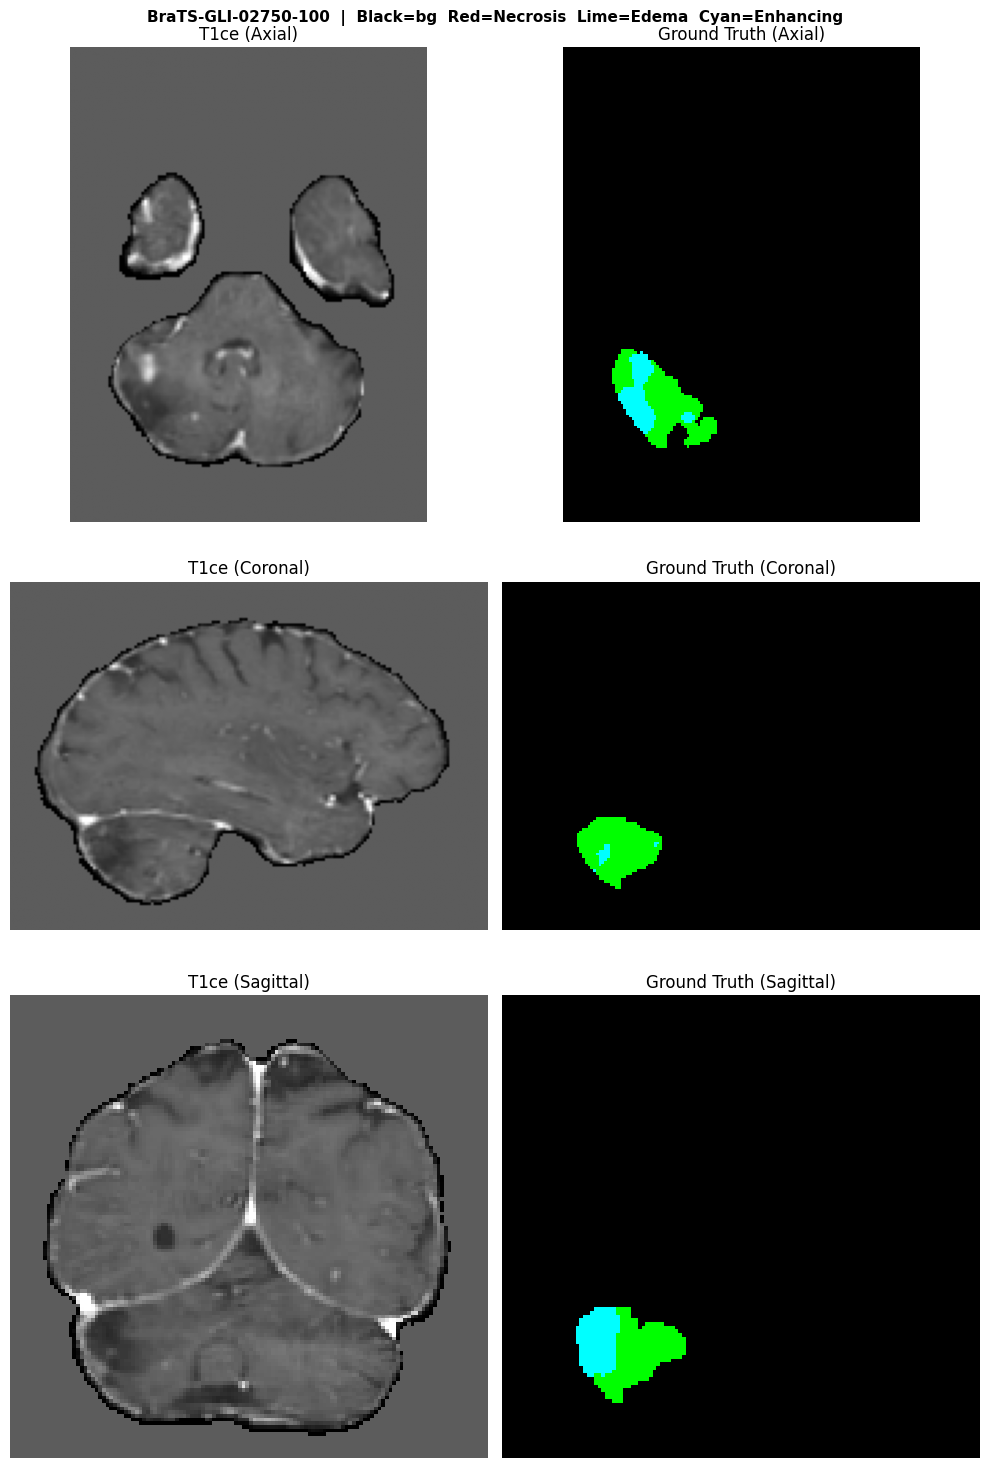

In [5]:
VIS_SLICES = "tumor"      # "tumor" = slices through the tumor centre, "center" = middle of the volume (old notebook)


def pick_center(shape, ref=None):
    if VIS_SLICES == "tumor" and ref is not None and (ref > 0).any():
        return tuple(int(round(c)) for c in ndi.center_of_mass(ref > 0))
    return tuple(s // 2 for s in shape)


def plot_three_views(img, gt, preds, titles, pid="", subtitle="", save_path=None):
    """img: (C,D,H,W) cached image; gt: (D,H,W) class map or None; preds: list of (D,H,W) class maps."""
    shape = img.shape[1:]
    ref = gt if gt is not None else (preds[0] if preds else None)
    i, j, k = pick_center(shape, ref)
    views = {"Axial": lambda a: a[:, :, k], "Coronal": lambda a: a[i, :, :], "Sagittal": lambda a: a[:, j, :]}
    t1ce = np.asarray(img[2], dtype=np.float32)
    cols = [("T1ce", None)] + ([("Ground Truth", gt)] if gt is not None else []) + list(zip(titles, preds))
    fig, axes = plt.subplots(3, len(cols), figsize=(5 * len(cols), 15))
    for r, (vname, take) in enumerate(views.items()):
        for c, (name, seg) in enumerate(cols):
            ax = axes[r, c]
            if seg is None:
                ax.imshow(np.rot90(take(t1ce)), cmap="gray")
            else:
                ax.imshow(np.rot90(take(seg)), cmap=SEG_CMAP, norm=SEG_NORM, interpolation="nearest")
            ax.set_title(f"{name} ({vname})")
            ax.axis("off")
    fig.suptitle(f"{pid}  |  {LEGEND}" + (f"\n{subtitle}" if subtitle else ""), fontsize=11, fontweight="bold")
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()


# sanity check (always do this once): do the colours sit where the tumor is, and is the label map sensible?
cid0 = train_ids[0]
meta0 = json.load(open(CACHE_DIR / f"{cid0}_meta.json"))
img0 = np.load(CACHE_DIR / f"{cid0}_img.npy", mmap_mode="r")
seg0 = np.load(CACHE_DIR / f"{cid0}_seg.npy")
print(f"{cid0}: original {meta0['shape']} -> cropped {list(img0.shape[1:])} | spacing (mm): {np.round(meta0['zooms'], 2).tolist()}")
for c, name in enumerate(CLASS_NAMES):
    print(f"   class {c} {name:<10}: {int((seg0 == c).sum()):>9,} voxels ({100 * (seg0 == c).mean():.3f}%)")
plot_three_views(img0, seg0, [], [], pid=cid0)

## Step 3: Patch dataset (the only thing the training loop ever sees)

`BratsPatches` reads a random `patch³` window straight from the memory-mapped cache. With probability `fg_prob` the window is centred (with jitter) on a random voxel of a **randomly chosen tumor class** (necrosis, edema or enhancing, each equally likely), which keeps the rare classes in every batch; otherwise it is uniform, so the network also sees healthy tissue. Augmentation is deliberately cheap: random flips, per-sequence intensity scale/shift and occasional Gaussian noise, all applied only to brain voxels so the background stays exactly 0. (Add rotations or elastic deformation with MONAI or TorchIO if you have CPU to spare.)

In [6]:
@lru_cache(maxsize=48)
def _mm(path):                     # memory-mapped arrays; a few stay open per process
    return np.load(path, mmap_mode="r")


@lru_cache(maxsize=256)
def _fg(path):                     # {class: (N,3) voxel coordinates} for the tumor classes present in this patient
    npz_path = Path(path)
    if npz_path.exists():
        with np.load(npz_path) as z:
            return {int(k[1:]): z[k] for k in z.files if len(z[k])}

    # Older caches stored one combined foreground-coordinate array as *_fg.npy.
    legacy_path = npz_path.with_suffix(".npy")
    if legacy_path.exists():
        pts = np.asarray(np.load(legacy_path, allow_pickle=False))
        if pts.ndim != 2 or pts.shape[1] != 3:
            raise ValueError(f"invalid foreground cache format: {legacy_path}")
        seg_path = npz_path.with_name(npz_path.name.replace("_fg.npz", "_seg.npy"))
        if seg_path.exists():
            labels = np.asarray(np.load(seg_path, mmap_mode="r")[tuple(pts.T)])
            return {int(c): pts[labels == c] for c in np.unique(labels) if c > 0 and (labels == c).any()}
        return {1: pts}

    return {}


class BratsPatches(Dataset):
    """Random patches (training) or a fixed, reproducible set of patches (validation, when `seed` is given)."""

    def __init__(self, ids, patch, length, fg_prob=0.33, augment=True, seed=None):
        self.ids, self.P, self.length = list(ids), patch, length
        self.fg_prob, self.augment, self.seed = fg_prob, augment, seed
        self._rng = None

    def __len__(self):
        return self.length

    def _rng_for(self, idx):
        if self.seed is not None:                          # validation: identical patches every time
            return np.random.default_rng(self.seed + idx)
        if self._rng is None:                              # training: one independent RNG per DataLoader worker
            self._rng = np.random.default_rng(torch.initial_seed() % 2 ** 32)
        return self._rng

    def __getitem__(self, idx):
        rng, P = self._rng_for(idx), self.P
        cid = self.ids[idx % len(self.ids)] if self.seed is not None else self.ids[rng.integers(len(self.ids))]
        img, seg = _mm(str(CACHE_DIR / f"{cid}_img.npy")), _mm(str(CACHE_DIR / f"{cid}_seg.npy"))
        shape = np.array(seg.shape)
        hi = np.maximum(shape - P, 0)
        start = None
        if rng.random() < self.fg_prob:                    # centre the patch on a voxel of a random tumor class (+ jitter)
            fg = _fg(str(CACHE_DIR / f"{cid}_fg.npz"))
            if fg:
                pts = fg[int(rng.choice(list(fg)))]
                centre = pts[rng.integers(len(pts))].astype(int) + rng.integers(-P // 4, P // 4 + 1, size=3)
                start = centre - P // 2
        if start is None:
            start = rng.integers(0, hi + 1)
        start = np.clip(start, 0, hi)
        sl = tuple(slice(int(s), int(min(s + P, n))) for s, n in zip(start, shape))
        x = np.asarray(img[(slice(None),) + sl], dtype=np.float32)
        y = np.asarray(seg[sl]).astype(np.int64)
        pad = [(0, P - s) for s in y.shape]                # volume smaller than the patch: zero-pad
        if any(p for _, p in pad):
            x, y = np.pad(x, [(0, 0)] + pad), np.pad(y, pad)
        if self.augment:
            for ax in range(3):
                if rng.random() < 0.5:
                    x, y = np.flip(x, ax + 1), np.flip(y, ax)
            brain = x != 0                                 # touch brain voxels only; background stays exactly 0
            scale = rng.uniform(0.9, 1.1, (x.shape[0], 1, 1, 1)).astype(np.float32)
            shift = rng.uniform(-0.1, 0.1, (x.shape[0], 1, 1, 1)).astype(np.float32)
            x = np.where(brain, x * scale + shift, 0.0)
            if rng.random() < 0.3:
                x = x + rng.normal(0, 0.03, x.shape).astype(np.float32) * brain
        return (torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)),
                torch.from_numpy(np.ascontiguousarray(y[None])))


# quick look at one batch: class balance of the sampled patches
_xb, _yb = next(iter(DataLoader(BratsPatches(train_ids, cfg.patch, 16, cfg.fg_prob), batch_size=16)))
print(f"batch x {tuple(_xb.shape)}, y {tuple(_yb.shape)} {_yb.dtype} | input mean/std: {_xb.mean().item():.2f} / {_xb.std().item():.2f}")
print("voxel share of each class in the sampled patches:",
      {n: f"{100 * (_yb == c).float().mean().item():.2f}%" for c, n in enumerate(CLASS_NAMES)})

batch x (16, 4, 96, 96, 96), y (16, 1, 96, 96, 96) torch.int64 | input mean/std: 0.03 / 0.85
voxel share of each class in the sampled patches: {'Background': '96.94%', 'Necrosis': '0.07%', 'Edema': '2.01%', 'Enhancing': '0.97%'}


## Step 4: The model, a lean 3D U-Net with 4 output classes

4 levels (`base`, 2·`base`, 4·`base`, 8·`base` channels), two `3×3×3 conv → InstanceNorm → LeakyReLU` per level, strided-conv downsampling, transposed-conv upsampling, concatenation skips, a **softmax over the 4 classes** and **deep supervision** (extra 1×1×1 heads at ½ and ¼ resolution during training). Activation memory is dominated by the full-resolution level (`C₀·V₀`), so the width of that level (`base`) is the main memory and compute knob.

Loss = cross-entropy + soft Dice over the three tumor classes (Dice is accumulated over the whole batch, because many patches lack some class), summed over the three output scales with weights ∝ 1/2ᵏ.

In [7]:
class ConvBlock(nn.Sequential):
    """(3x3x3 conv -> InstanceNorm -> LeakyReLU) x 2"""

    def __init__(self, cin, cout):
        layers = []
        for i in range(2):
            layers += [nn.Conv3d(cin if i == 0 else cout, cout, 3, padding=1, bias=False),
                       nn.InstanceNorm3d(cout, affine=True),
                       nn.LeakyReLU(0.01, inplace=True)]
        super().__init__(*layers)


class LeanUNet3D(nn.Module):
    def __init__(self, in_ch=4, out_ch=NUM_CLASSES, base=16, levels=4, deep_supervision=True, use_ckpt=False):
        super().__init__()
        ch = [base * 2 ** i for i in range(levels)]                      # e.g. 16-32-64-128
        self.levels, self.ds, self.use_ckpt, self.force_deep = levels, deep_supervision, use_ckpt, False
        self.enc = nn.ModuleList([ConvBlock(in_ch if i == 0 else ch[i - 1], ch[i]) for i in range(levels)])
        self.down = nn.ModuleList([nn.Conv3d(ch[i], ch[i], 2, stride=2, bias=False) for i in range(levels - 1)])
        rev = list(reversed(range(levels - 1)))                          # decoder levels, deepest first
        self.up = nn.ModuleList([nn.ConvTranspose3d(ch[i + 1], ch[i], 2, stride=2) for i in rev])
        self.dec = nn.ModuleList([ConvBlock(2 * ch[i], ch[i]) for i in rev])
        self.heads = nn.ModuleList([nn.Conv3d(ch[i], out_ch, 1) for i in rev])
        for m in self.modules():
            if isinstance(m, (nn.Conv3d, nn.ConvTranspose3d)):
                nn.init.kaiming_normal_(m.weight, a=0.01, nonlinearity="leaky_relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def _run(self, block, x):
        if self.use_ckpt and self.training:                              # recompute activations in backward
            return checkpoint(block, x, use_reentrant=False)
        return block(x)

    def forward(self, x):
        deep = self.ds and (self.training or self.force_deep)           # force_deep: also return all scales in eval mode
        skips = []
        for i in range(self.levels - 1):
            x = self._run(self.enc[i], x)
            skips.append(x)
            x = self.down[i](x)
        x = self._run(self.enc[-1], x)
        outs = []
        for j in range(self.levels - 1):                                 # deepest -> full resolution
            x = self.up[j](x)
            x = torch.cat([skips[self.levels - 2 - j], x], dim=1)
            x = self._run(self.dec[j], x)
            if deep:
                outs.append(self.heads[j](x))
        return outs[::-1] if deep else self.heads[-1](x)                 # [full, 1/2, 1/4] logits, or full-resolution logits


def dice_ce_loss(logits, target, weight=None, smooth=1e-5):
    """logits (B,C,D,H,W), target (B,D,H,W) int64. Cross-entropy + soft Dice over the tumor classes (batch-level)."""
    ce = F.cross_entropy(logits, target, weight=None if weight is None else weight.to(logits.device))
    p = torch.softmax(logits, dim=1)
    onehot = F.one_hot(target, logits.shape[1]).permute(0, 4, 1, 2, 3).to(p.dtype)
    dims = (0, 2, 3, 4)
    inter = (p * onehot).sum(dims)
    denom = p.sum(dims) + onehot.sum(dims)
    dice = (2 * inter + smooth) / (denom + smooth)
    return ce + (1 - dice[1:].mean())                                    # background is excluded from the Dice term


CE_WEIGHT_T = None if CE_WEIGHTS is None else torch.tensor(CE_WEIGHTS, dtype=torch.float32)


def deep_sup_loss(outs, target):
    """target: (B,1,D,H,W) int64. Weighted sum of the loss at every output scale."""
    outs = outs if isinstance(outs, (list, tuple)) else [outs]
    w = torch.tensor([0.5 ** k for k in range(len(outs))])
    w = (w / w.sum()).tolist()
    total = 0.0
    for wk, o in zip(w, outs):
        o = o.float()
        t = target if o.shape[2:] == target.shape[2:] else F.interpolate(target.float(), size=o.shape[2:], mode="nearest").long()
        total = total + wk * dice_ce_loss(o, t[:, 0], CE_WEIGHT_T)
    return total


def count_params(m):
    return sum(p.numel() for p in m.parameters())


_m = LeanUNet3D(4, NUM_CLASSES, cfg.base, cfg.levels, True, cfg.ckpt)
print(f"parameters: {count_params(_m) / 1e6:.2f} M  (~{count_params(_m) * 4 / 2 ** 20:.1f} MB in fp32)")
_x = torch.randn(1, 4, cfg.patch, cfg.patch, cfg.patch)
_m.train(); print("train-mode output shapes:", [tuple(o.shape[1:]) for o in _m(_x)])
_m.eval()
with torch.no_grad():
    print("eval-mode output shape:  ", tuple(_m(_x).shape[1:]))
del _m, _x

parameters: 1.45 M  (~5.5 MB in fp32)
train-mode output shapes: [(4, 96, 96, 96), (4, 48, 48, 48), (4, 24, 24, 24)]
eval-mode output shape:   (4, 96, 96, 96)


## Step 5: Benchmark one training step (optional but recommended)

Prints the time per step and, on a GPU, the peak memory, so you can tune `patch`, `base`, `batch_size`, `amp`, `ckpt` and `accum` *before* committing to a long run.

In [8]:
def benchmark(cfg, steps=4):
    use_amp = cfg.amp and DEVICE.type == "cuda"
    m = LeanUNet3D(4, NUM_CLASSES, cfg.base, cfg.levels, True, cfg.ckpt).to(DEVICE).train()
    opt, scaler = torch.optim.AdamW(m.parameters(), 1e-3), make_scaler(use_amp)
    x = torch.randn(cfg.batch_size, 4, *[cfg.patch] * 3, device=DEVICE)
    y = (torch.rand(cfg.batch_size, 1, *[cfg.patch] * 3, device=DEVICE) > 0.97).long() * torch.randint(1, NUM_CLASSES, (cfg.batch_size, 1, *[cfg.patch] * 3), device=DEVICE)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    times = []
    try:
        for _ in range(steps):
            t0 = time.time()
            opt.zero_grad(set_to_none=True)
            with amp_ctx(DEVICE, use_amp):
                outs = m(x)
            scaler.scale(deep_sup_loss(outs, y)).backward()
            scaler.step(opt); scaler.update()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            times.append(time.time() - t0)
    except RuntimeError as e:
        if "out of memory" not in str(e).lower():
            raise
        print("OUT OF MEMORY -> lower cfg.patch / cfg.base / cfg.batch_size, set cfg.ckpt = True, or use cfg.accum > 1")
        return
    t = float(np.median(times[1:])) if len(times) > 1 else times[0]
    peak = f" | peak GPU memory {torch.cuda.max_memory_allocated() / 2 ** 30:.2f} GB" if DEVICE.type == "cuda" else ""
    print(f"{t:.2f} s per micro-step (batch {cfg.batch_size}, patch {cfg.patch}³){peak}")
    print(f"=> {cfg.total_steps} optimizer steps x {cfg.accum} micro-step(s) is about {t * cfg.total_steps * cfg.accum / 60:.0f} min of training")
    del m, opt
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


benchmark(cfg)

0.18 s per micro-step (batch 2, patch 96³) | peak GPU memory 1.78 GB
=> 8000 optimizer steps x 1 micro-step(s) is about 24 min of training


## Step 6: Train

AdamW with a poly learning-rate decay `lr(t) = lr₀·(1 − t/T)^0.9`, gradient clipping at 12, optional fp16 autocast, gradient accumulation (`cfg.accum`), and checkpoint/resume (`ckpt/last.pt`; the best model by mean validation Dice goes to `ckpt/best.pt`). Validation uses a **fixed set of validation patches** (cheap) and reports the loss, the Dice of each class (necrosis / edema / enhancing) and the three BraTS regions (whole tumor = 1+2+3, tumor core = necrosis+enhancing, enhancing tumor); the proper full-scan evaluation happens in Step 8 on the held-out test patients.

Stop the cell any time and re-run it: training resumes from `last.pt`, which is written every `val_every` steps (set `RESUME = False` to start over). A `training_log.csv` with all curves is written next to the checkpoints.

In [10]:
HIST_KEYS = ["step", "loss", "val_step", "val_loss", "val_dice_mean", "val_dice_necrosis", "val_dice_edema",
             "val_dice_enhancing", "val_wt", "val_tc", "val_et"]
REGIONS = {"wt": lambda t: t > 0, "tc": lambda t: (t == 1) | (t == 3), "et": lambda t: t == 3}


@torch.no_grad()
def validate(model, loader, use_amp):
    model.eval(); model.force_deep = True                # force_deep: also get all output scales -> same loss as in training
    tot, n = 0.0, 0
    inter, psum, gsum = (np.zeros(NUM_CLASSES) for _ in range(3))
    reg = {k: np.zeros(3) for k in REGIONS}
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with amp_ctx(DEVICE, use_amp):
            outs = model(x)
        tot += deep_sup_loss(outs, y).item() * x.shape[0]; n += x.shape[0]
        pred, gt = outs[0].float().argmax(1), y[:, 0]
        for c in range(1, NUM_CLASSES):
            p, g = pred == c, gt == c
            inter[c] += (p & g).sum().item(); psum[c] += p.sum().item(); gsum[c] += g.sum().item()
        for k, f in REGIONS.items():
            p, g = f(pred), f(gt)
            reg[k] += [(p & g).sum().item(), p.sum().item(), g.sum().item()]
    model.force_deep = False; model.train()
    dice = lambda i, p, g: 2 * i / (p + g) if (p + g) > 0 else float("nan")      # nan = class absent from the validation patches
    out = {"loss": tot / max(n, 1)}
    for c in range(1, NUM_CLASSES):
        out[CLASS_NAMES[c].lower()] = dice(inter[c], psum[c], gsum[c])
    vals = np.array([out[c.lower()] for c in FORE_CLASSES])
    out["mean"] = float(np.nanmean(vals)) if np.isfinite(vals).any() else 0.0
    for k, v in reg.items():
        out[k] = dice(*v)
    return out


def train(cfg, train_ids, val_ids, resume=True):
    use_amp = cfg.amp and DEVICE.type == "cuda"
    model = LeanUNet3D(4, NUM_CLASSES, cfg.base, cfg.levels, True, cfg.ckpt).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(1.0 - s / cfg.total_steps, 0.0) ** 0.9)   # poly decay
    scaler = make_scaler(use_amp)
    step, best, hist = 0, -1.0, {k: [] for k in HIST_KEYS}
    last = CKPT_DIR / "last.pt"
    if resume and last.exists():
        ck = load_ckpt(last)
        checkpoint_state = ck.get("model", {})
        current_state = model.state_dict()
        incompatible = [
            key for key, value in current_state.items()
            if key not in checkpoint_state or checkpoint_state[key].shape != value.shape
        ]
        unexpected = [key for key in checkpoint_state if key not in current_state]
        if incompatible or unexpected:
            details = ", ".join(incompatible[:3] + unexpected[:3])
            print(f"checkpoint {last} is incompatible with the current {NUM_CLASSES}-class model ({details}); starting a new run")
        else:
            model.load_state_dict(checkpoint_state); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            scaler.load_state_dict(ck["scaler"]); step, best, hist = ck["step"], ck["best"], ck["hist"]
            print(f"resumed from step {step} (best mean validation Dice so far {best:.3f})")

    ds = BratsPatches(train_ids, cfg.patch, cfg.steps_per_epoch * cfg.accum * cfg.batch_size, cfg.fg_prob, augment=True)
    dl = DataLoader(ds, batch_size=cfg.batch_size, num_workers=cfg.num_workers, drop_last=True,
                    pin_memory=DEVICE.type == "cuda", persistent_workers=cfg.num_workers > 0)
    vdl = DataLoader(BratsPatches(val_ids, cfg.patch, cfg.val_patches, cfg.fg_prob, augment=False, seed=1234),
                     batch_size=cfg.batch_size, num_workers=0)

    def save(path):
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "step": step, "best": best, "hist": hist, "cfg": asdict(cfg)}, path)

    model.train()
    micro, run, t0, start_step = 0, [], time.time(), step
    while step < cfg.total_steps:
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with amp_ctx(DEVICE, use_amp):
                outs = model(x)
            loss = deep_sup_loss(outs, y)
            scaler.scale(loss / cfg.accum).backward()
            run.append(loss.item())
            micro += 1
            if micro % cfg.accum:
                continue                                   # keep accumulating gradients
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 12.0)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step()
            step += 1
            if step % cfg.log_every == 0:
                hist["step"].append(step); hist["loss"].append(float(np.mean(run))); run = []
                el = time.time() - t0
                eta = el / (step - start_step) * (cfg.total_steps - step)
                print(f"step {step:5d}/{cfg.total_steps} | loss {hist['loss'][-1]:.4f} | lr {sched.get_last_lr()[0]:.2e} | {el / 60:.1f} min elapsed, ~{eta / 60:.1f} min left")
            if step % cfg.val_every == 0 or step == cfg.total_steps:
                d = validate(model, vdl, use_amp)
                hist["val_step"].append(step); hist["val_loss"].append(float(d["loss"])); hist["val_dice_mean"].append(float(d["mean"]))
                for c in FORE_CLASSES:
                    hist[f"val_dice_{c.lower()}"].append(float(d[c.lower()]))
                for k in REGIONS:
                    hist[f"val_{k}"].append(float(d[k]))
                if d["mean"] > best:
                    best = d["mean"]
                    save(CKPT_DIR / "best.pt")
                save(CKPT_DIR / "last.pt")
                print(f"   validation: loss {d['loss']:.4f} | Dice necrosis {d['necrosis']:.3f}, edema {d['edema']:.3f}, enhancing {d['enhancing']:.3f} "
                      f"| mean {d['mean']:.3f} (best {best:.3f}) | WT {d['wt']:.3f}, TC {d['tc']:.3f}, ET {d['et']:.3f}")
            if step >= cfg.total_steps:
                break
    return model, hist


RESUME = True
model, hist = train(cfg, train_ids, val_ids, resume=RESUME)
pd.DataFrame({k: pd.Series(v) for k, v in hist.items()}).to_csv(CKPT_DIR / "training_log.csv", index=False)

checkpoint brats_work\ckpt\last.pt is incompatible with the current 4-class model (heads.0.weight, heads.0.bias, heads.1.weight); starting a new run
step    25/8000 | loss 2.1110 | lr 9.97e-04 | 0.2 min elapsed, ~76.9 min left
step    50/8000 | loss 1.6350 | lr 9.94e-04 | 0.5 min elapsed, ~80.7 min left
step    75/8000 | loss 1.4377 | lr 9.92e-04 | 0.8 min elapsed, ~82.3 min left
step   100/8000 | loss 1.2702 | lr 9.89e-04 | 1.1 min elapsed, ~83.3 min left
step   125/8000 | loss 1.1835 | lr 9.86e-04 | 1.3 min elapsed, ~83.4 min left
step   150/8000 | loss 1.1222 | lr 9.83e-04 | 1.6 min elapsed, ~83.2 min left
step   175/8000 | loss 1.0726 | lr 9.80e-04 | 1.9 min elapsed, ~83.4 min left
step   200/8000 | loss 1.0096 | lr 9.77e-04 | 2.1 min elapsed, ~82.9 min left
step   225/8000 | loss 0.9503 | lr 9.75e-04 | 2.4 min elapsed, ~83.0 min left
step   250/8000 | loss 0.8945 | lr 9.72e-04 | 2.7 min elapsed, ~82.7 min left
step   275/8000 | loss 0.8940 | lr 9.69e-04 | 2.9 min elapsed, ~82.0 mi

## Step 7: Sliding-window inference

The whole scan never goes through the network. With window size `p`, stride `s = p·(1 − overlap)` and scan length `L` along an axis:

```
N      = ceil((L - p) / s) + 1                 windows per axis
start  = min(k·s, L - p)                       last window is pushed back so it ends flush with the scan
w(x)   = exp(-|x - centre|² / 2σ²),  σ = p/8   Gaussian importance map: trust window centres, not borders
P(x)   = Σ_k w_k(x)·P_k(x) / Σ_k w_k(x)        blended class probabilities (softmax of each window)
```

Implementation notes: the fp32 accumulators (`prob_sum` for the 4 classes, `weight_sum`) live in RAM, so only one window batch is ever on the GPU; weights are clamped at 1e-6 because corner weights underflow in fp16; windows with almost no brain are skipped (those voxels are background); optional flip test-time augmentation averages up to 4 views per window. The self-test below checks the stitching math without any model: if every window just returns its input, the stitched output must reproduce the input exactly.

In [11]:
def window_starts(L, p, stride):
    """Start index of every window along one axis; the last window is pushed back so it ends flush with the scan."""
    if L <= p:
        return [0]
    n = math.ceil((L - p) / stride) + 1
    return sorted({min(k * stride, L - p) for k in range(n)})


def count_windows(shape, p, overlap):
    stride = max(1, int(p * (1 - overlap)))
    return int(np.prod([len(window_starts(s, p, stride)) for s in shape]))


def gaussian_map(p, sigma_scale=1 / 8):
    ax = np.arange(p) - (p - 1) / 2
    g = np.exp(-ax ** 2 / (2 * (p * sigma_scale) ** 2))
    w = g[:, None, None] * g[None, :, None] * g[None, None, :]
    return np.maximum(w / w.max(), 1e-6).astype(np.float32)


def make_predict_fn(model, use_amp=False):
    model.eval()

    def fn(x):
        with amp_ctx(DEVICE, use_amp):
            logits = model(x)
        return torch.softmax(logits.float(), dim=1)           # (B, 4, p, p, p) class probabilities
    return fn


@torch.no_grad()
def sliding_window_predict(img, predict_fn, patch, overlap=0.5, sw_batch=1, brain=None,
                           min_brain_frac=0.01, flips=((),), device=None, n_classes=NUM_CLASSES):
    """img: (C,D,H,W) array (a memmap is fine). predict_fn: tensor (B,C,p,p,p) -> class probabilities (B,n_classes,p,p,p).
    Returns the stitched class-probability map (n_classes,D,H,W) as float32."""
    device = device or DEVICE
    C, D, H, W = img.shape
    P = patch
    if min(D, H, W) < P:                                   # tiny volume: zero-pad up to one window
        padw = [(0, 0)] + [(0, max(P - s, 0)) for s in (D, H, W)]
        img = np.pad(np.asarray(img, dtype=np.float32), padw)
        brain = None if brain is None else np.pad(brain, padw[1:])
    shape = img.shape[1:]
    stride = max(1, int(P * (1 - overlap)))
    coords = [(z, y, x) for z in window_starts(shape[0], P, stride)
              for y in window_starts(shape[1], P, stride)
              for x in window_starts(shape[2], P, stride)]
    if brain is not None:                                  # skip windows with (almost) no brain
        coords = [c for c in coords if brain[c[0]:c[0] + P, c[1]:c[1] + P, c[2]:c[2] + P].mean() >= min_brain_frac]
    wmap = gaussian_map(P)
    wmap_t = torch.from_numpy(wmap).to(device)
    prob, wsum = np.zeros((n_classes,) + shape, np.float32), np.zeros(shape, np.float32)
    for i in range(0, len(coords), sw_batch):
        batch = coords[i:i + sw_batch]
        xb = np.stack([np.asarray(img[:, z:z + P, y:y + P, x:x + P], dtype=np.float32) for z, y, x in batch])
        xb = torch.from_numpy(xb).to(device)
        acc = 0
        for fl in flips:                                   # optional flip test-time augmentation
            dims = [d + 2 for d in fl]
            out = predict_fn(torch.flip(xb, dims) if fl else xb)
            acc = acc + (torch.flip(out, dims) if fl else out)
        pb = ((acc / len(flips)) * wmap_t).cpu().numpy()   # Gaussian importance weighting, (B, n_classes, P, P, P)
        for (z, y, x), p_ in zip(batch, pb):
            prob[:, z:z + P, y:y + P, x:x + P] += p_
            wsum[z:z + P, y:y + P, x:x + P] += wmap
    out = np.divide(prob, wsum, out=np.zeros_like(prob), where=wsum > 0)
    out[0][wsum == 0] = 1.0                                # voxels never visited (skipped empty windows) = background
    return out[:, :D, :H, :W]


# ---- self-test of the stitching code (no model needed): identity "network" on a 4-channel volume
_vol = np.random.default_rng(0).random((4, 150, 170, 130), dtype=np.float32)
for _ov in (0.5, 0.25, 0.0):
    _rec = sliding_window_predict(_vol, lambda x: x, patch=64, overlap=_ov, device=torch.device("cpu"))
    assert np.allclose(_rec, _vol, atol=1e-5), f"stitching is broken at overlap={_ov}"
print("stitching self-test passed")
print("windows for a 160x192x144 brain box with a 96³ patch:", {f"{int(o * 100)}% overlap": count_windows((160, 192, 144), 96, o) for o in (0.5, 0.25, 0.0)})

stitching self-test passed
windows for a 160x192x144 brain box with a 96³ patch: {'50% overlap': 18, '25% overlap': 12, '0% overlap': 8}


## Step 8: Inference on held-out patients: segmentation figures and metrics

For each test patient: sliding-window prediction → argmax → **post-processing** (remove anything outside the brain, drop tiny islands and keep the largest connected tumor component; the old notebook kept the largest component of every class, here it is the whole tumor so necrosis and enhancing tissue inside the tumor are never deleted) → the same metrics as your old notebook (DSC, HD95, ASD, precision, recall per class) → the 3-view figure (**T1ce · ground truth · raw prediction · post-processed prediction**, colours black / red / lime / cyan) → the label map written as `.nii.gz` into `predictions/` with the BraTS label values 0 / 1 / 2 / 4. Masks are saved in RAS orientation with the scan's world coordinates, so any viewer (ITK-SNAP, 3D Slicer) overlays them correctly on the original scan.

`all_mets` collects everything the graphs in Step 10 need, so run this cell before Step 10.

loaded best.pt: step 7000, mean validation Dice 0.848, patch 96³

[1/10] BraTS-GLI-02623-101
  sliding window: 12 windows, 1.4 s

------------------------------------------------------------
  Patient: BraTS-GLI-02623-101
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis       0.0000        inf       inf   0.0000      nan
  Edema          0.0000     87.664    75.654   0.0000   0.0000
  Enhancing      0.0000     81.794    77.373   0.0000   0.0000


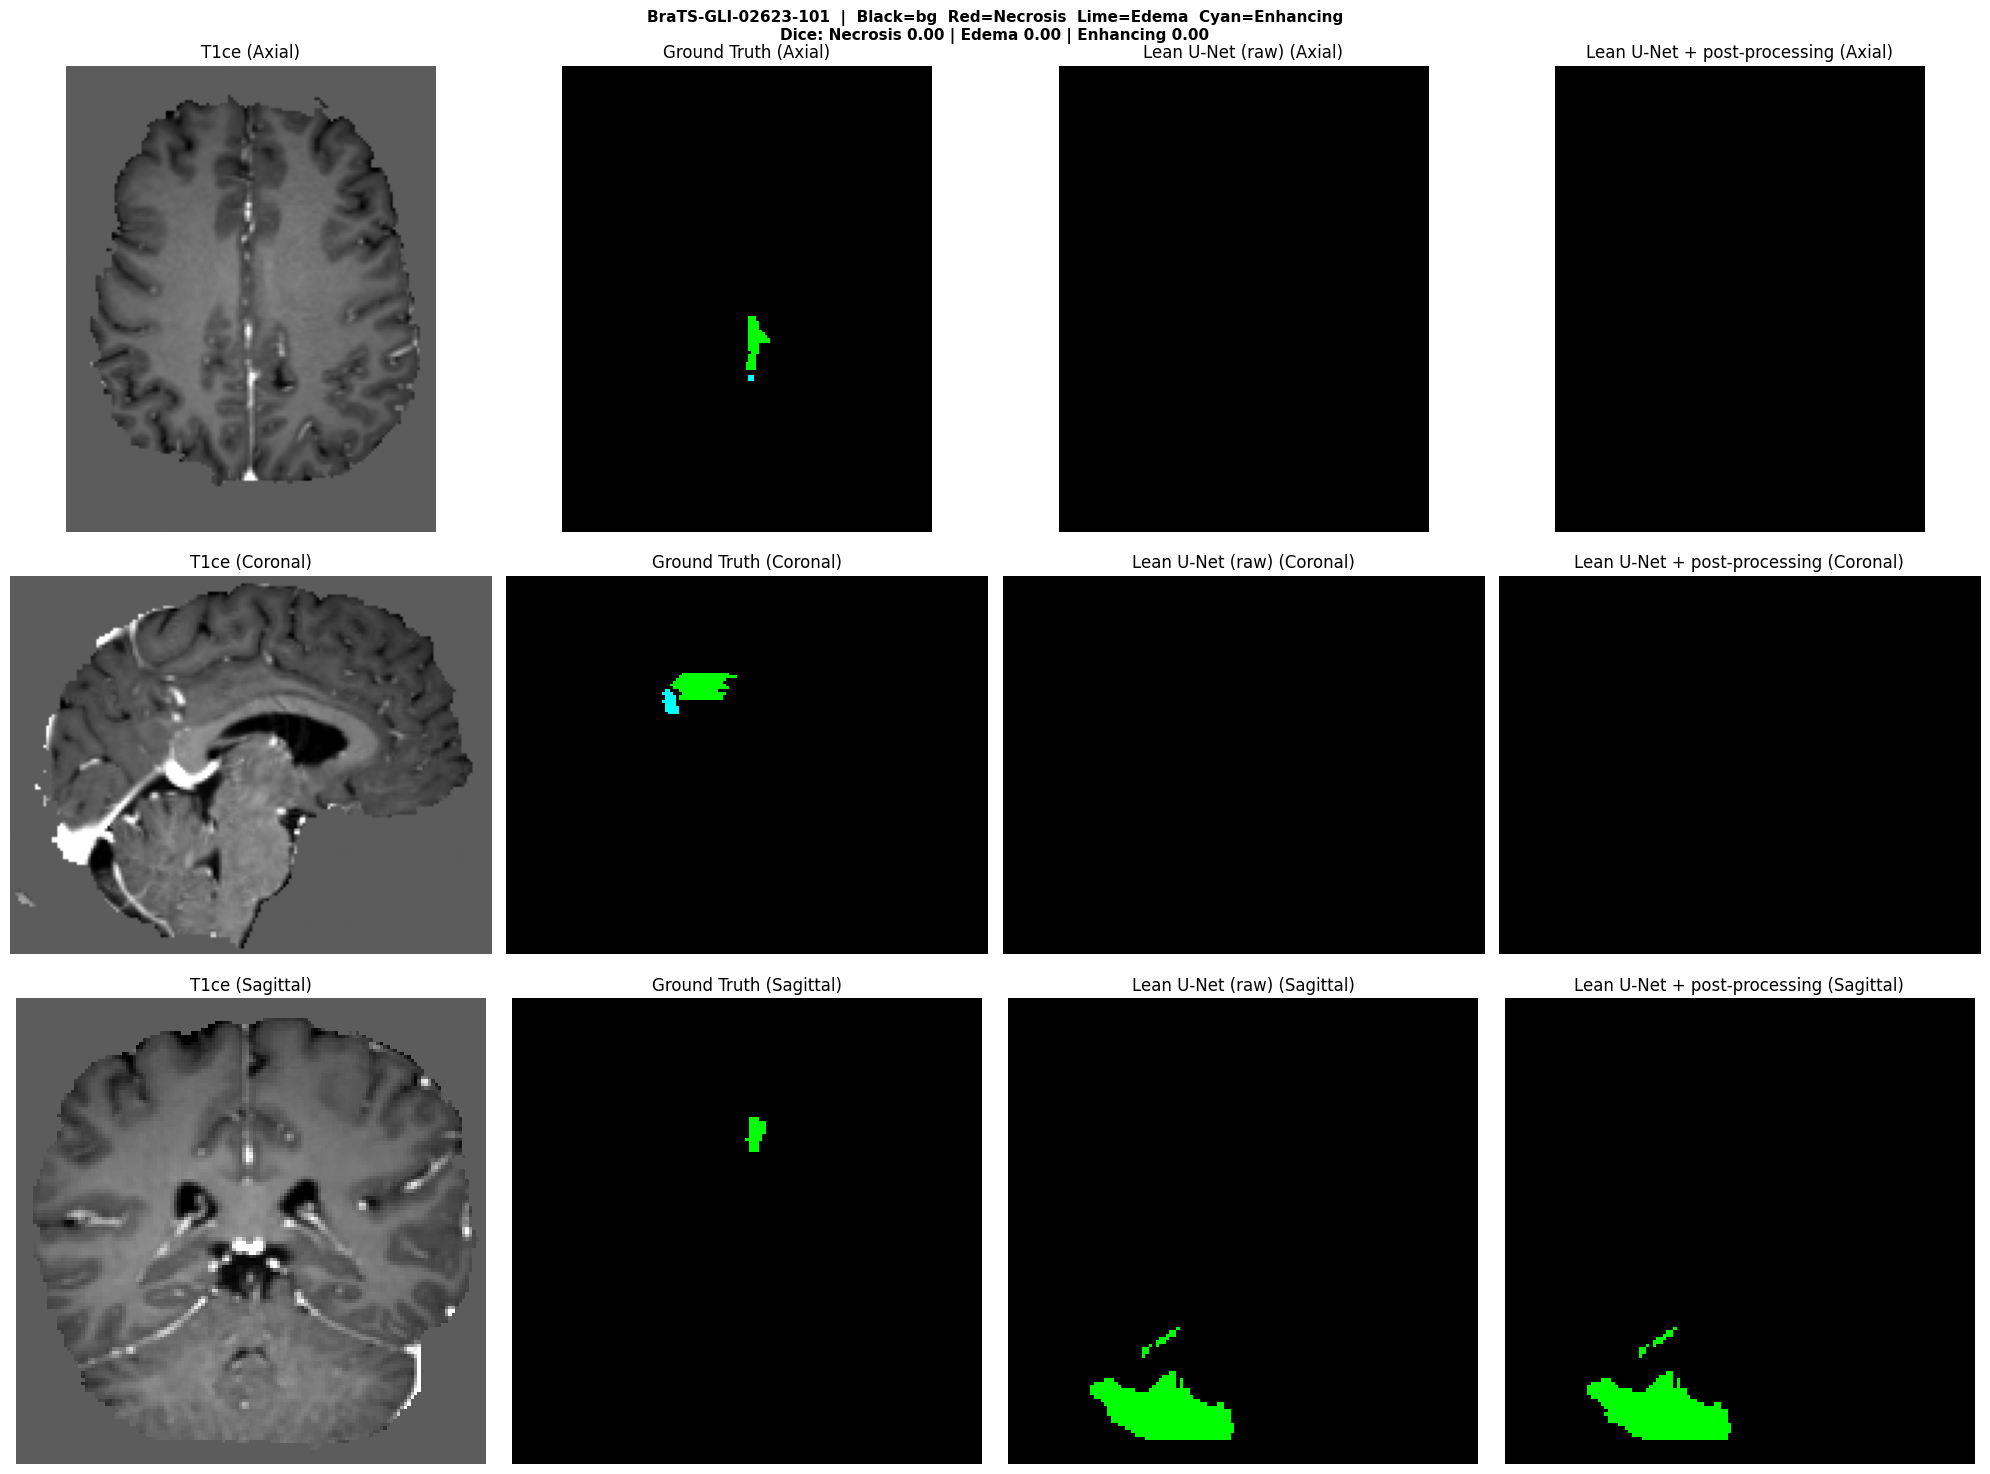


[2/10] BraTS-GLI-02131-101
  sliding window: 18 windows, 1.8 s

------------------------------------------------------------
  Patient: BraTS-GLI-02131-101
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis          nan      0.000     0.000      nan      nan
  Edema          0.8208      7.493     1.492   0.8779   0.7707
  Enhancing      0.7781      3.000     1.118   0.9054   0.6822


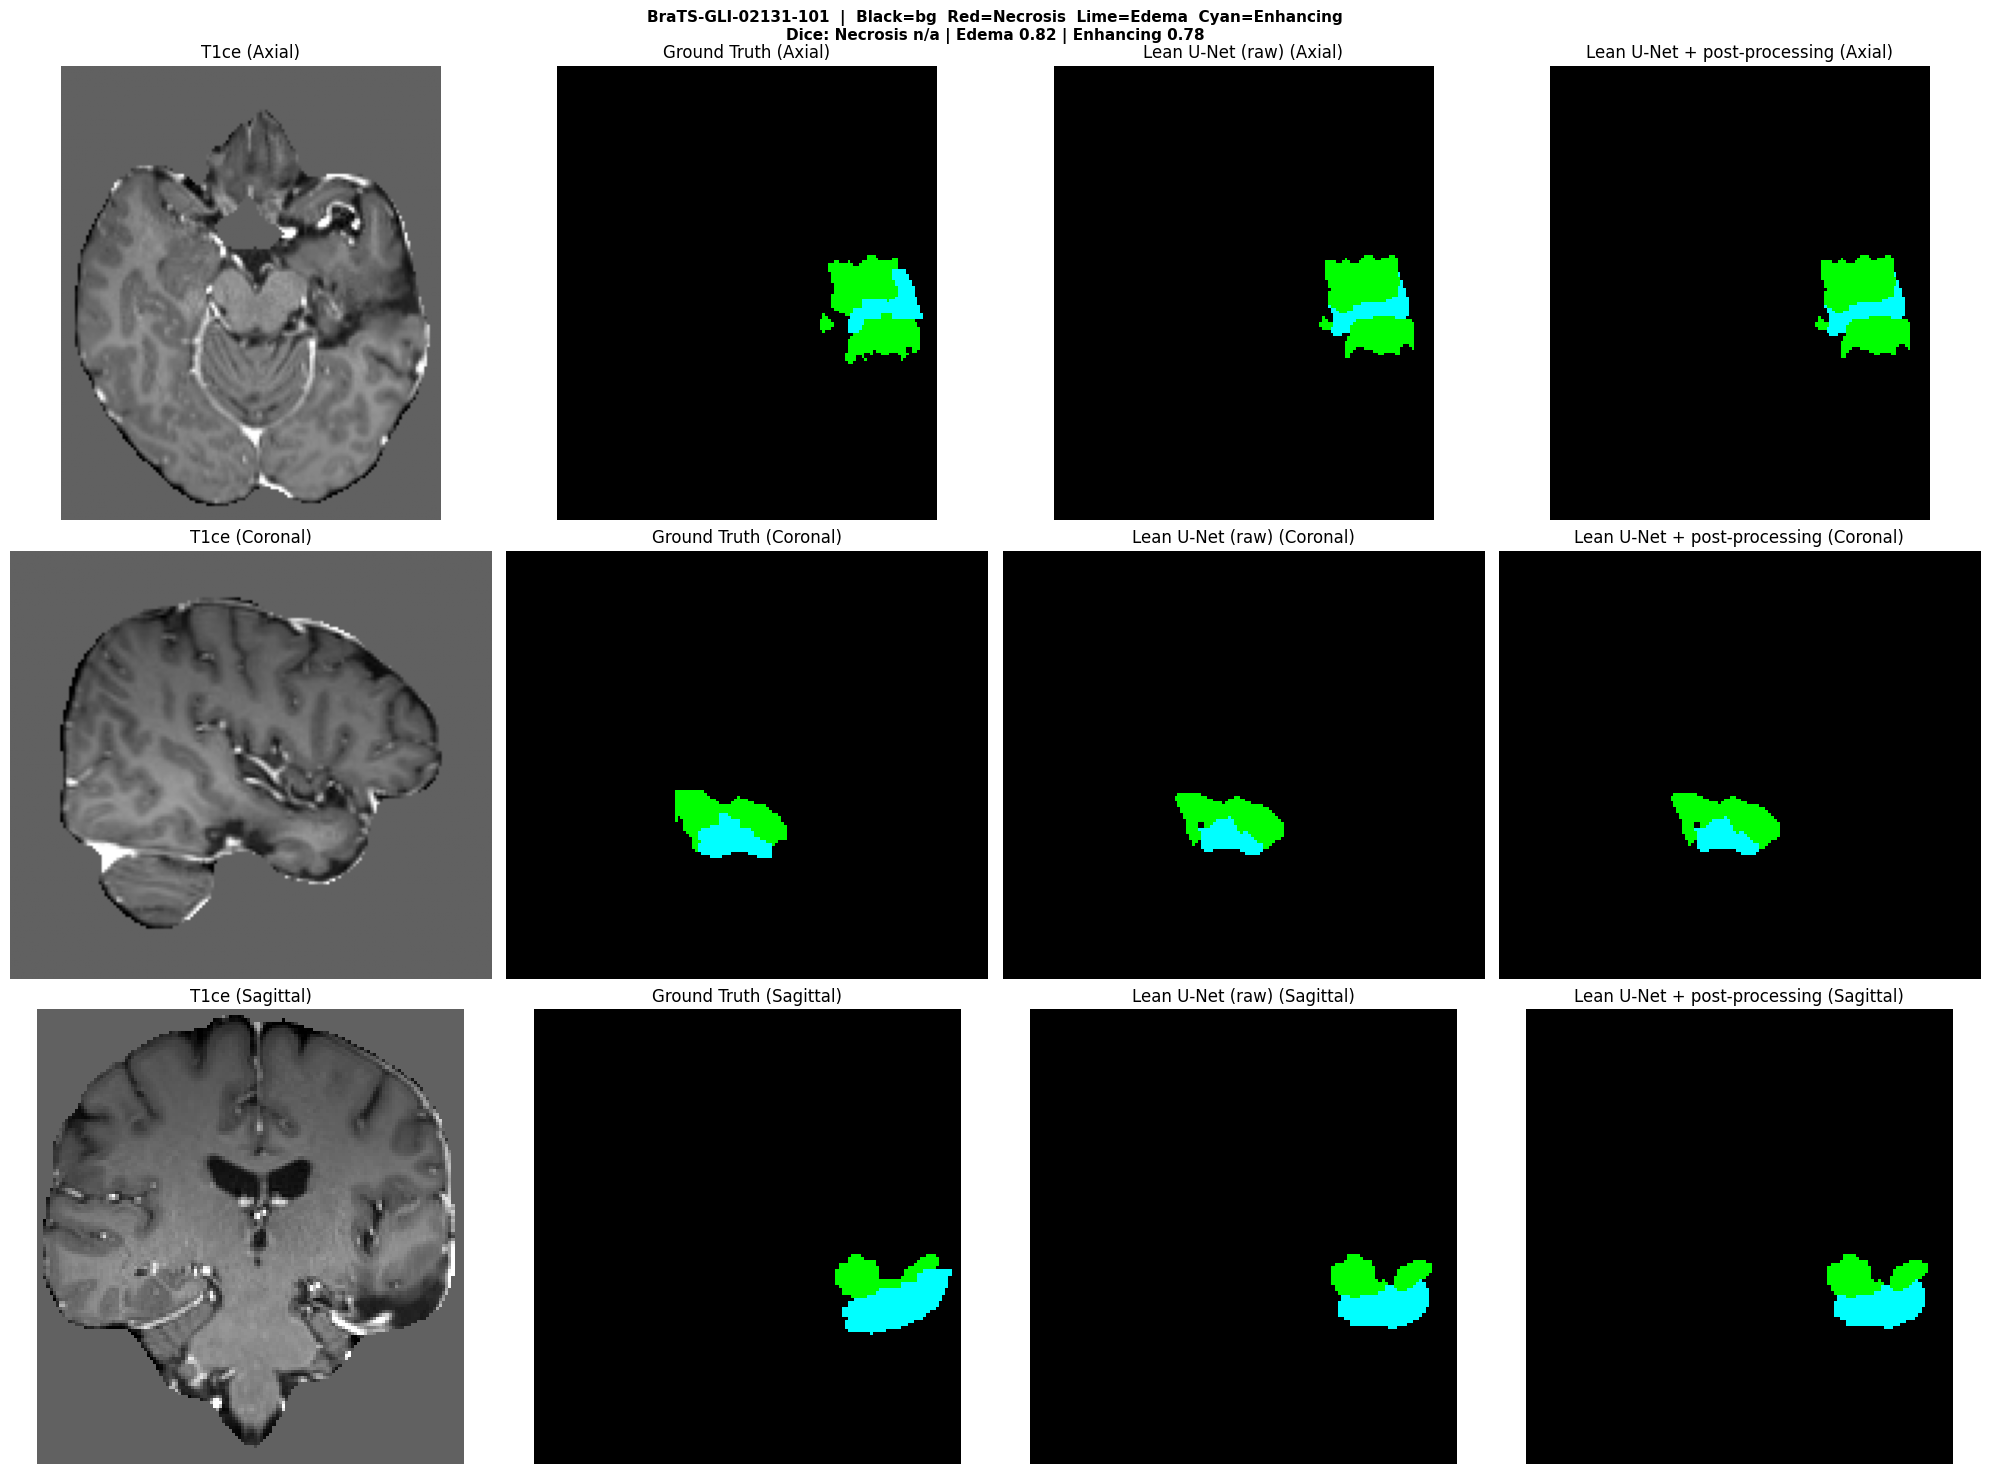


[3/10] BraTS-GLI-02740-101
  sliding window: 12 windows, 1.5 s

------------------------------------------------------------
  Patient: BraTS-GLI-02740-101
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis       0.5636      7.259     1.930   0.9544   0.3999
  Edema          0.9227      1.732     0.530   0.9585   0.8894
  Enhancing      0.6969      3.000     0.827   0.6930   0.7009


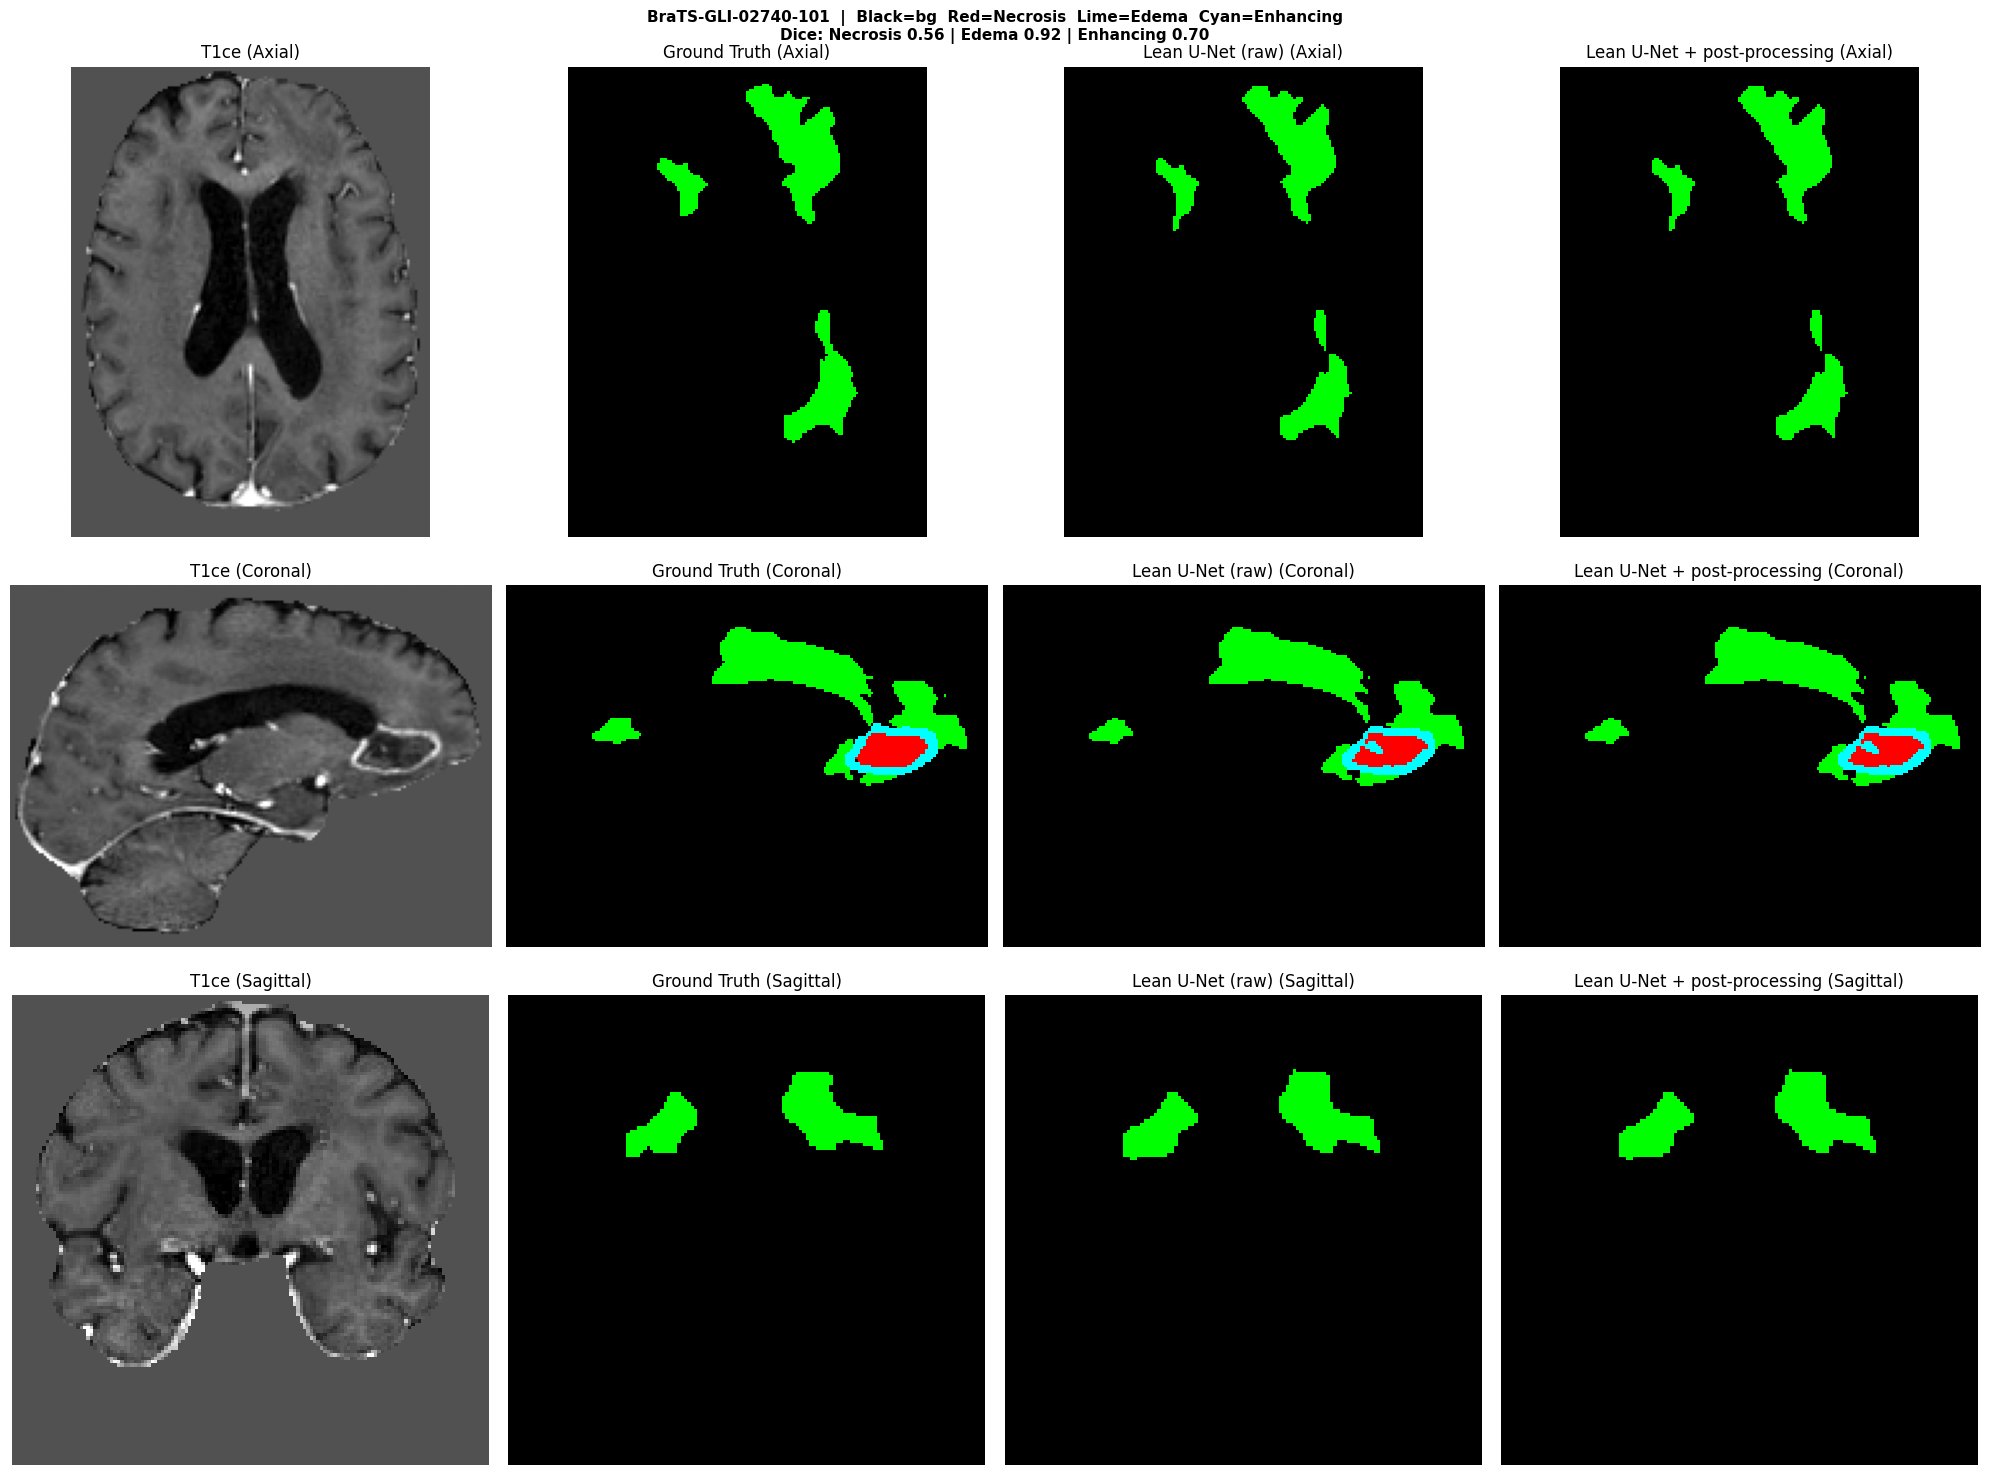


[4/10] BraTS-GLI-02087-101
  sliding window: 27 windows, 2.9 s

------------------------------------------------------------
  Patient: BraTS-GLI-02087-101
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis       0.8333     79.740     5.942   0.9178   0.7630
  Edema          0.9341      1.414     0.500   0.9074   0.9625
  Enhancing      0.9380     64.003     4.576   0.9665   0.9112


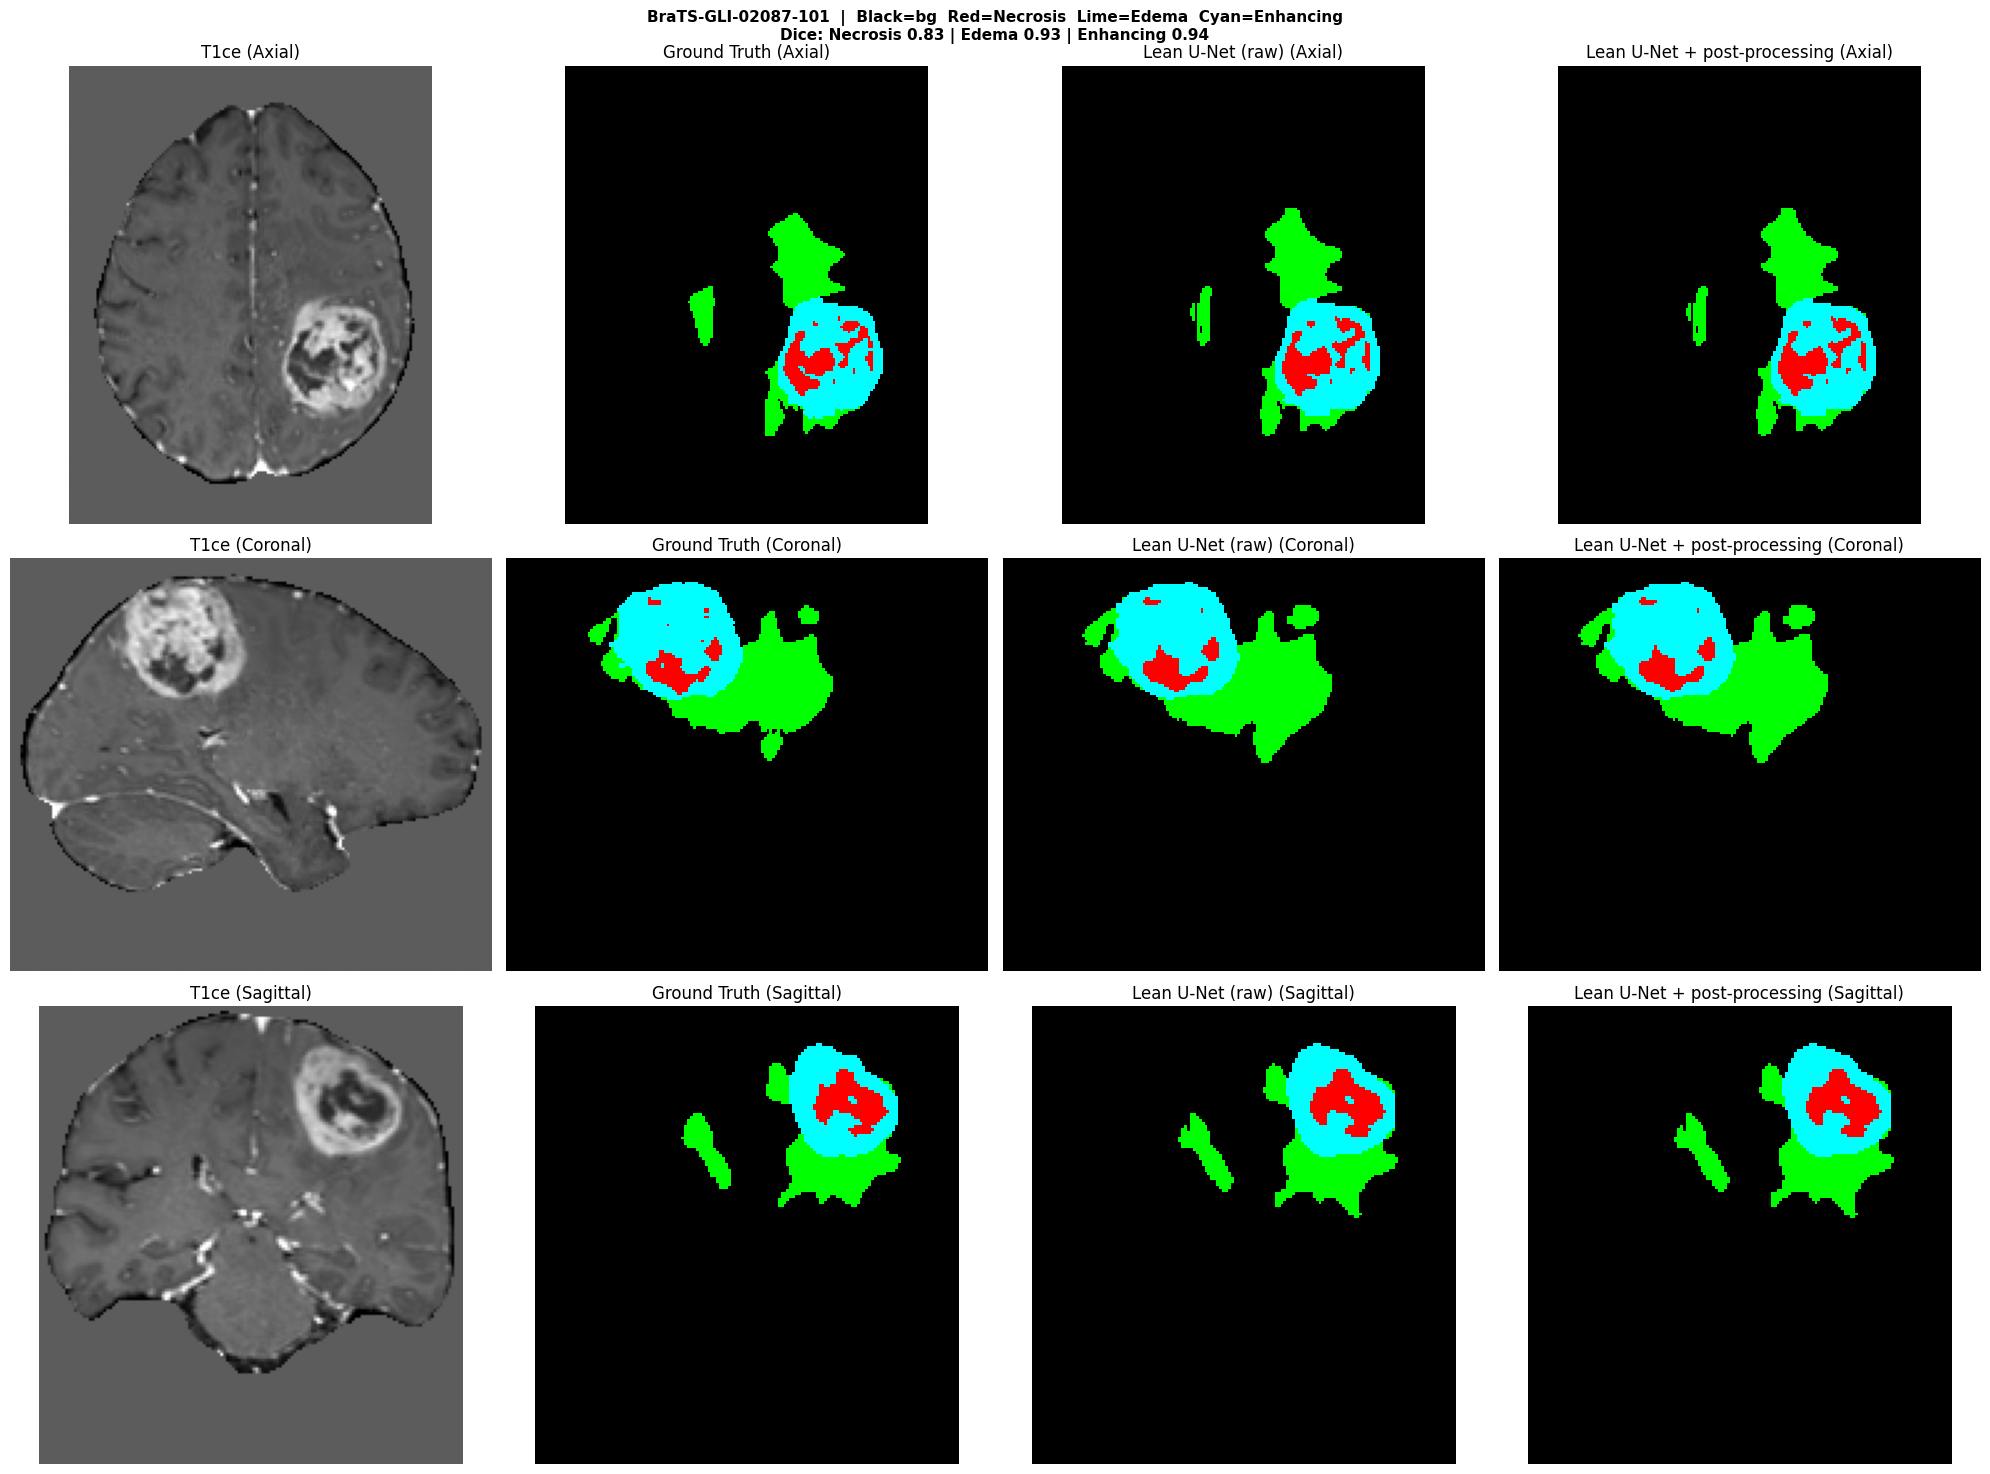


[5/10] BraTS-GLI-02890-100
  sliding window: 18 windows, 1.8 s

------------------------------------------------------------
  Patient: BraTS-GLI-02890-100
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis       0.6309     51.744     9.848   0.5281   0.7833
  Edema          0.6797      6.000     1.501   0.5874   0.8065
  Enhancing      0.8737      5.477     1.590   0.9466   0.8113


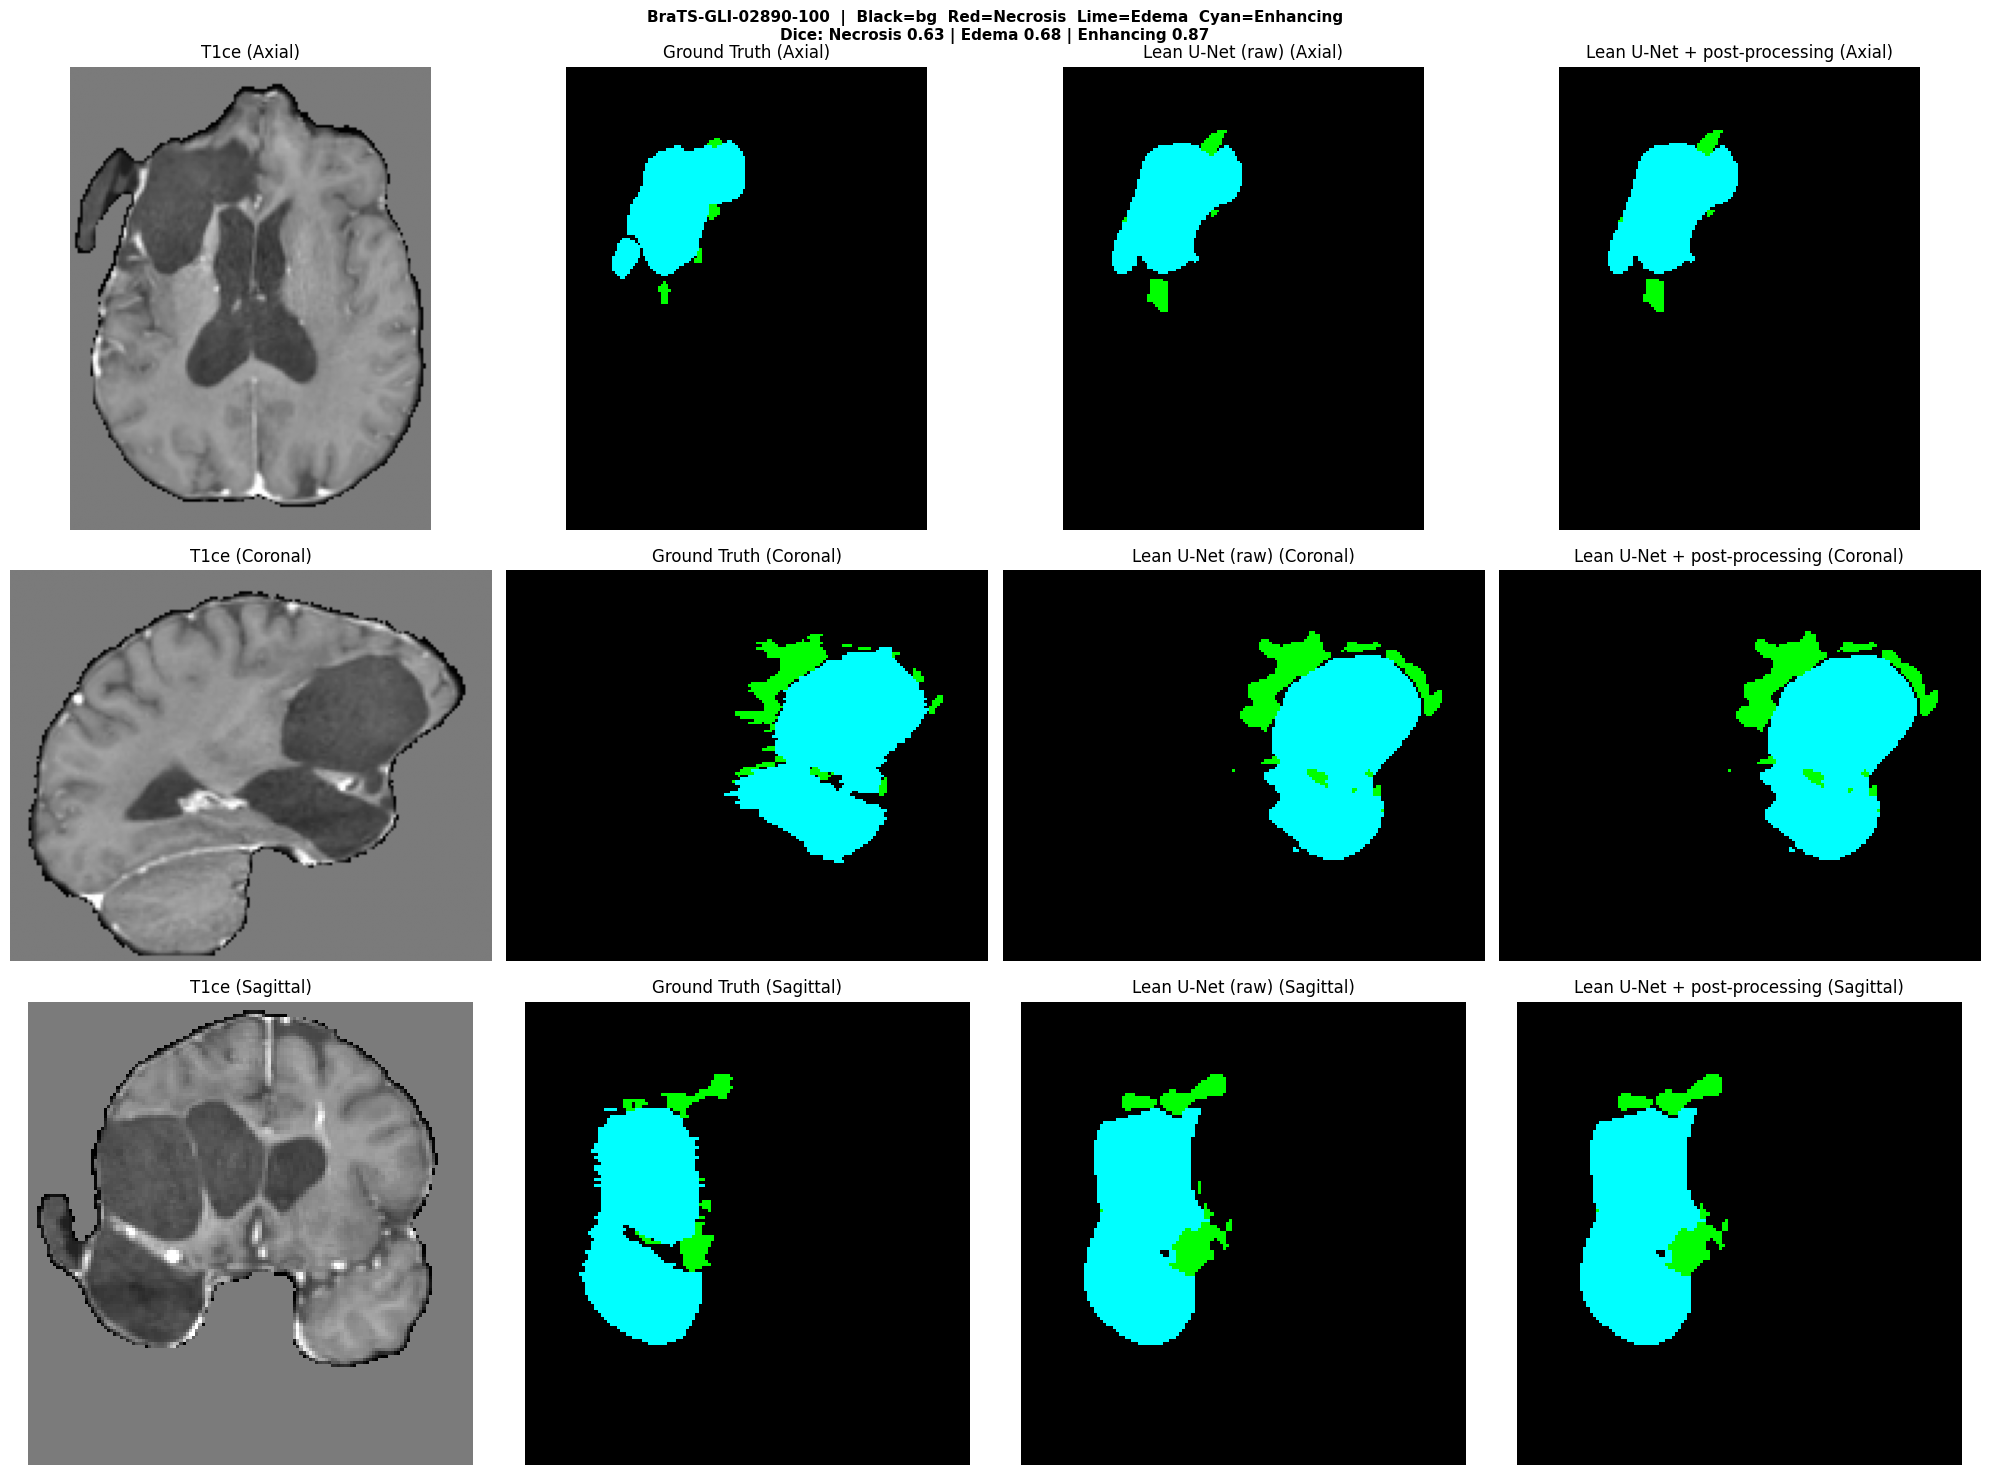


[6/10] BraTS-GLI-02780-100
  sliding window: 27 windows, 2.1 s

------------------------------------------------------------
  Patient: BraTS-GLI-02780-100
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis          nan      0.000     0.000      nan      nan
  Edema          0.8889      1.732     0.561   0.8869   0.8909
  Enhancing      0.9190      1.732     0.599   0.9398   0.8992


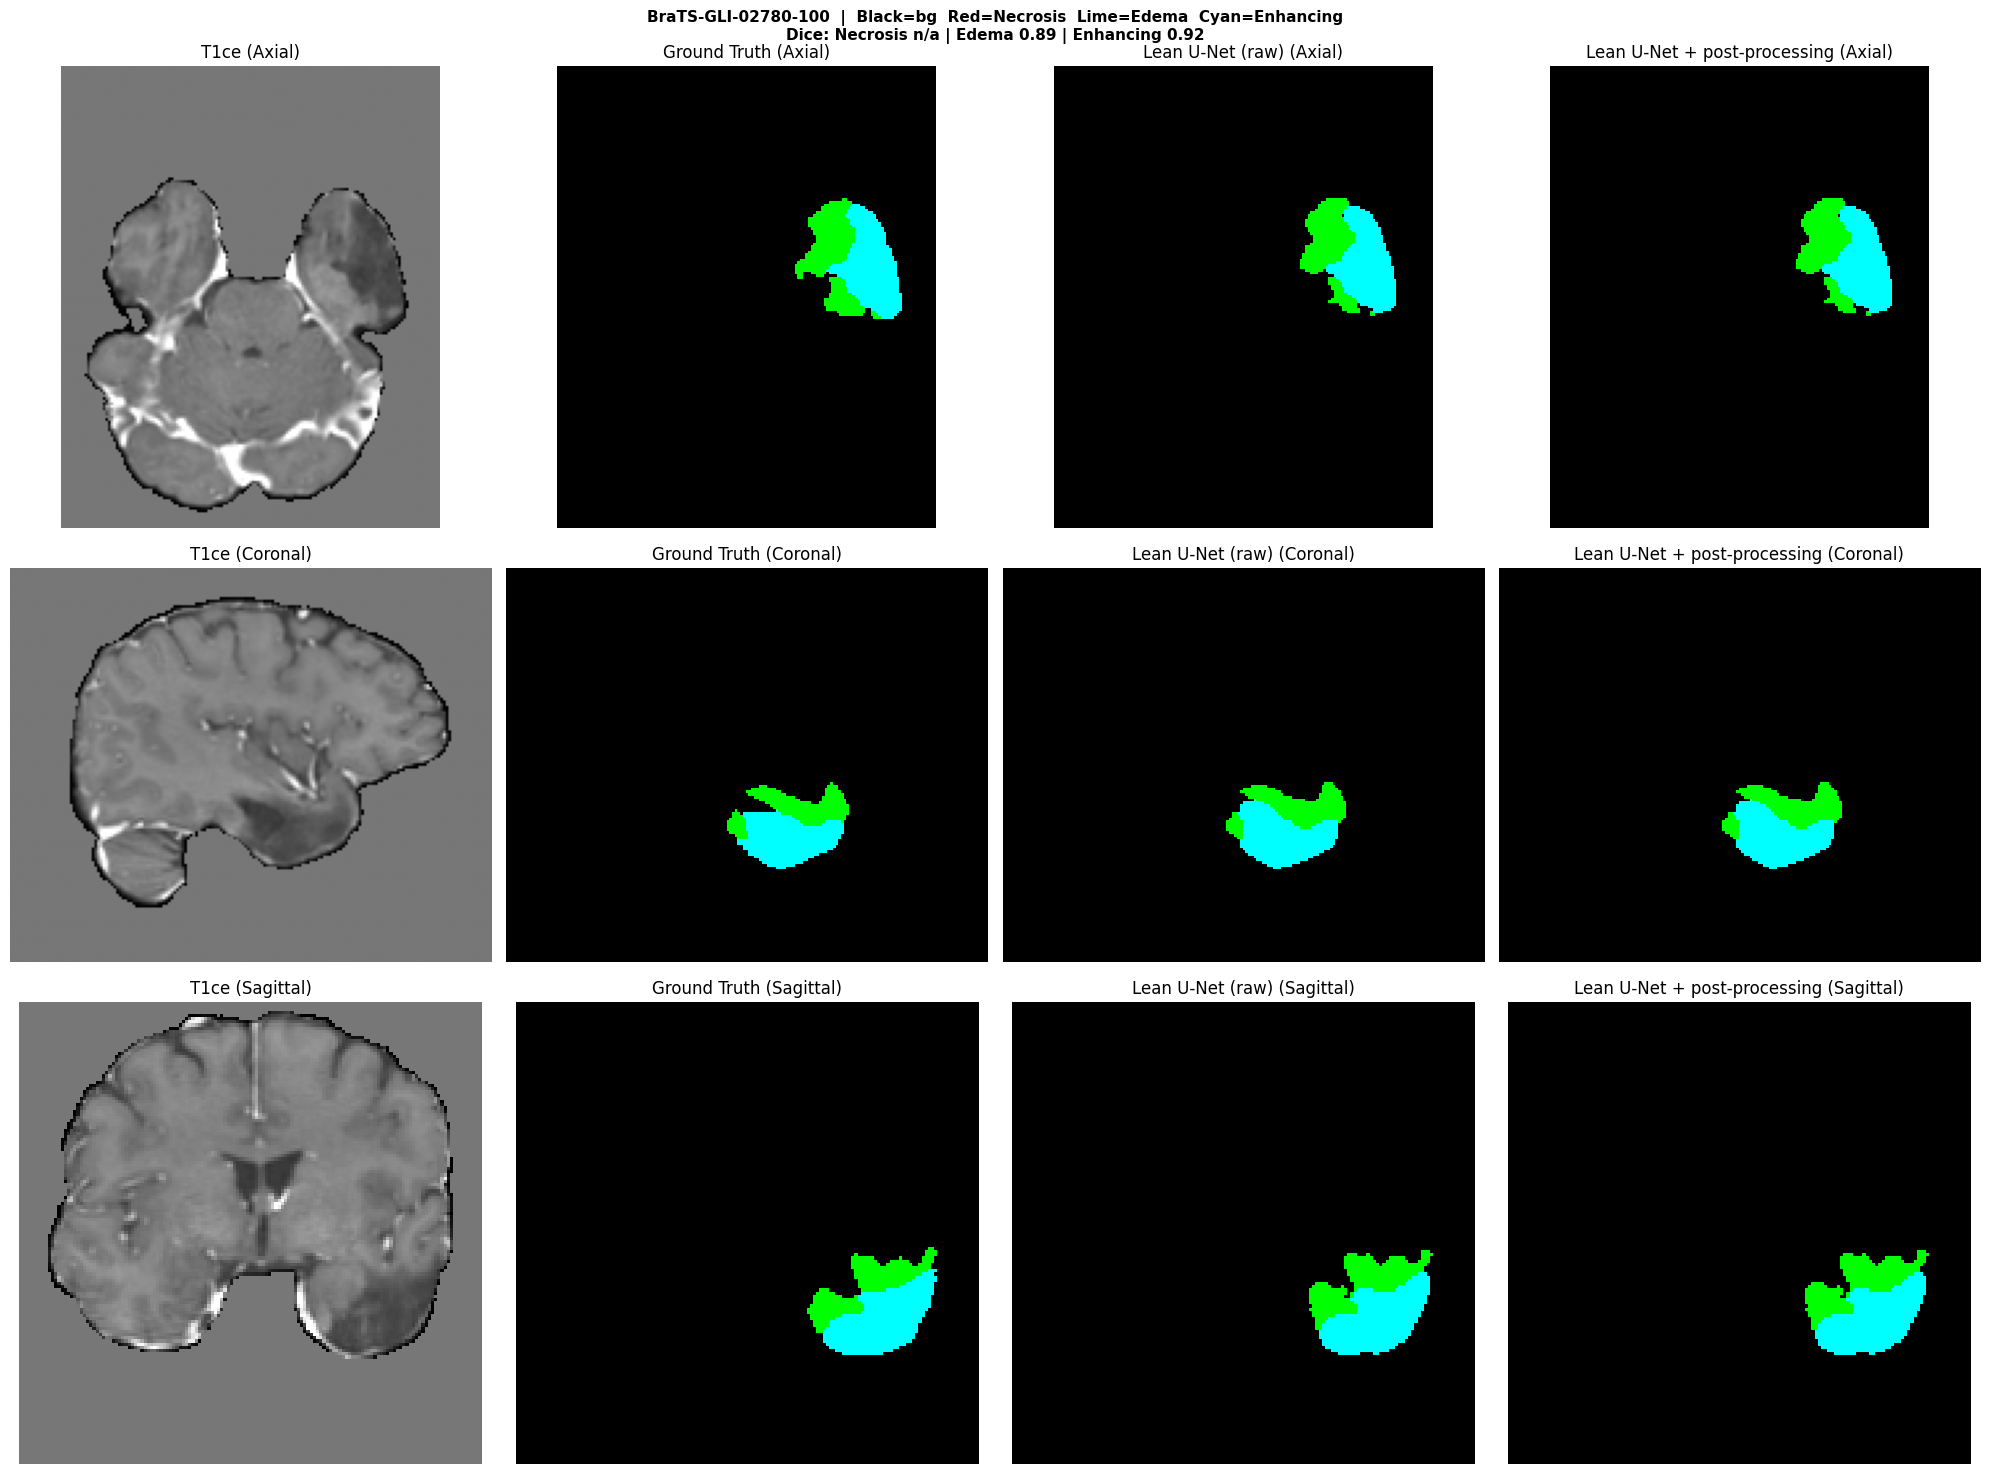


[7/10] BraTS-GLI-02797-101
  sliding window: 12 windows, 1.2 s

------------------------------------------------------------
  Patient: BraTS-GLI-02797-101
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis          nan      0.000     0.000      nan      nan
  Edema          0.7292      9.695     1.925   0.6862   0.7780
  Enhancing      0.6617      8.000     1.974   0.9768   0.5003


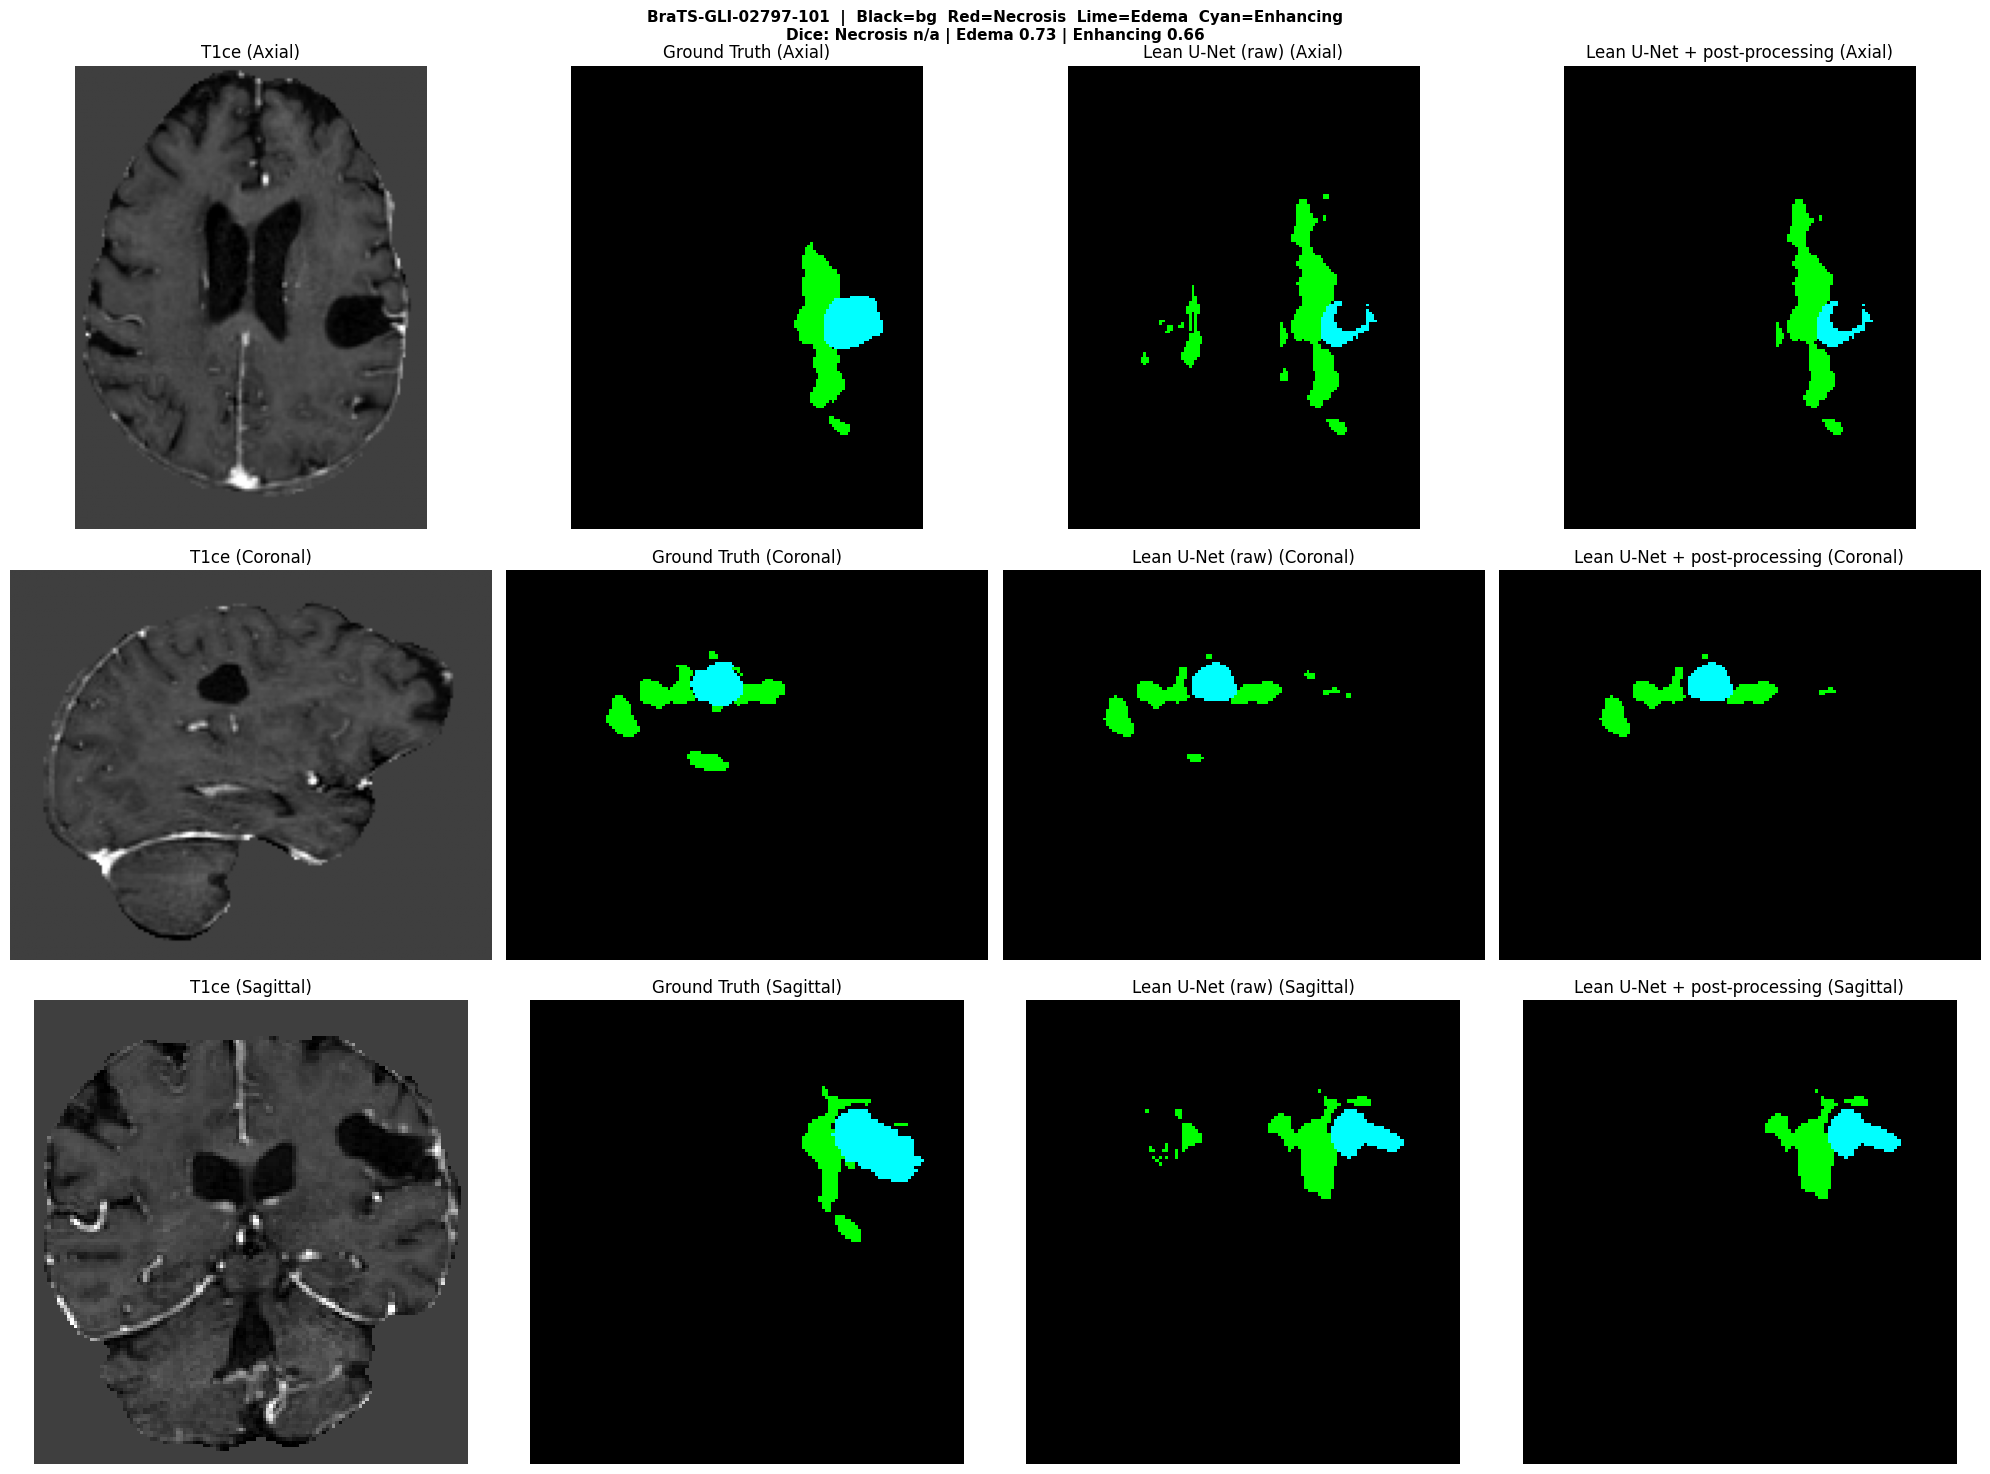


[8/10] BraTS-GLI-02082-105
  sliding window: 27 windows, 2.3 s

------------------------------------------------------------
  Patient: BraTS-GLI-02082-105
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis          nan      0.000     0.000      nan      nan
  Edema          0.9159      1.414     1.022   0.9298   0.9025
  Enhancing      0.3132     28.241     6.396   0.2446   0.4355


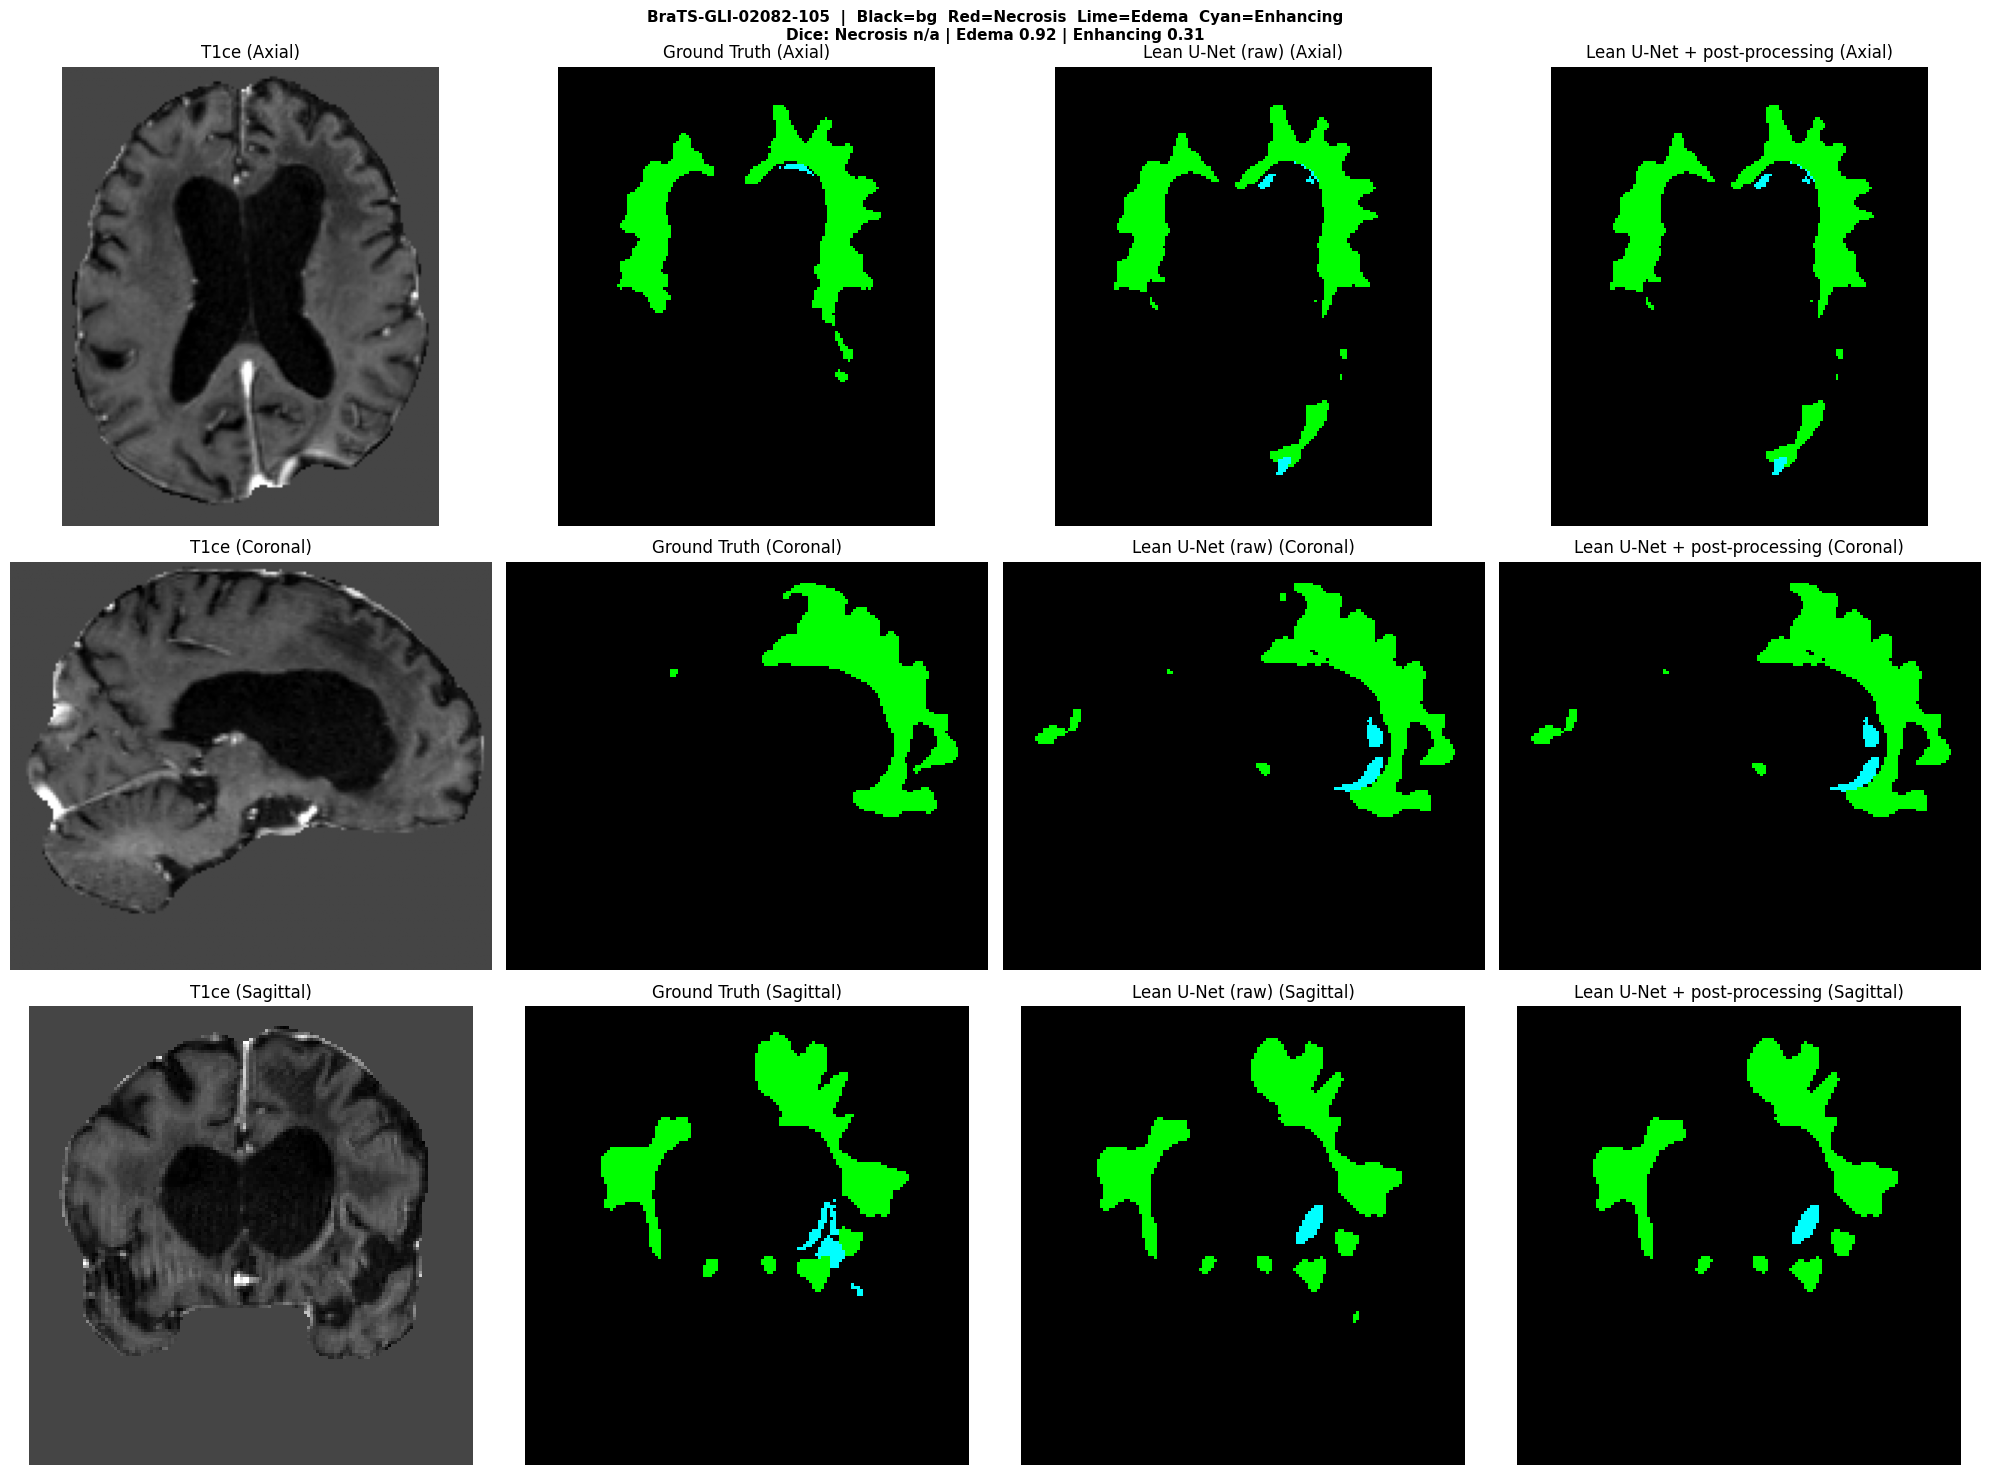


[9/10] BraTS-GLI-00548-100
  sliding window: 18 windows, 1.8 s

------------------------------------------------------------
  Patient: BraTS-GLI-00548-100
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis          nan      0.000     0.000      nan      nan
  Edema          0.8791      1.414     0.666   0.8375   0.9251
  Enhancing      0.9472      1.000     0.419   0.9616   0.9333


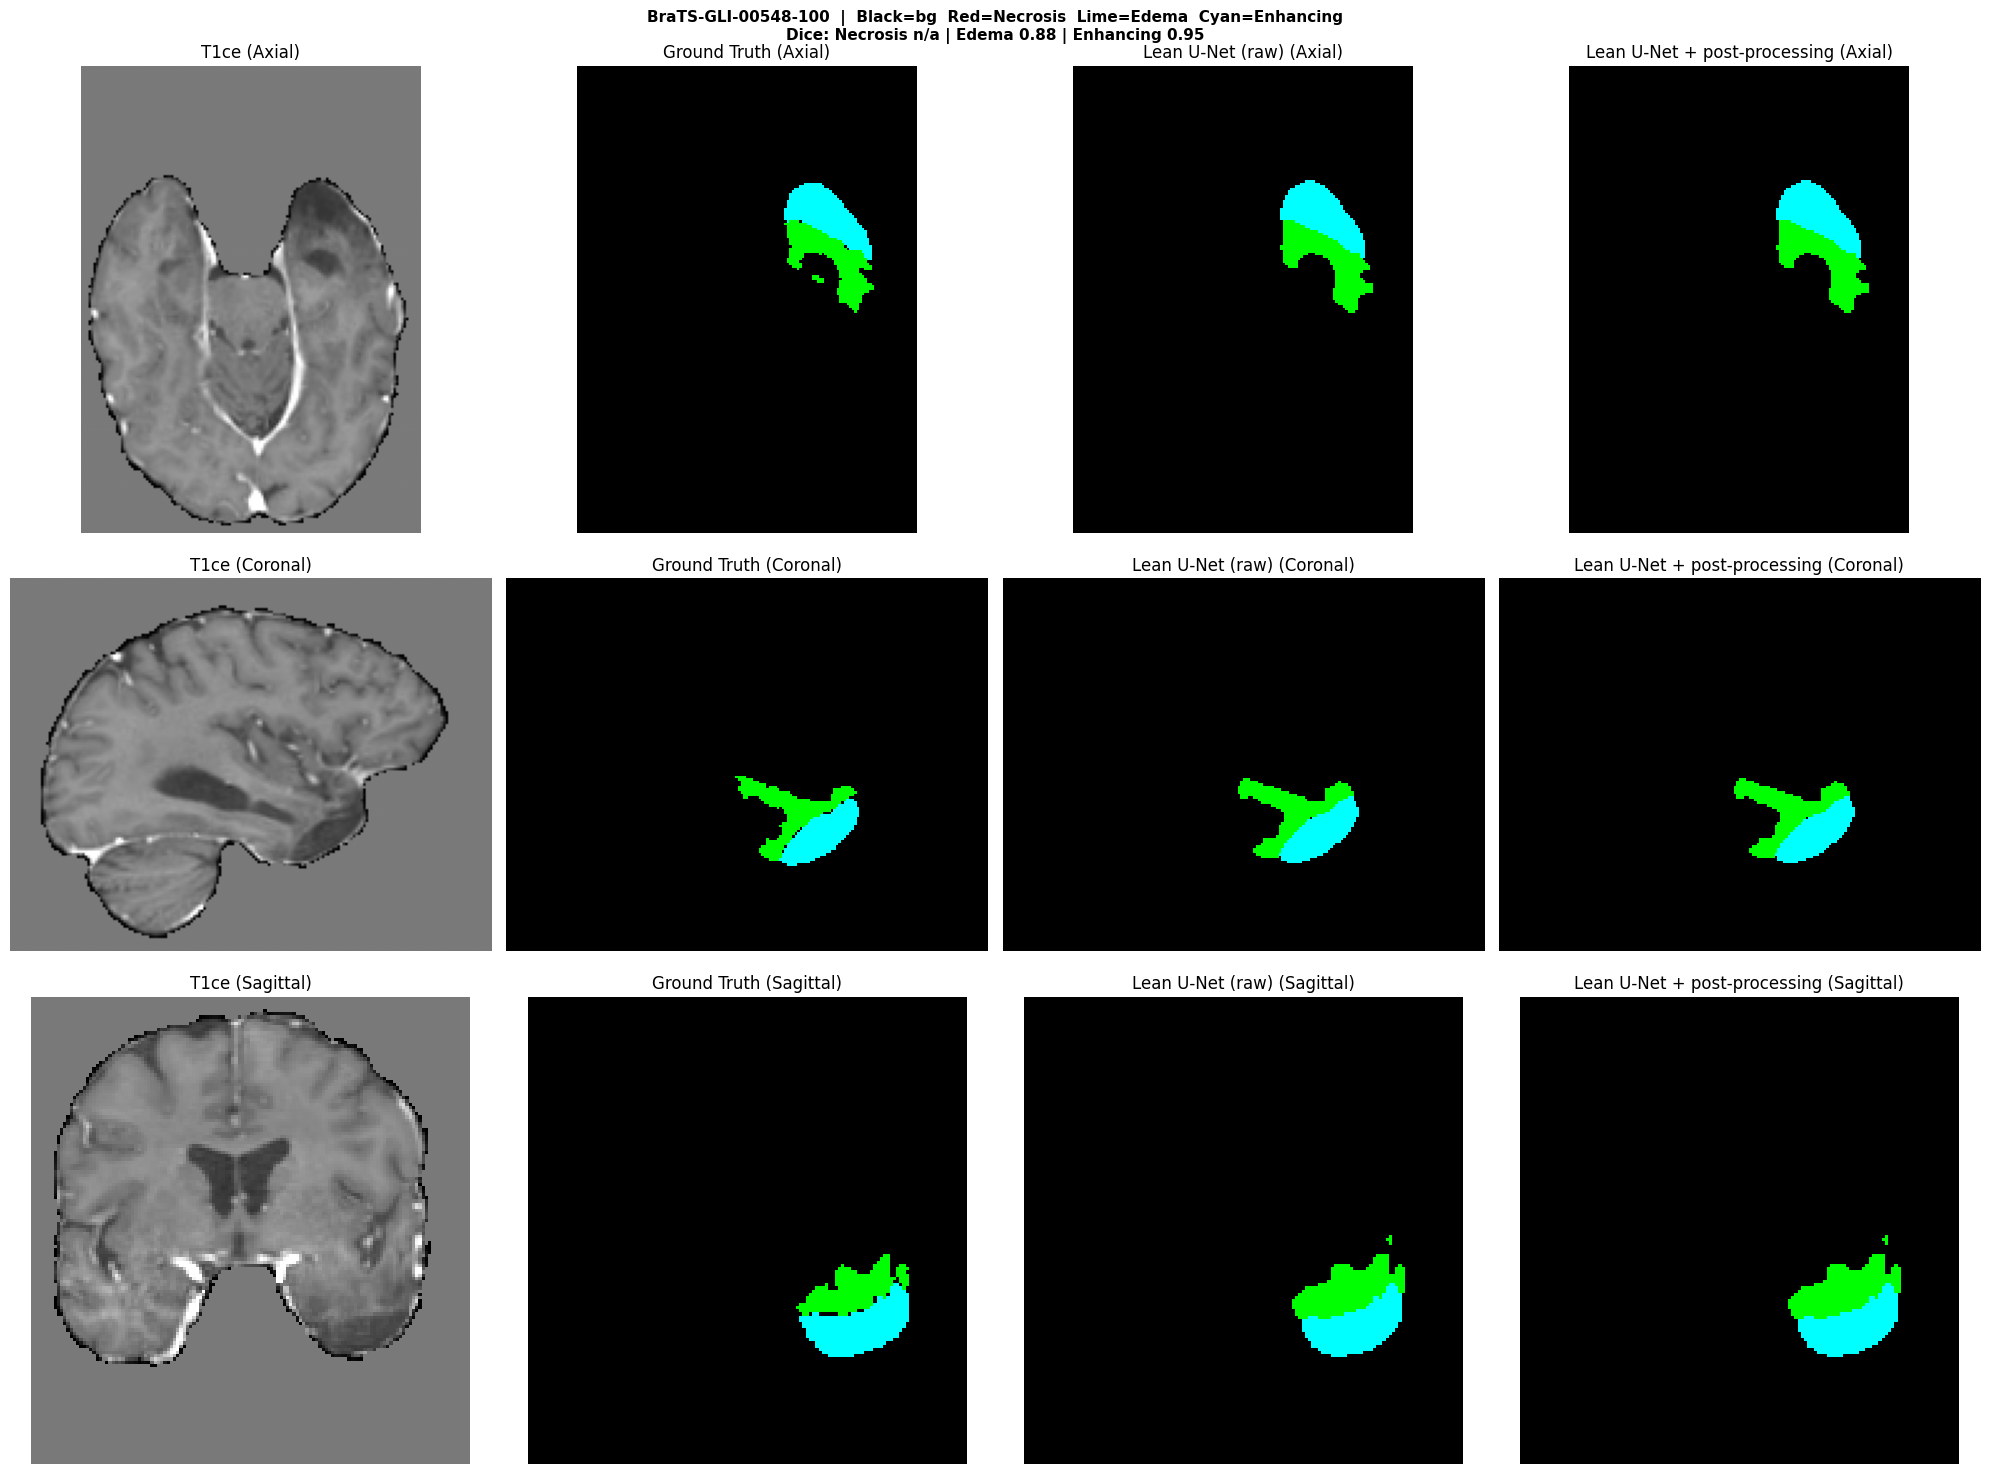


[10/10] BraTS-GLI-02927-100
  sliding window: 12 windows, 1.1 s

------------------------------------------------------------
  Patient: BraTS-GLI-02927-100
  Class             DSC   HD95(mm)   ASD(mm)     Prec   Recall
  ----------------------------------------------------------
  Necrosis       0.5470      4.472     1.447   0.5326   0.5623
  Edema          0.8437      4.000     1.118   0.9227   0.7772
  Enhancing      0.7593      5.099     1.313   0.8011   0.7216


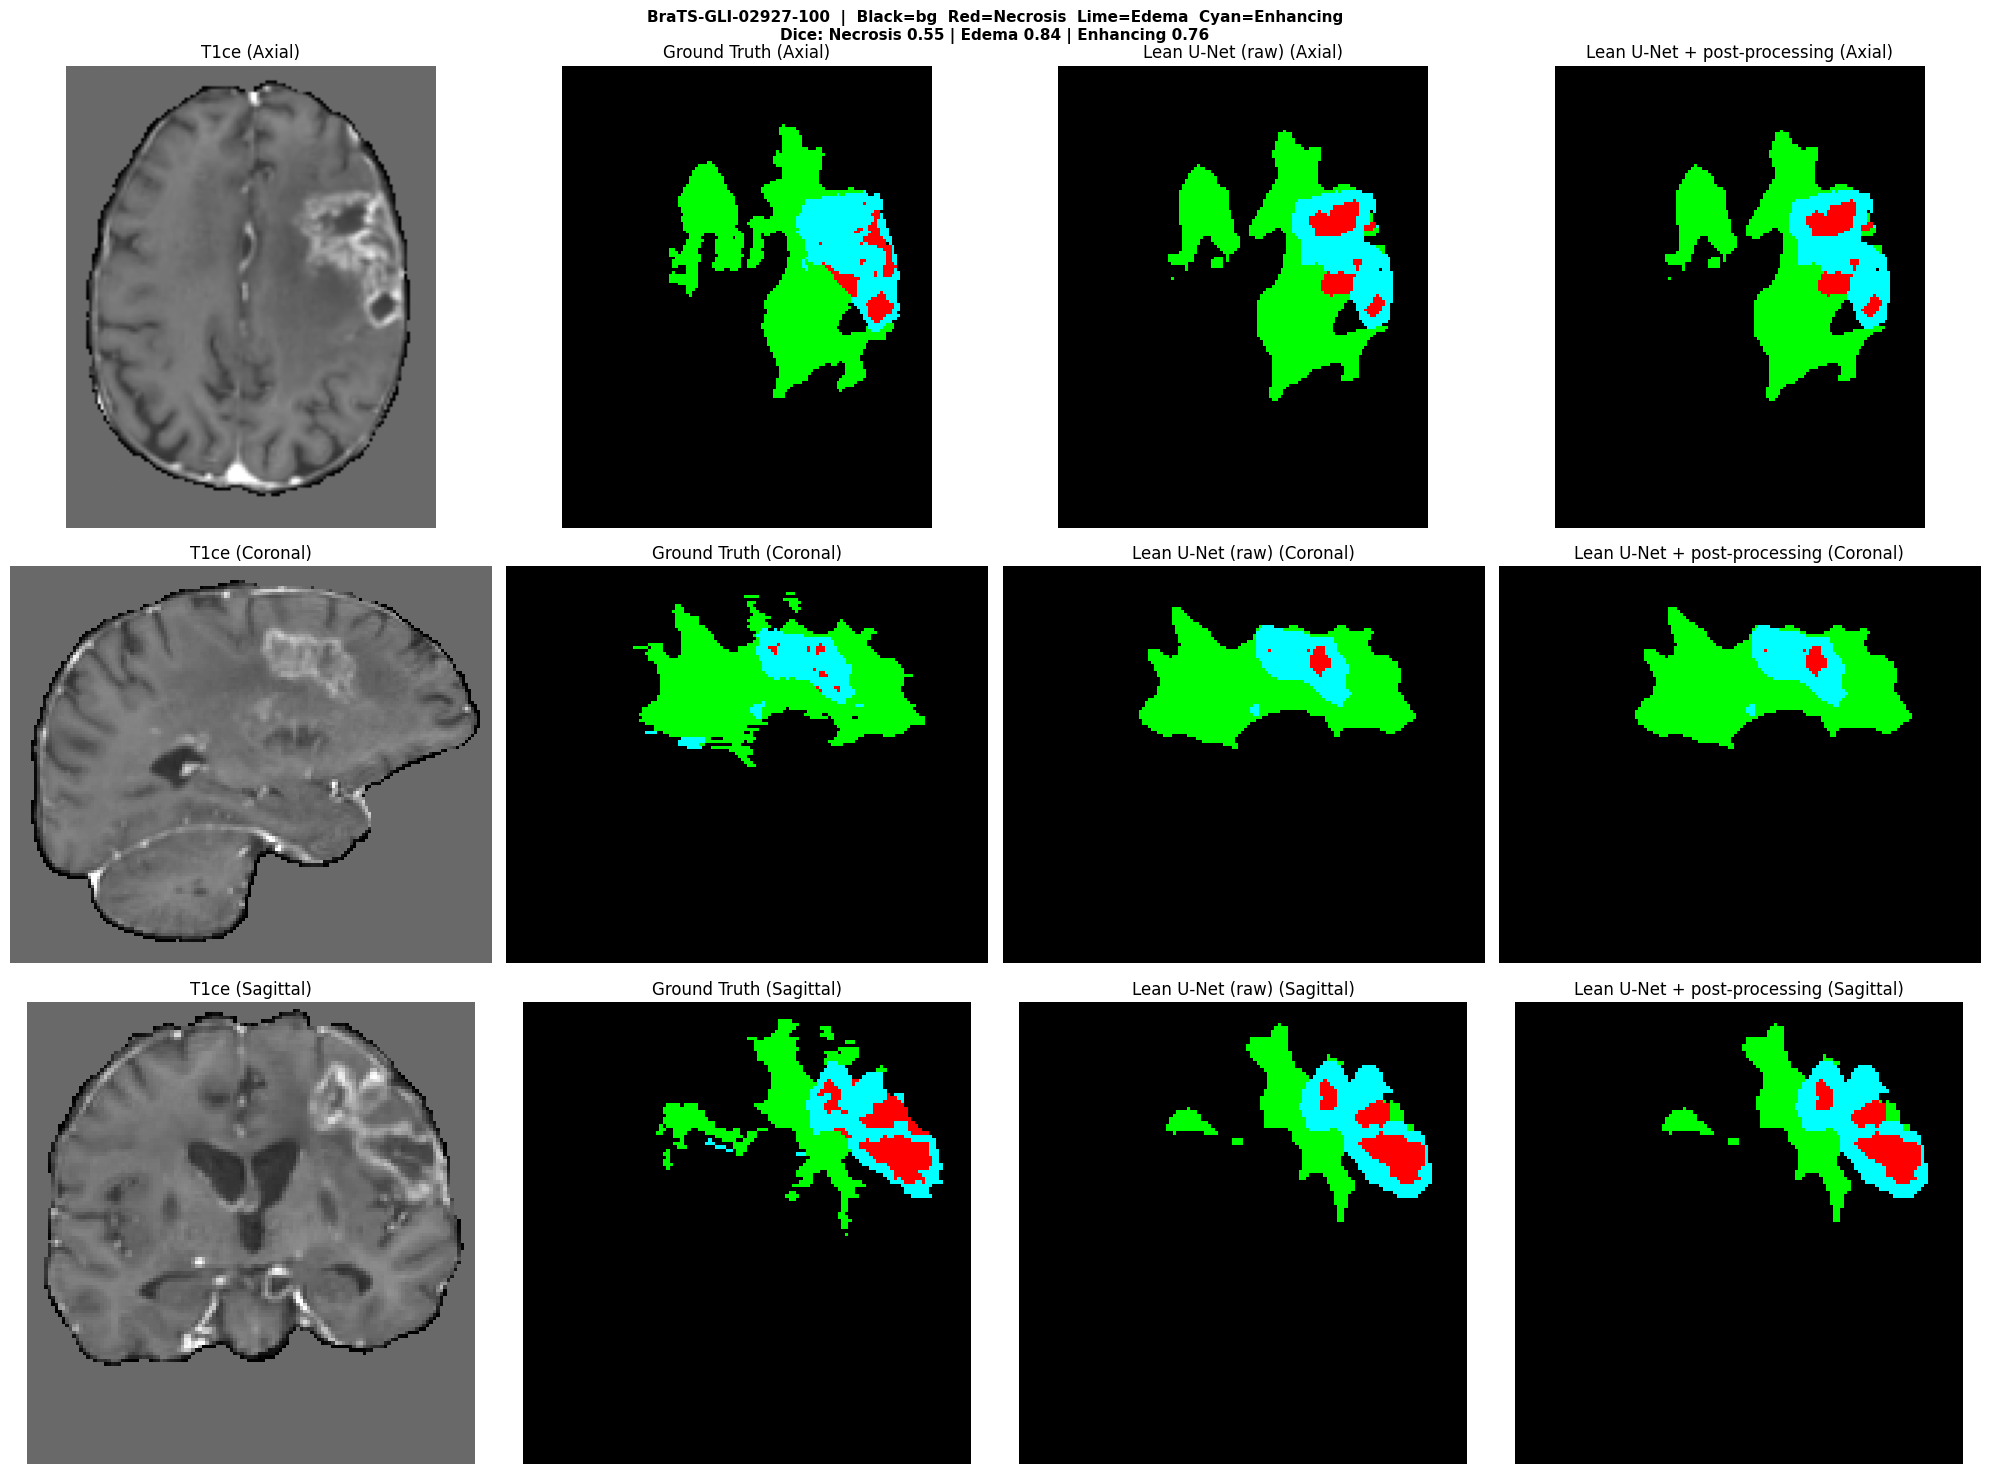


 AGGREGATE METRICS (mean +/- std)
  Class                      DSC         HD95(mm)        ASD(mm)
------------------------------------------------------------
  Necrosis       0.5150+/-0.2769 15.9128+/-27.5472 2.1297+/-3.2880
  Edema          0.7614+/-0.2660 12.2560+/-25.2924 8.4970+/-22.3906
  Enhancing      0.6887+/-0.2907 20.1347+/-27.6987 9.6185+/-22.6581
Figures, masks and tables are saved in: brats_work


In [16]:
def postprocess_prediction(prob, min_size=300, keep_largest=True, brain=None):
    """argmax over the classes; tumor outside the brain mask is removed (a tumor cannot lie in the zero background of a
    skull-stripped scan); then only tumor components of at least `min_size` voxels are kept (and, if `keep_largest`,
    only the largest connected tumor component)."""
    seg = prob.argmax(0).astype(np.uint8)
    if brain is not None:
        seg[~brain] = 0
    lab, n = ndi.label(seg > 0)
    if n:
        sizes = np.bincount(lab.ravel())[1:]
        keep = np.flatnonzero(sizes >= min_size)
        if keep_largest and len(keep):
            keep = keep[[np.argmax(sizes[keep])]]
        seg[~np.isin(lab, 1 + keep)] = 0
    return seg


def _safe_div(a, b):
    return float(a) / float(b) if float(b) != 0 else float("nan")


def surface_metrics(t, p, sp=(1., 1., 1.)):
    """(HD95, ASD) in mm between two binary masks, from the surface-to-surface distances in both directions."""
    t, p = t.astype(bool), p.astype(bool)
    if not t.any() and not p.any():
        return 0.0, 0.0
    if not t.any() or not p.any():
        return float("inf"), float("inf")
    u = np.argwhere(t | p)                                           # work inside the joint bounding box (much faster)
    sl = tuple(slice(max(a - 1, 0), b + 2) for a, b in zip(u.min(0), u.max(0)))
    t, p = t[sl], p[sl]
    st, sp_ = t ^ ndi.binary_erosion(t), p ^ ndi.binary_erosion(p)   # surface voxels
    d = np.concatenate([ndi.distance_transform_edt(~st, sampling=sp)[sp_],
                        ndi.distance_transform_edt(~sp_, sampling=sp)[st]]).astype(np.float32)
    return float(np.percentile(d, 95)), float(d.mean())


def compute_all_metrics(y_true, y_pred, sp=(1., 1., 1.)):
    """DSC, HD95, ASD, precision and recall for every tumor class."""
    res = {}
    for cls in range(1, NUM_CLASSES):
        tb, pb = (y_true == cls), (y_pred == cls)
        tp, fp, fn = int((tb & pb).sum()), int((~tb & pb).sum()), int((tb & ~pb).sum())
        hd, asd = surface_metrics(tb, pb, sp)
        res[CLASS_NAMES[cls]] = {"DSC": _safe_div(2 * tp, tb.sum() + pb.sum()), "HD95_mm": hd, "ASD_mm": asd,
                                 "Precision": _safe_div(tp, tp + fp), "Recall": _safe_div(tp, tp + fn)}
    return res


def region_dice(y_true, y_pred):
    names = {"wt": "Whole tumor", "tc": "Tumor core", "et": "Enhancing tumor"}
    return {names[k]: _safe_div(2 * (f(y_true) & f(y_pred)).sum(), f(y_true).sum() + f(y_pred).sum()) for k, f in REGIONS.items()}


def print_metrics(pid, mdict):
    print(f'\n{"-" * 60}')
    print(f'  Patient: {pid}')
    print(f'  {"Class":<13} {"DSC":>7} {"HD95(mm)":>10} {"ASD(mm)":>9} {"Prec":>8} {"Recall":>8}')
    print(f'  {"-" * 58}')
    for cn, m in mdict.items():
        hd = f'{m["HD95_mm"]:10.3f}' if np.isfinite(m["HD95_mm"]) else f'{"inf":>10}'
        ad = f'{m["ASD_mm"]:9.3f}' if np.isfinite(m["ASD_mm"]) else f'{"inf":>9}'
        print(f'  {cn:<13} {m["DSC"]:7.4f} {hd} {ad} {m["Precision"]:8.4f} {m["Recall"]:8.4f}')


def save_label_nifti(seg_cropped, meta, path):
    """Paste the cropped class map back into the full (RAS) frame and save it with BraTS label values (3 -> 4)."""
    lut = np.array([SAVE_LABELS[c] for c in range(NUM_CLASSES)], np.uint8)
    full = np.zeros(meta["shape"], np.uint8)
    full[tuple(slice(a, b) for a, b in meta["bbox"])] = lut[seg_cropped]
    nib.save(nib.Nifti1Image(full, np.array(meta["affine"])), str(path))


# ---- load the best checkpoint (the window size must equal the training patch size)
ck = load_ckpt(CKPT_DIR / "best.pt")
tcfg = ck["cfg"]
PATCH = tcfg["patch"]
best_model = LeanUNet3D(4, NUM_CLASSES, tcfg["base"], tcfg["levels"], True, False).to(DEVICE)
best_model.load_state_dict(ck["model"])
predict_fn = make_predict_fn(best_model, use_amp=cfg.amp)
print(f"loaded best.pt: step {ck['step']}, mean validation Dice {ck['best']:.3f}, patch {PATCH}³")

FLIP_TTA = False        # True = 4 passes per window (original + a flip along each axis): slower, slightly smoother
flips = ((), (0,), (1,), (2,)) if FLIP_TTA else ((),)
N_INFER = 10            # how many held-out test patients to run (as in your old notebook)
POST_MIN_SIZE = 300     # post-processing: smallest tumor island kept (voxels)
POST_KEEP_LARGEST = True  # post-processing: keep only the largest connected tumor component (gliomas are usually one mass)

FIG_DIR = WORK_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
inf_ids = test_ids[:N_INFER]
all_mets = []
for i, cid in enumerate(inf_ids, 1):
    print(f"\n[{i}/{len(inf_ids)}] {cid}")
    meta = json.load(open(CACHE_DIR / f"{cid}_meta.json"))
    img = np.load(CACHE_DIR / f"{cid}_img.npy", mmap_mode="r")
    gt = np.load(CACHE_DIR / f"{cid}_seg.npy")
    brain = np.asarray(img[0] != 0)
    t0 = time.time()
    prob = sliding_window_predict(img, predict_fn, PATCH, cfg.overlap, cfg.sw_batch, brain=brain, flips=flips)
    raw_seg = prob.argmax(0).astype(np.uint8)
    post_seg = postprocess_prediction(prob, POST_MIN_SIZE, POST_KEEP_LARGEST, brain=brain)
    print(f"  sliding window: {count_windows(img.shape[1:], PATCH, cfg.overlap)} windows, {time.time() - t0:.1f} s")
    mets = compute_all_metrics(gt, post_seg, sp=tuple(meta["zooms"]))
    print_metrics(cid, mets)
    all_mets.append({"patient_id": cid, "total_vox": int(meta.get("brain_voxels", brain.sum())),
                     "gt_vols": {n: int((gt == c).sum()) for c, n in enumerate(CLASS_NAMES)},
                     "pred_vols": {n: int((post_seg == c).sum()) for c, n in enumerate(CLASS_NAMES)},
                     "regions": region_dice(gt, post_seg), **mets})
    save_label_nifti(post_seg, meta, PRED_DIR / f"{cid}_pred.nii.gz")
    dice_line = "Dice: " + " | ".join(f"{cn} {mets[cn]['DSC']:.2f}" if np.isfinite(mets[cn]["DSC"]) else f"{cn} n/a" for cn in FORE_CLASSES)
    plot_three_views(img, gt, [raw_seg, post_seg], ["Lean U-Net (raw)", "Lean U-Net + post-processing"],
                     pid=cid, subtitle=dice_line, save_path=FIG_DIR / f"{cid}_pred.png")


def _fmt(vals):
    """Format mean +/- std; returns 'N/A' for empty or all-NaN lists."""
    return f"{np.mean(vals):.4f}+/-{np.std(vals):.4f}" if len(vals) else "N/A"


print("\n" + "=" * 60)
print(" AGGREGATE METRICS (mean +/- std)")
print("=" * 60)
print(f'  {"Class":<13} {"DSC":>16} {"HD95(mm)":>16} {"ASD(mm)":>14}')
print("-" * 60)
for cn in FORE_CLASSES:
    dv = [m[cn]["DSC"] for m in all_mets if np.isfinite(m[cn]["DSC"])]
    hv = [m[cn]["HD95_mm"] for m in all_mets if np.isfinite(m[cn]["HD95_mm"])]
    av = [m[cn]["ASD_mm"] for m in all_mets if np.isfinite(m[cn]["ASD_mm"])]
    print(f"  {cn:<13} {_fmt(dv):>16} {_fmt(hv):>16} {_fmt(av):>14}")
print("=" * 60)
print(f"Figures, masks and tables are saved in: {WORK_DIR}")

## Step 9: From raw `.nii` files to a segmentation (what you would run on a new patient)

`predict_nifti_case` does everything from scratch for one patient: load the four sequences → the same preprocessing as the cache → sliding-window inference → post-processing → class map pasted back into the full scan and written as NIfTI with the BraTS label values (0 / 1 / 2 / 4). No segmentation file is needed. The scans must be like BraTS: skull-stripped (background exactly 0), co-registered across sequences and about 1 mm isotropic.

The demo runs it on the first test patient's raw files and compares with the ground truth. To run it on unlabeled data (for example the BraTS validation set, which ships without segmentations), set `VALIDATION_DIR`.

In [17]:
def predict_nifti_case(paths, model_fn, patch, overlap=0.5, sw_batch=1, flips=((),), min_size=300, keep_largest=True, out_path=None):
    """paths: dict with keys flair / t1 / t1ce / t2 -> .nii or .nii.gz files of ONE patient."""
    vols, affine = [], None
    for m in MODALITIES:
        d, a = load_nifti(paths[m])
        vols.append(d)
        affine = a if affine is None else affine
    img, brain, sl = preprocess_volumes(vols)
    prob = sliding_window_predict(img, model_fn, patch, overlap, sw_batch, brain=brain, flips=flips)
    seg = postprocess_prediction(prob, min_size, keep_largest, brain=brain)
    lut = np.array([SAVE_LABELS[c] for c in range(NUM_CLASSES)], np.uint8)
    full = np.zeros(vols[0].shape, np.uint8)
    full[sl] = lut[seg]
    if out_path is not None:
        nib.save(nib.Nifti1Image(full, affine), str(out_path))
    return {"labels": full, "seg": seg, "affine": affine, "img": img, "sl": sl, "prob": prob}


rec = by_id[test_ids[0]]
out = predict_nifti_case(rec, predict_fn, PATCH, cfg.overlap, cfg.sw_batch, flips, POST_MIN_SIZE, POST_KEEP_LARGEST,
                         out_path=PRED_DIR / f"{rec['id']}_from_raw.nii.gz")
gt_raw, _ = load_nifti(rec["seg"], as_label=True)
gt_cls = np.where(gt_raw == 4, 3, gt_raw).astype(np.uint8)
pred_cls = np.where(out["labels"] == 4, 3, out["labels"]).astype(np.uint8)
mm = compute_all_metrics(gt_cls, pred_cls)
print(f"{rec['id']}: Dice vs ground truth " + " | ".join(f"{cn} {mm[cn]['DSC']:.3f}" for cn in FORE_CLASSES))
print("written:", PRED_DIR / f"{rec['id']}_from_raw.nii.gz")

VALIDATION_DIR = None     # e.g. Path(r"E:\Research\Dataset\BraTS2020_ValidationData"): patients WITHOUT segmentation files
if VALIDATION_DIR is not None:
    for rec in find_cases(VALIDATION_DIR, need_seg=False, max_cases=3):
        out = predict_nifti_case(rec, predict_fn, PATCH, cfg.overlap, cfg.sw_batch, flips, POST_MIN_SIZE, POST_KEEP_LARGEST,
                                 out_path=PRED_DIR / f"{rec['id']}_pred.nii.gz")
        plot_three_views(out["img"], None, [out["seg"]], ["Lean U-Net + post-processing"],
                         pid=rec["id"] + " (no ground truth)")

BraTS-GLI-02623-101: Dice vs ground truth Necrosis 0.000 | Edema 0.000 | Enhancing 0.000
written: brats_work\predictions\BraTS-GLI-02623-101_from_raw.nii.gz


## Step 10: Graphs

The same graphs as at the end of your old notebook, now for the Lean 3D U-Net (all saved as PNG in `figures/`, plus two CSV tables):

1. **Training history**: total loss (train / validation), validation Dice per class, validation Dice of the BraTS regions (whole tumor, tumor core, enhancing tumor). It is re-read from `ckpt/last.pt`, so it also works in a fresh session.
2. **Per-patient tables**: ground-truth vs predicted voxels (and % of the brain) and all metrics, then mean ± std over the test patients.
3. **Figure A**: ground-truth vs predicted volume per patient, per class (bars).
4. **Figure B**: ground-truth vs predicted volume as % of the brain, per class (scatter with the y = x line).
5. **Figure C**: DSC / precision / recall per class (bars with std and one dot per patient).
6. **Figure D**: HD95 and ASD per class (boxplots).

Percentages are relative to the number of **brain voxels** of each patient (your old notebook divided by the full 240×240×155 array, so its percentages were about six times smaller).

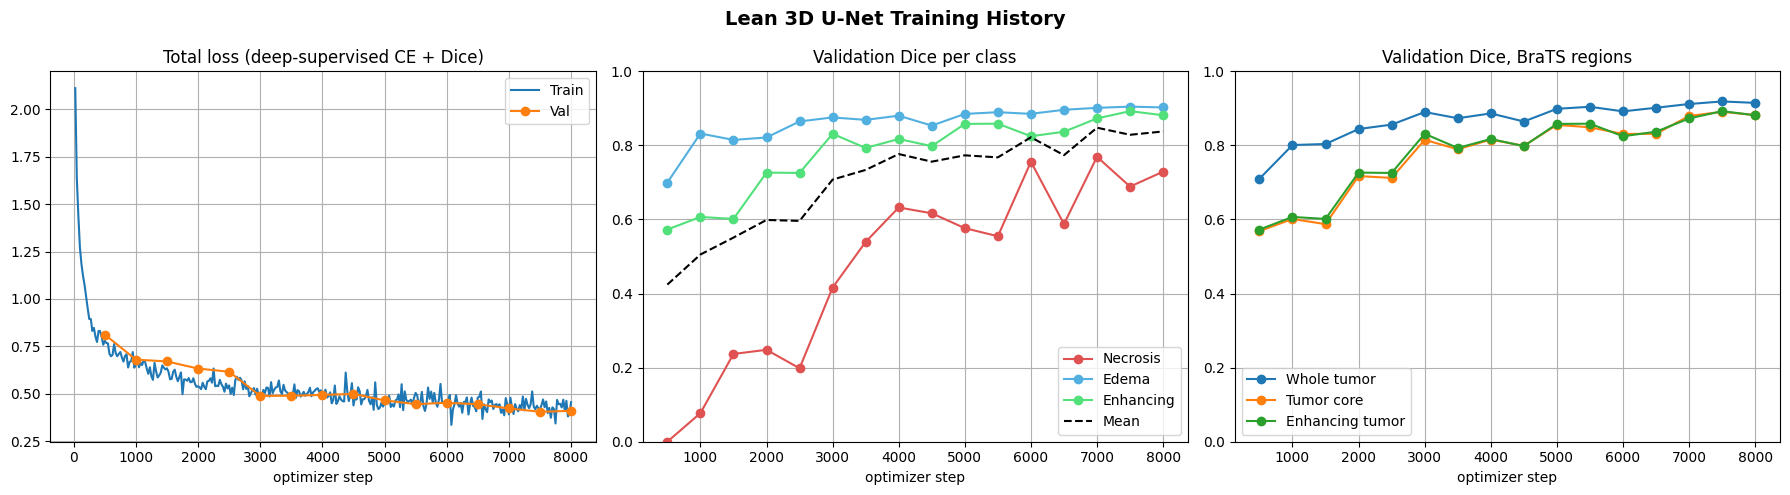


════════════════════════════════════════════════════════════════════════════════════════════════════
  PER-PATIENT GROUND-TRUTH vs PREDICTION COMPARISON
════════════════════════════════════════════════════════════════════════════════════════════════════
  Patient                         Metric            Necrosis          Edema      Enhancing
────────────────────────────────────────────────────────────────────────────────────────────────────
  BraTS-GLI-02623-101             GT vox                   0            801            150
  BraTS-GLI-02623-101             Pred vox                56         22,736            124
  BraTS-GLI-02623-101             GT %                 0.00%          0.06%          0.01%
  BraTS-GLI-02623-101             Pred %               0.00%          1.75%          0.01%
                                  DSC                 0.0000         0.0000         0.0000
                                  HD95_mm                N/A        87.6641        81.7943
       

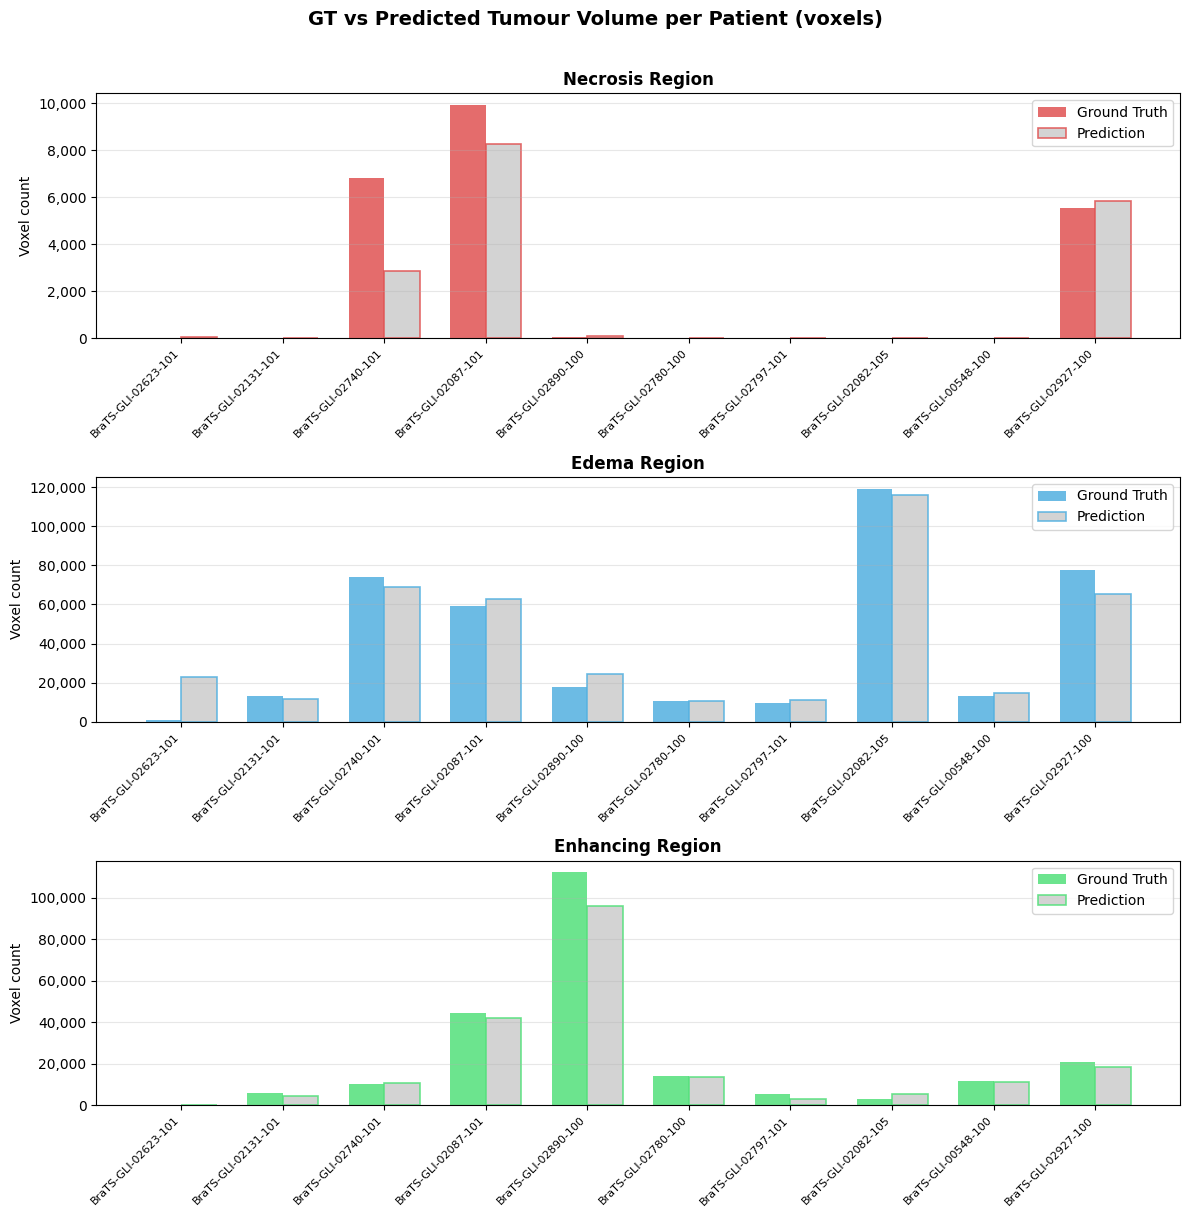

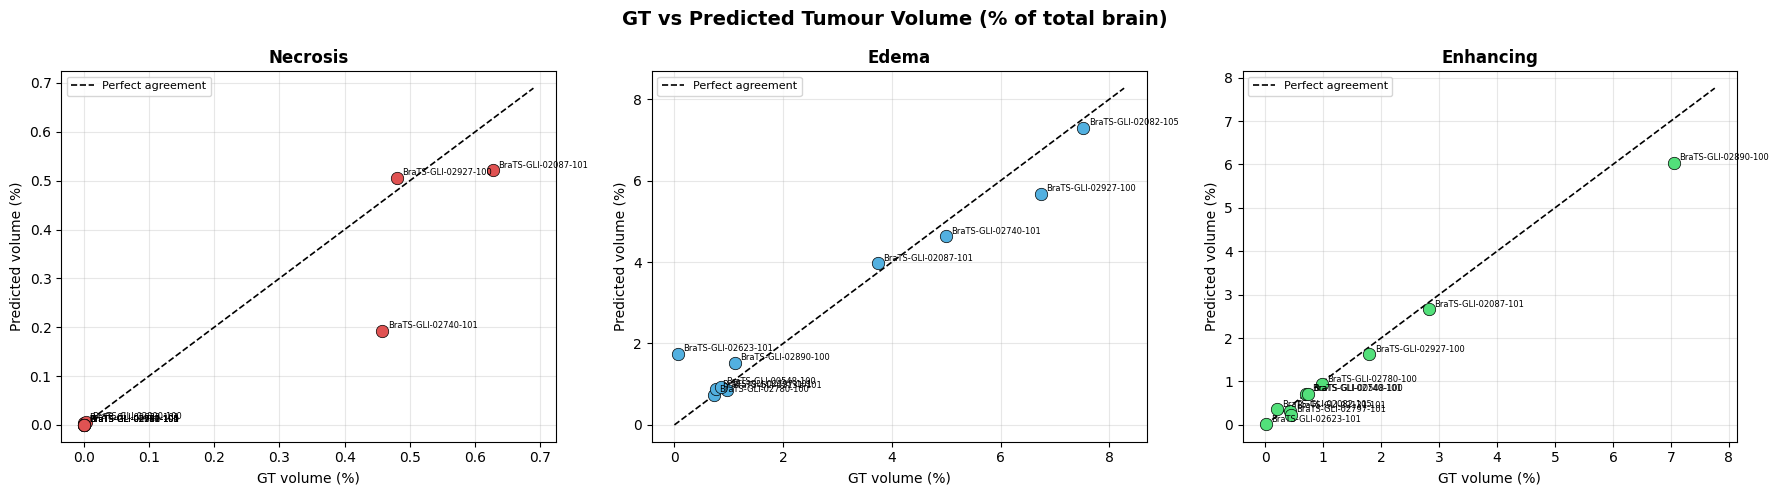

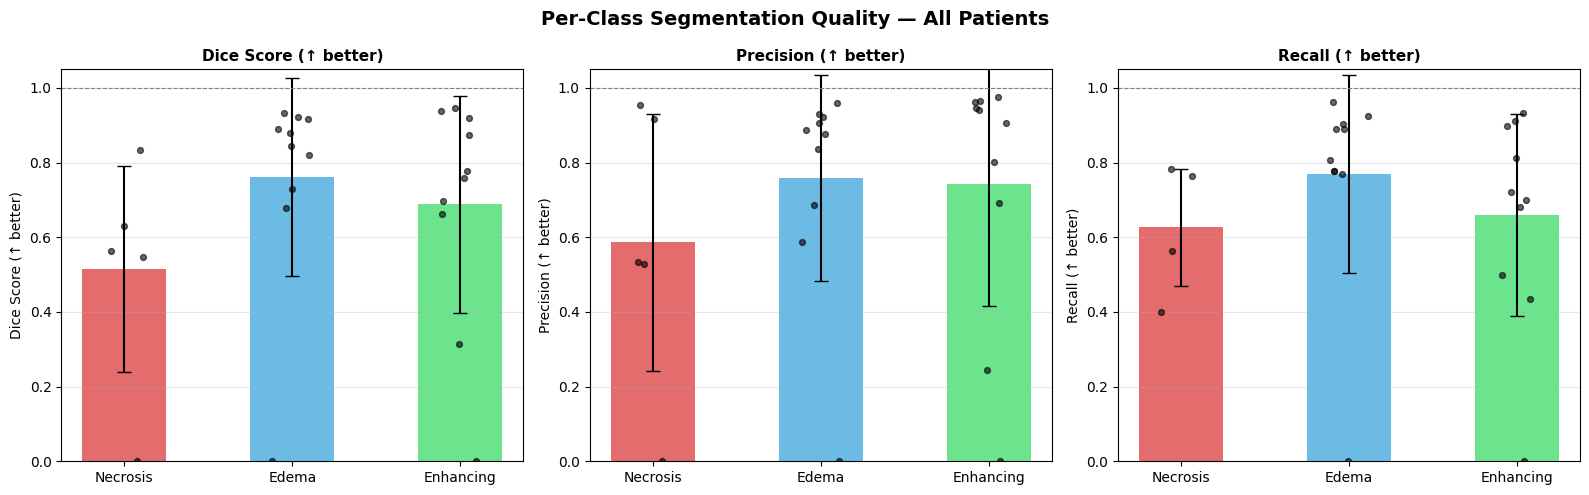

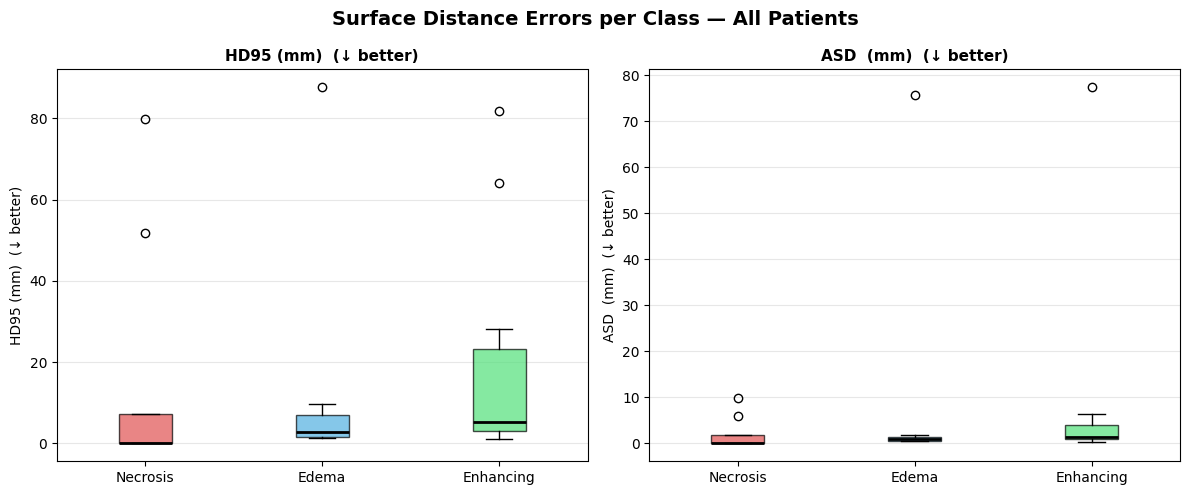


✓ All figures saved to: brats_work\figures
✓ Tables saved to: brats_work\metrics_per_patient.csv and brats_work\metrics_summary.csv


In [18]:
def _vals(key, sub, patients=None):
    """Collect finite floats for metric `key` / class `sub` across all patients."""
    out = []
    for m in (all_mets if patients is None else patients):
        if sub in m and isinstance(m[sub], dict) and key in m[sub] and np.isfinite(m[sub][key]):
            out.append(m[sub][key])
    return out


def _mu_sd(lst):
    return (float(np.mean(lst)), float(np.std(lst))) if len(lst) else (float("nan"), float("nan"))


def plot_training_history(hist, save_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Lean 3D U-Net Training History", fontsize=14, fontweight="bold")
    axes[0].plot(hist["step"], hist["loss"], label="Train")
    if hist["val_step"]:
        axes[0].plot(hist["val_step"], hist["val_loss"], marker="o", label="Val")
    axes[0].set_title("Total loss (deep-supervised CE + Dice)"); axes[0].set_xlabel("optimizer step"); axes[0].legend(); axes[0].grid(True)
    for cn, col in zip(FORE_CLASSES, CLASS_COLORS):
        axes[1].plot(hist["val_step"], hist[f"val_dice_{cn.lower()}"], marker="o", color=col, label=cn)
    axes[1].plot(hist["val_step"], hist["val_dice_mean"], "k--", label="Mean")
    axes[1].set_title("Validation Dice per class"); axes[1].set_xlabel("optimizer step"); axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].grid(True)
    for key, name in (("val_wt", "Whole tumor"), ("val_tc", "Tumor core"), ("val_et", "Enhancing tumor")):
        axes[2].plot(hist["val_step"], hist[key], marker="o", label=name)
    axes[2].set_title("Validation Dice, BraTS regions"); axes[2].set_xlabel("optimizer step"); axes[2].set_ylim(0, 1); axes[2].legend(); axes[2].grid(True)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# ---- 1. training history
plot_training_history(load_ckpt(CKPT_DIR / "last.pt")["hist"], FIG_DIR / "training_history.png")

# ---- 2. per-patient table (printed + CSV)
print("\n" + "═" * 100)
print("  PER-PATIENT GROUND-TRUTH vs PREDICTION COMPARISON")
print("═" * 100)
print(f"  {'Patient':<30}  {'Metric':<11}" + "".join(f"{c:>15}" for c in FORE_CLASSES))
print("─" * 100)
csv_rows = []
for m in all_mets:
    pid, tv = m["patient_id"], max(m["total_vox"], 1)
    for label, vol_key in [("GT vox", "gt_vols"), ("Pred vox", "pred_vols"), ("GT %", "gt_vols"), ("Pred %", "pred_vols")]:
        row = f"  {pid:<30}  {label:<11}"
        for cn in FORE_CLASSES:
            v = m[vol_key].get(cn, 0)
            row += f"{v / tv * 100:>14.2f}%" if "%" in label else f"{v:>15,}"
        print(row)
    for metric in ["DSC", "HD95_mm", "ASD_mm", "Precision", "Recall"]:
        row = f"  {'':30}  {metric:<11}"
        for cn in FORE_CLASSES:
            v = m[cn].get(metric, float("nan"))
            row += f"{v:>15.4f}" if np.isfinite(v) else f"{'N/A':>15}"
        print(row)
    print("─" * 100)
    for cn in FORE_CLASSES:
        csv_rows.append({"patient": pid, "class": cn, "gt_voxels": m["gt_vols"][cn], "pred_voxels": m["pred_vols"][cn],
                         **{k: m[cn][k] for k in ("DSC", "HD95_mm", "ASD_mm", "Precision", "Recall")}})
pd.DataFrame(csv_rows).to_csv(WORK_DIR / "metrics_per_patient.csv", index=False)

# ---- 3. aggregate table (printed + CSV)
print("\n" + "═" * 90)
print("  AGGREGATE STATISTICS  (mean ± std across all evaluated patients)")
print("═" * 90)
print(f"  {'Metric':<18}" + "".join(f"{c:>25}" for c in FORE_CLASSES))
print("─" * 90)
for vol_key, label in [("gt_vols", "GT vol (vox)"), ("pred_vols", "Pred vol (vox)")]:
    row = f"  {label:<18}"
    for cn in FORE_CLASSES:
        mu, sd = _mu_sd([m[vol_key].get(cn, 0) for m in all_mets])
        row += f"{mu:>12,.0f}±{sd:>10,.0f}"
    print(row)
for vol_key, label in [("gt_vols", "GT vol (%)"), ("pred_vols", "Pred vol (%)")]:
    row = f"  {label:<18}"
    for cn in FORE_CLASSES:
        mu, sd = _mu_sd([m[vol_key].get(cn, 0) / max(m["total_vox"], 1) * 100 for m in all_mets])
        row += f"{mu:>11.3f}% ±{sd:>7.3f}%"
    print(row)
print("─" * 90)
summary = []
for metric, label in [("DSC", "DSC"), ("HD95_mm", "HD95 (mm)"), ("ASD_mm", "ASD (mm)"), ("Precision", "Precision"), ("Recall", "Recall")]:
    row = f"  {label:<18}"
    for cn in FORE_CLASSES:
        mu, sd = _mu_sd(_vals(metric, cn))
        row += f"{mu:>12.4f}±{sd:>10.4f}" if np.isfinite(mu) else f"{'N/A':>23}"
        summary.append({"metric": label, "class": cn, "mean": mu, "std": sd})
    print(row)
print("═" * 90)
pd.DataFrame(summary).to_csv(WORK_DIR / "metrics_summary.csv", index=False)

print("\n  BraTS regions (Dice, mean ± std):")
for name in ("Whole tumor", "Tumor core", "Enhancing tumor"):
    mu, sd = _mu_sd([m["regions"][name] for m in all_mets if np.isfinite(m["regions"][name])])
    print(f"    {name:<16} {mu:.4f} ± {sd:.4f}")

# ---- 4. Figure A: GT vs predicted volume per patient (voxels)
n_pat, n_cls = len(all_mets), len(FORE_CLASSES)
x = np.arange(n_pat)
pids = [m["patient_id"].replace("BraTS20_Training_", "") for m in all_mets]
fig, axes = plt.subplots(n_cls, 1, figsize=(max(10, n_pat * 1.2), 4 * n_cls), sharex=False)
fig.suptitle("GT vs Predicted Tumour Volume per Patient (voxels)", fontsize=14, fontweight="bold", y=1.01)
for ax, cn, col in zip(axes, FORE_CLASSES, CLASS_COLORS):
    gt_v = [m["gt_vols"].get(cn, 0) for m in all_mets]
    pred_v = [m["pred_vols"].get(cn, 0) for m in all_mets]
    ax.bar(x - 0.35 / 2, gt_v, 0.35, label="Ground Truth", color=col, alpha=0.85)
    ax.bar(x + 0.35 / 2, pred_v, 0.35, label="Prediction", color="#cccccc", alpha=0.85, edgecolor=col, linewidth=1.2)
    ax.set_title(f"{cn} Region", fontsize=12, fontweight="bold")
    ax.set_ylabel("Voxel count")
    ax.set_xticks(x); ax.set_xticklabels(pids, rotation=45, ha="right", fontsize=8)
    ax.legend(loc="upper right")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_volume_bars.png", dpi=130, bbox_inches="tight")
plt.show()

# ---- 5. Figure B: GT vs predicted volume as % of the brain
fig, axes = plt.subplots(1, n_cls, figsize=(6 * n_cls, 5), sharey=False)
fig.suptitle("GT vs Predicted Tumour Volume (% of total brain)", fontsize=14, fontweight="bold")
for ax, cn, col in zip(axes, FORE_CLASSES, CLASS_COLORS):
    gt_pct = [m["gt_vols"].get(cn, 0) / max(m["total_vox"], 1) * 100 for m in all_mets]
    pd_pct = [m["pred_vols"].get(cn, 0) / max(m["total_vox"], 1) * 100 for m in all_mets]
    ax.scatter(gt_pct, pd_pct, c=col, s=80, zorder=3, edgecolors="k", linewidths=0.5)
    lim = max(max(gt_pct + pd_pct, default=1) * 1.1, 0.1)
    ax.plot([0, lim], [0, lim], "k--", lw=1.2, label="Perfect agreement")
    for g, p, pid in zip(gt_pct, pd_pct, pids):
        ax.annotate(pid, (g, p), textcoords="offset points", xytext=(4, 2), fontsize=6)
    ax.set_xlabel("GT volume (%)"); ax.set_ylabel("Predicted volume (%)")
    ax.set_title(cn, fontweight="bold"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_volume_pct.png", dpi=130, bbox_inches="tight")
plt.show()

# ---- 6. Figure C: DSC / precision / recall per class
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
fig.suptitle("Per-Class Segmentation Quality — All Patients", fontsize=14, fontweight="bold")
for ax, (mkey, mlabel) in zip(axes, [("DSC", "Dice Score (↑ better)"), ("Precision", "Precision (↑ better)"), ("Recall", "Recall (↑ better)")]):
    class_data = [_vals(mkey, cn) for cn in FORE_CLASSES]
    means = [np.mean(v) if v else 0 for v in class_data]
    stds = [np.std(v) if v else 0 for v in class_data]
    ax.bar(np.arange(n_cls), means, 0.5, yerr=stds, capsize=5, color=CLASS_COLORS[:n_cls], alpha=0.85, error_kw={"elinewidth": 1.5})
    for k, vals in enumerate(class_data):                                  # one dot per patient
        ax.scatter(k + np.random.uniform(-0.12, 0.12, len(vals)), vals, color="k", s=18, zorder=4, alpha=0.6)
    ax.set_xticks(np.arange(n_cls)); ax.set_xticklabels(FORE_CLASSES, fontsize=10)
    ax.set_ylabel(mlabel); ax.set_title(mlabel, fontsize=11, fontweight="bold")
    ax.set_ylim(0, 1.05); ax.axhline(1.0, color="gray", lw=0.8, ls="--"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_metrics_bars.png", dpi=130, bbox_inches="tight")
plt.show()

# ---- 7. Figure D: HD95 / ASD per class
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Surface Distance Errors per Class — All Patients", fontsize=14, fontweight="bold")
for ax, (mkey, mlabel) in zip(axes, [("HD95_mm", "HD95 (mm)  (↓ better)"), ("ASD_mm", "ASD  (mm)  (↓ better)")]):
    class_data = [_vals(mkey, cn) for cn in FORE_CLASSES]
    bp = ax.boxplot([v if v else [0] for v in class_data], patch_artist=True, notch=False, medianprops={"color": "black", "lw": 2})
    for patch, col in zip(bp["boxes"], CLASS_COLORS):
        patch.set_facecolor(col); patch.set_alpha(0.7)
    ax.set_xticklabels(FORE_CLASSES, fontsize=10)
    ax.set_ylabel(mlabel); ax.set_title(mlabel, fontsize=11, fontweight="bold"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_distances.png", dpi=130, bbox_inches="tight")
plt.show()

print("\n✓ All figures saved to:", FIG_DIR)
print("✓ Tables saved to:", WORK_DIR / "metrics_per_patient.csv", "and", WORK_DIR / "metrics_summary.csv")

## Where to go from here

- **Train longer / on more data.** The default schedules are short and necrosis / enhancing are the hardest classes; validation Dice usually keeps improving with more steps. Use the `gpu_low` or `gpu_mid` preset on a GPU (or raise `cfg.total_steps`); the notebook also runs on a free Kaggle / Colab GPU, just point `DATA_ROOT` at the dataset.
- **Class balance.** If a class stays weak, raise `cfg.fg_prob` (more tumor-centred patches) or set `CE_WEIGHTS = [0.1, 3.5, 2.0, 3.5]` (the weights of your old focal loss).
- **Cheaper inference.** Lower `cfg.overlap`, raise `cfg.sw_batch` as far as memory allows, keep empty-window skipping on. A coarse-to-fine cascade (a 2 mm whole-brain pass, then full-resolution windows only around detections) and INT8 / ONNX export are the next steps.
- **Better accuracy.** 5-fold cross-validation by patient, rotation / scale augmentation, longer schedules, ensembling the folds, flip test-time augmentation (`FLIP_TTA = True`).
- This is research / educational code, not a medical device. Do not use it for clinical decisions.

In [1]:
try:
    from skimage.measure import marching_cubes
    HAVE_SKIMAGE = True
except ImportError:
    HAVE_SKIMAGE = False
try:
    import plotly.graph_objects as go
    HAVE_PLOTLY = True
except ImportError:
    HAVE_PLOTLY = False
from matplotlib.colors import to_rgb, LinearSegmentedColormap
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
if not HAVE_SKIMAGE:
    print("Step 11 needs scikit-image to extract the surfaces:  pip install scikit-image")
if not HAVE_PLOTLY:
    print("The interactive scenes need plotly:  pip install plotly   (the static figure works without it)")

VIEW_N = 3                     # how many held-out patients to render in 3D
MAKE_STATIC = True             # matplotlib figure saved as PNG: ground truth / prediction / errors from 3 viewpoints
MAKE_GIF = False               # rotating GIF, ground truth next to prediction (slow: a few minutes per patient)
GIF_FRAMES = 36
PLOTLY_JS = "cdn"              # "cdn": small .html files that need internet to open; True: self-contained files (about 4 MB more)
CUTAWAY_AT_START = True        # edema / enhancing shells start with their front half removed (button: "Full shells" brings it back)
SLICES_AT_START = False        # T1ce slice planes hide part of the tumor, so they start switched off (use the buttons)
MESH_SMOOTH = 1.0              # gaussian sigma (voxels) applied to a class mask before the surface is extracted
TUMOR_STYLE = {1: ("red", 1.0), 2: ("lime", 0.25), 3: ("cyan", 0.45)}    # class -> (colour, opacity); edema and enhancing are see-through
DRAW_ORDER = (2, 3, 1)         # edema, enhancing, necrosis: the opaque core is drawn last so it stays visible inside
ERR_RANGE = 4.0                # mm: scale of the surface-error colours (blue = -4 mm ... green = 0 ... red = +4 mm)
ERR_COLORS = ["#2c7bb6", "#abd9e9", "#66bd63", "#fdae61", "#d7191c"]      # blue (falls short) -> green (on target) -> red (sticks out)
ERR_CMAP = LinearSegmentedColormap.from_list("surface_error", ERR_COLORS)
BRAIN_COLOUR = "#4b5563"
CAMERAS = {                    # preset viewpoints of the interactive scene (ground truth left, prediction right in "Front")
    "Front": dict(eye=dict(x=0.0, y=1.5, z=0.35), up=dict(x=0, y=0, z=1)),
    "Oblique": dict(eye=dict(x=0.75, y=1.35, z=0.75), up=dict(x=0, y=0, z=1)),
    "Top": dict(eye=dict(x=0.0, y=0.05, z=1.8), up=dict(x=0, y=1, z=0)),
}


def load_pred_cropped(cid, meta):
    """Prediction written in Step 8 (BraTS labels 0/1/2/4 in the full frame) -> class map 0-3 in the cropped frame of the cache."""
    path = PRED_DIR / f"{cid}_pred.nii.gz"
    if not path.exists():
        return None
    lab = np.asarray(nib.load(str(path)).dataobj).astype(np.uint8)
    lab[lab == 4] = 3
    return lab[tuple(slice(a, b) for a, b in meta["bbox"])]


def mesh_from_mask(mask, spacing, sigma=1.0, level=0.5, step=1, min_voxels=20):
    """Triangle surface (vertices in mm, faces) of a binary mask, or None when the mask is (almost) empty."""
    if int(mask.sum()) < min_voxels:
        return None
    vol = np.pad(mask.astype(np.float32), 1)               # pad so that surfaces close at the border of the volume
    if sigma > 0:
        vol = ndi.gaussian_filter(vol, sigma)
    if not (vol.min() < level < vol.max()):
        return None
    sp = tuple(float(s) for s in spacing)
    verts, faces, _, _ = marching_cubes(vol, level=level, spacing=sp, step_size=step, allow_degenerate=False)   # no zero-area triangles (they cause shading streaks)
    return (verts - np.array(sp)).astype(np.float32), faces.astype(np.int32)


def signed_distance(mask, spacing):
    """Distance in mm to the surface of `mask`: positive outside, negative inside."""
    return ndi.distance_transform_edt(~mask, sampling=spacing) - ndi.distance_transform_edt(mask, sampling=spacing)


def build_meshes(gt, pred, brain, spacing):
    """All surfaces of one patient: brain shell, the three classes of ground truth and prediction, and the error map."""
    M = {"brain": mesh_from_mask(ndi.binary_fill_holes(brain), spacing, sigma=2.0, step=3, min_voxels=1000),
         "gt": {}, "pred": {}, "err": {}}
    for c in range(1, NUM_CLASSES):
        M["gt"][c] = mesh_from_mask(gt == c, spacing, MESH_SMOOTH, step=2)
        M["pred"][c] = mesh_from_mask(pred == c, spacing, MESH_SMOOTH, step=2)
    g, p = gt > 0, pred > 0
    pm = mesh_from_mask(p, spacing, MESH_SMOOTH, step=2)
    M["err"]["pred_surface"] = None
    if pm is not None:                                      # predicted surface + its signed distance to the ground truth, per vertex
        sd = signed_distance(g, spacing) if g.any() else np.full(g.shape, ERR_RANGE, np.float32)
        d = ndi.map_coordinates(sd, (pm[0] / np.asarray(spacing, dtype=np.float32)).T, order=1, mode="nearest")
        M["err"]["pred_surface"] = (pm[0], pm[1], d.astype(np.float32))
    M["err"]["FN"] = mesh_from_mask(g & ~ndi.binary_dilation(p, iterations=2), spacing, sigma=0.5, level=0.3, min_voxels=10)
    return M


def surface_stats(meshes):
    """Mean and 95th percentile (mm) of the distance between the predicted and the ground-truth tumor surface."""
    e = meshes["err"]["pred_surface"]
    if e is None:
        return float("nan"), float("nan")
    a = np.abs(e[2])
    return float(a.mean()), float(np.percentile(a, 95))


def clip_mesh(mesh, y_cut):
    """Open the surface: drop the faces whose centre lies in front of (anterior to) the plane y = y_cut."""
    v, f = mesh
    keep = v[f][:, :, 1].mean(axis=1) < y_cut
    return (v, f[keep]) if keep.any() else mesh


# ---------------------------------------------------------------- interactive scenes (Plotly)
def _r(a):
    return np.round(a, 1)                                   # 0.1 mm precision keeps the figures small


def mesh_trace(mesh, color, opacity, name, group, legend, dx=0.0, hover=None, visible=True):
    v, f = mesh
    return go.Mesh3d(x=_r(v[:, 0] + dx), y=_r(v[:, 1]), z=_r(v[:, 2]), i=f[:, 0], j=f[:, 1], k=f[:, 2],
                     color=color, opacity=opacity, name=name, legendgroup=group, showlegend=legend, visible=visible,
                     flatshading=False, lighting=dict(ambient=0.5, diffuse=0.8, specular=0.2, roughness=0.6),
                     hoverinfo="text", hovertext=hover or name)


def slice_trace(vol, brain, axis, idx, spacing, dx, lo, hi, opacity=0.85):
    """One T1ce plane through voxel `idx` along `axis` (0 = sagittal, 1 = coronal, 2 = axial); cut out at the brain outline."""
    s = slice(None, None, 2)                                # every 2nd voxel: smaller figure
    g = [np.arange(n) * sp for n, sp in zip(vol.shape, spacing)]
    if axis == 2:
        a, b = vol[:, :, idx][s, s], brain[:, :, idx][s, s]
        X, Y = np.meshgrid(g[0][s], g[1][s], indexing="ij"); Z = np.full(X.shape, idx * spacing[2])
    elif axis == 1:
        a, b = vol[:, idx, :][s, s], brain[:, idx, :][s, s]
        X, Z = np.meshgrid(g[0][s], g[2][s], indexing="ij"); Y = np.full(X.shape, idx * spacing[1])
    else:
        a, b = vol[idx, :, :][s, s], brain[idx, :, :][s, s]
        Y, Z = np.meshgrid(g[1][s], g[2][s], indexing="ij"); X = np.full(Y.shape, idx * spacing[0])
    for coord in (Z if axis == 2 else Y if axis == 1 else X,):   # holes outside the brain: NaN coordinates are not drawn
        coord[~b] = np.nan
    return go.Surface(x=_r(X + dx), y=_r(Y), z=_r(Z), surfacecolor=np.round(np.where(b, a, lo), 2),
                      colorscale="gray", cmin=lo, cmax=hi, showscale=False, opacity=opacity, hoverinfo="skip",
                      visible=SLICES_AT_START, lighting=dict(ambient=1.0, diffuse=0.0, specular=0.0))


def _style_scene(fig, title, slice_ids=(), extra_menus=()):
    fig.update_layout(title=dict(text=title, x=0.5, xanchor="center", y=0.97, yanchor="top", font=dict(size=14), pad=dict(t=6)),
                      scene=dict(aspectmode="data", camera=CAMERAS["Front"],
                                 xaxis=dict(visible=False), yaxis=dict(visible=False), zaxis=dict(visible=False)),
                      margin=dict(l=0, r=0, t=150, b=0), height=700,
                      legend=dict(x=0.01, y=0.98, bgcolor="rgba(255,255,255,0.65)"))
    menus = [dict(type="buttons", direction="right", x=0.5, xanchor="center", y=1.0, yanchor="bottom", showactive=False,
                  buttons=[dict(label=n, method="relayout", args=[{"scene.camera": cam}]) for n, cam in CAMERAS.items()])]
    if len(slice_ids):
        menus.append(dict(type="buttons", direction="right", x=0.99, xanchor="right", y=1.0, yanchor="bottom", showactive=False,
                          buttons=[dict(label="T1ce slices on", method="restyle", args=[{"visible": True}, list(slice_ids)]),
                                   dict(label="T1ce slices off", method="restyle", args=[{"visible": False}, list(slice_ids)])]))
    fig.update_layout(updatemenus=menus + list(extra_menus))
    return fig


def _slice_range(t1ce, brain):
    return tuple(float(v) for v in np.percentile(t1ce[brain], (1, 99.5)))


def build_scene_figure(img, brain, meshes, spacing, centre, title):
    """Ground truth (left) and prediction (right) in ONE 3D scene, so that both rotate together."""
    t1ce = np.asarray(img[2], dtype=np.float32)
    lo, hi = _slice_range(t1ce, brain)
    ext = np.array(brain.shape, dtype=float) * np.array(spacing)
    y_cut = centre[1] * spacing[1]                          # cutaway plane = coronal plane through the tumor centre
    fig, slice_ids, cut_ids, full_ids, seen = go.Figure(), [], [], [], set()
    for name, key, off in (("Ground truth", "gt", 0.0), ("Prediction", "pred", -(ext[0] + 30.0))):   # prediction on the viewer's right in the front view
        if meshes["brain"] is not None:
            fig.add_trace(mesh_trace(meshes["brain"], BRAIN_COLOUR, 0.08, "Brain", "Brain", "Brain" not in seen, off))
            seen.add("Brain")
        for axis, idx in enumerate(centre):
            fig.add_trace(slice_trace(t1ce, brain, axis, idx, spacing, off, lo, hi))
            slice_ids.append(len(fig.data) - 1)
        for c in DRAW_ORDER:                                # edema, enhancing, then the opaque necrotic core
            m = meshes[key][c]
            if m is None:
                continue
            colour, opacity = TUMOR_STYLE[c]
            cname, hover = CLASS_NAMES[c], f"{name}: {CLASS_NAMES[c]}"
            if c == 1:                                      # the necrotic core is never cut
                fig.add_trace(mesh_trace(m, colour, opacity, cname, cname, cname not in seen, off, hover))
                seen.add(cname)
                continue
            fig.add_trace(mesh_trace(clip_mesh(m, y_cut), colour, opacity, cname, cname, cname not in seen, off, hover, CUTAWAY_AT_START))
            cut_ids.append(len(fig.data) - 1); seen.add(cname)
            fig.add_trace(mesh_trace(m, colour, opacity, cname, cname + " (full)", cname + "F" not in seen, off, hover, not CUTAWAY_AT_START))
            full_ids.append(len(fig.data) - 1); seen.add(cname + "F")
        fig.add_trace(go.Scatter3d(x=[ext[0] / 2 + off], y=[ext[1] / 2], z=[ext[2] + 12], mode="text", text=[f"<b>{name}</b>"],
                                   textfont=dict(size=15), hoverinfo="skip", showlegend=False))
    n_c, n_f = len(cut_ids), len(full_ids)
    cut_menu = dict(type="buttons", direction="right", x=0.01, xanchor="left", y=1.0, yanchor="bottom", showactive=False,
                    buttons=[dict(label="Cutaway", method="restyle", args=[{"visible": [True] * n_c + [False] * n_f}, cut_ids + full_ids]),
                             dict(label="Full shells", method="restyle", args=[{"visible": [False] * n_c + [True] * n_f}, cut_ids + full_ids])])
    return _style_scene(fig, title, slice_ids, [cut_menu] if n_c else [])


def build_error_figure(img, brain, meshes, spacing, centre, title):
    """Predicted tumor surface coloured by its signed distance to the ground truth, plus missed regions."""
    t1ce = np.asarray(img[2], dtype=np.float32)
    lo, hi = _slice_range(t1ce, brain)
    e = meshes["err"]
    fig, slice_ids = go.Figure(), []
    if meshes["brain"] is not None:
        fig.add_trace(mesh_trace(meshes["brain"], BRAIN_COLOUR, 0.08, "Brain", "Brain", True))
    for axis, idx in enumerate(centre):
        fig.add_trace(slice_trace(t1ce, brain, axis, idx, spacing, 0.0, lo, hi))
        slice_ids.append(len(fig.data) - 1)
    if e["pred_surface"] is not None:
        v, f, d = e["pred_surface"]
        fig.add_trace(go.Mesh3d(x=_r(v[:, 0]), y=_r(v[:, 1]), z=_r(v[:, 2]), i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                intensity=np.round(d, 2), colorscale=[[i / (len(ERR_COLORS) - 1), c] for i, c in enumerate(ERR_COLORS)],
                                cmin=-ERR_RANGE, cmax=ERR_RANGE, opacity=1.0, name="Predicted surface", showlegend=False,
                                flatshading=False, lighting=dict(ambient=0.55, diffuse=0.8, specular=0.15, roughness=0.6),
                                colorbar=dict(title=dict(text="Predicted surface vs ground truth (mm)<br>blue: falls short · green: on target · red: sticks out", side="right"), len=0.55, x=1.0),
                                hovertemplate="distance to the ground-truth surface: %{intensity:.1f} mm<extra></extra>"))
    if e["FN"] is not None:
        fig.add_trace(mesh_trace(e["FN"], "orange", 1.0, "Missed by the prediction (> 2 voxels)", "FN", True))
    return _style_scene(fig, title, slice_ids)


# ---------------------------------------------------------------- static figure and GIF (matplotlib)
def _layers_tumor(parts, brain_mesh):
    """[(mesh, colour, alpha, zorder, vertex values)]: brain shell underneath, then edema, enhancing, necrosis."""
    out = [(brain_mesh, BRAIN_COLOUR, 0.05, 1, None)] if brain_mesh is not None else []
    for z, c in enumerate(DRAW_ORDER, start=2):
        if parts.get(c) is not None:
            out.append((parts[c], TUMOR_STYLE[c][0], TUMOR_STYLE[c][1], z, None))
    return out


def _layers_err(M):
    e = M["err"]
    out = [(M["brain"], BRAIN_COLOUR, 0.05, 1, None)] if M["brain"] is not None else []
    if e["pred_surface"] is not None:
        out.append(((e["pred_surface"][0], e["pred_surface"][1]), None, 0.95, 3, e["pred_surface"][2]))
    if e["FN"] is not None:
        out.append((e["FN"], "orange", 0.95, 4, None))
    return out


def _add_layer(ax, mesh, color, alpha, zorder, values=None):
    verts, faces = mesh
    tri = verts[faces]                                      # (n_faces, 3, 3)
    nrm = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
    nrm /= np.linalg.norm(nrm, axis=1, keepdims=True) + 1e-9
    light = np.array([0.35, 0.45, 0.82]); light /= np.linalg.norm(light)
    shade = 0.45 + 0.55 * np.abs(nrm @ light)               # two-sided diffuse shading gives the surfaces some depth
    if values is None:
        base = np.tile(np.array(to_rgb(color)), (len(tri), 1))
    else:                                                   # per-vertex surface error -> per-face colour
        base = ERR_CMAP(np.clip((values[faces].mean(1) + ERR_RANGE) / (2 * ERR_RANGE), 0, 1))[:, :3]
    fc = np.ones((len(tri), 4))
    fc[:, :3] = np.clip(base * shade[:, None], 0, 1)
    fc[:, 3] = alpha
    pc = Poly3DCollection(tri, facecolors=fc, edgecolors="none", linewidths=0)
    pc.set_zorder(zorder)
    ax.add_collection3d(pc)


def _ax3d(fig, spec, extent, elev, azim):
    try:
        ax = fig.add_subplot(spec, projection="3d", computed_zorder=False)   # draw in zorder: shell, edema, enhancing, necrosis
    except (TypeError, ValueError, AttributeError):                          # older matplotlib
        ax = fig.add_subplot(spec, projection="3d")
    try:
        ax.set_box_aspect(tuple(extent), zoom=1.3)          # zoom: fill the panel better
    except TypeError:
        ax.set_box_aspect(tuple(extent))
    ax.set_xlim(0, extent[0]); ax.set_ylim(0, extent[1]); ax.set_zlim(0, extent[2])
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    return ax


def plot_static_3d(meshes, extent, title, save_path=None):
    rows = [("Ground truth", _layers_tumor(meshes["gt"], meshes["brain"])),
            ("Prediction", _layers_tumor(meshes["pred"], meshes["brain"])),
            ("Errors", _layers_err(meshes))]
    views = [("Oblique", 20, 50), ("Top (axial)", 90, -90), ("Side (sagittal)", 0, 0)]
    fig = plt.figure(figsize=(4.3 * len(views), 3.9 * len(rows)))
    gs = fig.add_gridspec(len(rows), len(views), wspace=0.0, hspace=0.0)
    for r, (rname, layers) in enumerate(rows):
        for c, (vname, elev, azim) in enumerate(views):
            ax = _ax3d(fig, gs[r, c], extent, elev, azim)
            for mesh, colour, alpha, z, vals in layers:
                _add_layer(ax, mesh, colour, alpha, z, vals)
            if r == 0:
                ax.set_title(vname, fontsize=11)
            if c == 0:
                ax.text2D(0.0, 0.5, rname, transform=ax.transAxes, rotation=90, va="center", ha="left", fontsize=12, fontweight="bold")
    handles = [Patch(color=TUMOR_STYLE[c][0], alpha=max(TUMOR_STYLE[c][1], 0.6), label=CLASS_NAMES[c]) for c in (1, 2, 3)]
    handles += [Patch(color="orange", label="Missed by the prediction (errors row)")]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
    sm = plt.cm.ScalarMappable(norm=plt.Normalize(-ERR_RANGE, ERR_RANGE), cmap=ERR_CMAP)
    fig.colorbar(sm, cax=fig.add_axes([0.92, 0.09, 0.012, 0.2]), label="predicted surface vs ground truth (mm)\nblue: falls short · green: on target · red: sticks out")
    fig.suptitle(title, fontsize=12, fontweight="bold")
    if save_path is not None:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()


def turntable_gif(meshes, extent, path, frames=36):
    """Rotating GIF: ground truth next to prediction."""
    from PIL import Image
    fig = plt.figure(figsize=(9, 4.6))
    axes = []
    for i, (name, key) in enumerate((("Ground truth", "gt"), ("Prediction", "pred"))):
        ax = _ax3d(fig, 121 + i, extent, 18, 0)
        ax.set_title(name, fontsize=12)
        for mesh, colour, alpha, z, vals in _layers_tumor(meshes[key], meshes["brain"]):
            _add_layer(ax, mesh, colour, alpha, z, vals)
        axes.append(ax)
    imgs = []
    for azim in np.linspace(0, 360, frames, endpoint=False):
        for ax in axes:
            ax.view_init(elev=18, azim=azim)
        fig.canvas.draw()
        imgs.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()))
    plt.close(fig)
    imgs[0].save(str(path), save_all=True, append_images=imgs[1:], duration=90, loop=0)

In [2]:
def _dice(a, b):
    return float(2 * (a & b).sum() / (a.sum() + b.sum())) if (a.sum() + b.sum()) else float("nan")


if HAVE_SKIMAGE:
    for cid in test_ids[:VIEW_N]:
        meta = json.load(open(CACHE_DIR / f"{cid}_meta.json"))
        pred = load_pred_cropped(cid, meta)
        if pred is None:
            print(f"{cid}: no prediction file in {PRED_DIR}; run Step 8 first")
            continue
        img = np.load(CACHE_DIR / f"{cid}_img.npy", mmap_mode="r")
        gt = np.load(CACHE_DIR / f"{cid}_seg.npy")
        brain = np.asarray(img[0] != 0)
        sp = tuple(meta["zooms"])
        ml = float(np.prod(sp)) / 1000                                        # mL per voxel
        ref = gt if (gt > 0).any() else pred
        centre = (tuple(int(np.clip(round(v), 0, n - 1)) for v, n in zip(ndi.center_of_mass(ref > 0), ref.shape))
                  if (ref > 0).any() else tuple(n // 2 for n in ref.shape))   # slice planes and cutaway go through the tumor centre
        dice_txt = " | ".join(f"{CLASS_NAMES[c]} {d:.2f}" if np.isfinite(d) else f"{CLASS_NAMES[c]} n/a"
                              for c in range(1, NUM_CLASSES) for d in [_dice(gt == c, pred == c)])
        vol_txt = " · ".join(f"{CLASS_NAMES[c]} {(gt == c).sum() * ml:.1f}→{(pred == c).sum() * ml:.1f}" for c in range(1, NUM_CLASSES))
        fp_ml, fn_ml = ((pred > 0) & ~(gt > 0)).sum() * ml, ((gt > 0) & ~(pred > 0)).sum() * ml
        ext = np.array(gt.shape) * np.array(sp)
        meshes = build_meshes(gt, pred, brain, sp)
        d_mean, d_p95 = surface_stats(meshes)
        if HAVE_PLOTLY:
            fig = build_scene_figure(img, brain, meshes, sp, centre,
                                     f"{cid}<br><sup>Dice: {dice_txt}<br>Volume in mL (ground truth → prediction): {vol_txt}</sup>")
            fig.show()
            fig.write_html(str(FIG_DIR / f"{cid}_3d.html"), include_plotlyjs=PLOTLY_JS)
            efig = build_error_figure(img, brain, meshes, sp, centre,
                                      f"{cid}: where the prediction is wrong<br><sup>extra (false positive) {fp_ml:.1f} mL · missed (false negative) {fn_ml:.1f} mL<br>"
                                      f"distance of the predicted surface to the ground truth: mean {d_mean:.1f} mm, 95th percentile {d_p95:.1f} mm</sup>")
            efig.show()
            efig.write_html(str(FIG_DIR / f"{cid}_3d_errors.html"), include_plotlyjs=PLOTLY_JS)
        if MAKE_STATIC:
            plot_static_3d(meshes, ext, f"{cid} | Dice: {dice_txt}", FIG_DIR / f"{cid}_3d_static.png")
        if MAKE_GIF:
            turntable_gif(meshes, ext, FIG_DIR / f"{cid}_3d.gif", GIF_FRAMES)
        print(f"{cid}: 3D files saved in {FIG_DIR}")

NameError: name 'test_ids' is not defined